In [1]:
%load_ext autoreload
%autoreload 2

import sys
import logging
from pathlib import Path
from collections import defaultdict
import math
import json
from typing import Union, List, Optional, Set, Tuple, Dict, Optional, Callable, Any
from pprint import pprint
import warnings
import re
from statistics import mean

import numpy as np
import pandas as pd
import japanize_matplotlib  # DO NOT REMOVE!, even it is not explicitly used.
from lab.utils import shorten
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from machine_learning.analysis.dataframe import (
    pivot_rotate,
    elementwise_merge_df,
    slice_rows,
    slice_cols,
    sort_rows,
    sort_cols,
    aggregate,
    percentize,
    round as my_round,
    rename_index,
    rename_cols,
    rename_cells,
    isnan,
    to_latex,
    color_by_rank,
    drop_index,
    elementwise_merge_df,
)
from machine_learning.analysis.series import maybe_numeric_series
from machine_learning.analysis.utils import maybe_round
from machine_learning.analysis.statistics import propagated_std
from machine_learning.analysis.visualization import make_figure
from machine_learning.analysis.ipynb import setup_notebook_logger
import statsmodels.api as sm




















PLOT_CAMERA_READY = False
# PLOT_CAMERA_READY = True













pd.set_option('display.max_columns', 300)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_colwidth', 1000)



COLOR_ECON_AGENT = '#808080'
COLOR_WO_CAPITAL = '#6ba155'
COLOR_WO_R_D = '#b05b7f'



COLOR_BASELINE_NATION = '#c2707a'
COLOR_ECON_GROWTH_AGENT = '#3087ff'


DEFAULT_COLORS = [
    COLOR_ECON_GROWTH_AGENT,
    "green",
    "red",
    "cyan",
    "yellow",
    "purple",
    "black",
    "brown",
    "magenta",
    "orange",
    "gray",
    # "blue",
    # "#0398fc",
    "#035efc",

    "green",
    "red",
    "cyan",
    "yellow",
    "purple",
    "black",
    "brown",
    "magenta",
    "orange",
    "gray",
    # "blue",
    # "#0398fc",
    "#035efc",
]

COLORS_COMPARISON = [
    COLOR_BASELINE_NATION,
    COLOR_ECON_GROWTH_AGENT,
]



ECON_FRUIT_COLORS = {
    # 'EconApple': '#ff4747',
    # 'EconApple': '#D13C4A',
    'EconApple': '#df381e',
    # 'EconBanana': '#fcc603',
    'EconBanana': '#e3db00',
    # 'EconLemon': '#ffff29',
    'EconOrange': '#ff841f',
    # 'EconPeach': '#ff38e8',
    'EconGrapes': '#be05e3',
    'EconWatermelon': '#00c206',
}


logger = setup_notebook_logger()





DO_DEV_PLOT = True
if not DO_DEV_PLOT:
    raise Exception('Trueじゃないと後続の図もなぜか表示されない．')
CAP_GOODS_SPECIAL_PLOT_SCALE = 1.0
OTHER_RUN_LOG_PATHS = {}
CAP_GOODS_SPECIAL_PLOT_SCALE = 1
NATION_SCALING = 1.0


FIGSIZE = (3.2, 3) if PLOT_CAMERA_READY else (6, 3)
MARGINS = {'top': 1.5} if PLOT_CAMERA_READY else {'top': 2.0}
TIGHT_LAYOUT_PAD = 4

RIGHT_LINESTYLE = '--'

warnings.filterwarnings(
    "ignore",
    category=UserWarning,
    message=r".*No artists with labels found to put in legend.*",
)


RELEASE_FIGURE_AFTER_SHOW = False
def release_figure():
    fig = plt.gcf()
    display(fig)
    plt.close(fig)




# ------------------------------------ measure time on each cell ---------------------
import time
from IPython import get_ipython

ip = get_ipython()

# すでに登録済みなら二重登録を避ける
if not hasattr(ip, "_cell_timing_enabled"):
    ip._cell_timing_enabled = True

    def _pre_run_cell(info):
        ip._cell_start_time = time.perf_counter()

    def _post_run_cell(result):
        dt = time.perf_counter() - getattr(ip, "_cell_start_time", time.perf_counter())
        # 例: 0.123s / 12.3ms など見やすく
        if dt >= 1:
            msg = f"Cell executed in {dt:.3f} s"
        else:
            msg = f"Cell executed in {dt*1000:.1f} ms"
        print(msg)

    ip.events.register("pre_run_cell", _pre_run_cell)
    ip.events.register("post_run_cell", _post_run_cell)

# %matplotlib inline
# %config InlineBackend.close_figures = False

/lustre/home/71389710/.pyenv/versions/3.9.16/envs/jupyter/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cell executed in -0.0 ms


In [2]:
# ========================================================================================= recardian_trade ==============================================================================
PLOT = 'recardian_trade'





# # ----------------------------------------------------------------------------------------- JSAI ------------------------------------------------------------------------------
# LOG_PATHS = [
# 
# # './outputs/00.simulate.py/2026-01-31.scale-3.0.init-1.00.target-large.quantitative.gpt-5.1.wo_trade/nm_hshlds_agnts=200/nm_cmpnys=10/ep_ln=60/cmpt_ablt=None/R_D_dcsn=llm/addtnl_prsn=None/cp_fctr_grwth=0.05/cp_gds_cnfg=generic/cp_gds_prc_avg=1000/cp_gds_prd_dcsn=llm/cp_invstmnt_dcsn=None/clns_pr_hshld=20/cns_gds_cnfg=econ_fruits/cntrs_cnfg=econ_fruits/dsllw_intrntnl_trd=True/emply_assgnmnt=replication/encrg_smll_allctn_shft=True/evnt_end_t=None/evnt_strt_t=None/evnt_typ=None/frm_dcsns_btch_sz=None/frm_llm_thnkng=True/frm_llms=@@openai.gpt-5.1@@/frm_prmpt_hstry_lngths=None/frm_typ=level-4/hd_intl_cnsmp=False/hd_intl_lbr_stck_R_D_rt=False/hshld_lbr_dcsn=llm/hshld_llm_thnkng=True/hshld_llms=@@openai.gpt-5.1@@/id_fctr_grwth=0.005/id_grwth_dly=36/intl_prd_t_dmnd_rt=1.0/lbr_stck_R_D_dcsn=None/mx_cp_gds_typs=6/mx_cns_gds_typs=5/nmnl_chng_rt_instrctn=None/prtrbtn_scl=None/rsrc_lvl_cp_t_cns_rt=10/svng_rt=None/scl_prcs_by_brk_evn=False/sd=0/stck_drchlt_lwr_rt=0.03/log.json',
# # './outputs/00.simulate.py/2026-01-31.scale-3.0.init-1.00.target-large.quantitative.gpt-5.1/nm_hshlds_agnts=200/nm_cmpnys=10/ep_ln=60/cmpt_ablt=None/R_D_dcsn=llm/addtnl_prsn=None/cp_fctr_grwth=0.05/cp_gds_cnfg=generic/cp_gds_prc_avg=1000/cp_gds_prd_dcsn=llm/cp_invstmnt_dcsn=None/clns_pr_hshld=20/cns_gds_cnfg=econ_fruits/cntrs_cnfg=econ_fruits/dsllw_intrntnl_trd=False/emply_assgnmnt=replication/encrg_smll_allctn_shft=True/evnt_end_t=None/evnt_strt_t=None/evnt_typ=None/frm_dcsns_btch_sz=None/frm_llm_thnkng=True/frm_llms=@@openai.gpt-5.1@@/frm_prmpt_hstry_lngths=None/frm_typ=level-4/hd_intl_cnsmp=False/hd_intl_lbr_stck_R_D_rt=False/hshld_lbr_dcsn=llm/hshld_llm_thnkng=True/hshld_llms=@@openai.gpt-5.1@@/id_fctr_grwth=0.005/id_grwth_dly=36/intl_prd_t_dmnd_rt=1.0/lbr_stck_R_D_dcsn=None/mx_cp_gds_typs=6/mx_cns_gds_typs=5/nmnl_chng_rt_instrctn=None/prtrbtn_scl=None/rsrc_lvl_cp_t_cns_rt=10/svng_rt=None/scl_prcs_by_brk_evn=False/sd=0/stck_drchlt_lwr_rt=0.03/log.json',
#     
# './outputs/00.simulate.py/2026-01-31.scale-3.0.init-1.00.target-large.quantitative.gpt-5.1.longer.wo_trade/nm_hshlds_agnts=200/nm_cmpnys=10/ep_ln=120/cmpt_ablt=None/R_D_dcsn=llm/addtnl_prsn=None/cp_fctr_grwth=0.05/cp_gds_cnfg=generic/cp_gds_prc_avg=1000/cp_gds_prd_dcsn=llm/cp_invstmnt_dcsn=None/clns_pr_hshld=20/cns_gds_cnfg=econ_fruits/cntrs_cnfg=econ_fruits/dsllw_intrntnl_trd=True/emply_assgnmnt=replication/encrg_smll_allctn_shft=True/evnt_end_t=None/evnt_strt_t=None/evnt_typ=None/frm_dcsns_btch_sz=None/frm_llm_thnkng=True/frm_llms=@@openai.gpt-5.1@@/frm_prmpt_hstry_lngths=None/frm_typ=level-4/hd_intl_cnsmp=False/hd_intl_lbr_stck_R_D_rt=False/hshld_lbr_dcsn=llm/hshld_llm_thnkng=True/hshld_llms=@@openai.gpt-5.1@@/id_fctr_grwth=0.005/id_grwth_dly=36/intl_prd_t_dmnd_rt=1.0/lbr_stck_R_D_dcsn=None/mx_cp_gds_typs=6/mx_cns_gds_typs=5/nmnl_chng_rt_instrctn=None/prtrbtn_scl=None/rsrc_lvl_cp_t_cns_rt=10/svng_rt=None/scl_prcs_by_brk_evn=False/sd=0/stck_drchlt_lwr_rt=0.03/log.json',
# './outputs/00.simulate.py/2026-01-31.scale-3.0.init-1.00.target-large.quantitative.gpt-5.1.longer/nm_hshlds_agnts=200/nm_cmpnys=10/ep_ln=120/cmpt_ablt=None/R_D_dcsn=llm/addtnl_prsn=None/cp_fctr_grwth=0.05/cp_gds_cnfg=generic/cp_gds_prc_avg=1000/cp_gds_prd_dcsn=llm/cp_invstmnt_dcsn=None/clns_pr_hshld=20/cns_gds_cnfg=econ_fruits/cntrs_cnfg=econ_fruits/dsllw_intrntnl_trd=False/emply_assgnmnt=replication/encrg_smll_allctn_shft=True/evnt_end_t=None/evnt_strt_t=None/evnt_typ=None/frm_dcsns_btch_sz=None/frm_llm_thnkng=True/frm_llms=@@openai.gpt-5.1@@/frm_prmpt_hstry_lngths=None/frm_typ=level-4/hd_intl_cnsmp=False/hd_intl_lbr_stck_R_D_rt=False/hshld_lbr_dcsn=llm/hshld_llm_thnkng=True/hshld_llms=@@openai.gpt-5.1@@/id_fctr_grwth=0.005/id_grwth_dly=36/intl_prd_t_dmnd_rt=1.0/lbr_stck_R_D_dcsn=None/mx_cp_gds_typs=6/mx_cns_gds_typs=5/nmnl_chng_rt_instrctn=None/prtrbtn_scl=None/rsrc_lvl_cp_t_cns_rt=10/svng_rt=None/scl_prcs_by_brk_evn=False/sd=0/stck_drchlt_lwr_rt=0.03/log.json',
#     
# ]
# OUTPUT_TOP_DIR = Path('./outputs/ipynb/recardian_trade/2026-02-03.JSAI')
# OTHER_RUN_LOG_PATHS = {
#     LOG_PATHS[0]: [
#     ],
#     # LOG_PATHS[1]: [
#     # ],
# }



# ----------------------------------------------------------------------------------------- next_coneference ------------------------------------------------------------------------------
LOG_PATHS = [

'outputs/00.simulate.py/2026-04-07.multi_country.prod_large_difference.a_bit_stronger.longer/nm_hshlds_agnts=200/nm_cmpnys=10/ep_ln=120/cmpt_ablt=None/R_D_dcsn=llm/addtnl_prsn=None/cp_fctr_grwth=0.05/cp_gds_cnfg=generic/cp_gds_prc_avg=1000/cp_gds_prd_dcsn=llm/cp_invstmnt_dcsn=None/clns_pr_hshld=20/cns_gds_cnfg=econ_fruits/cntrs_cnfg=econ_fruits.prod_large_difference/dsllw_intrntnl_trd=False/emply_assgnmnt=even_number/encrg_smll_allctn_shft=True/evnt_end_t=None/evnt_strt_t=None/evnt_typ=None/frm_dcsns_btch_sz=None/frm_llm_thnkng=True/frm_llms=@@openai.gpt-5.1@@/frm_prmpt_hstry_lngths=None/frm_typ=level-4/hd_intl_cnsmp=False/hd_intl_lbr_stck_R_D_rt=False/hshld_lbr_dcsn=llm/hshld_llm_thnkng=True/hshld_llms=@@openai.gpt-5.1@@/id_fctr_grwth=0.005/id_grwth_dly=36/intl_prd_t_dmnd_rt=1.0/lbr_stck_R_D_dcsn=None/mx_cp_gds_typs=6/mx_cns_gds_typs=5/nmnl_chng_rt_instrctn=None/prtrbtn_scl=None/rsrc_lvl_cp_t_cns_rt=10/svng_rt=None/scl_prcs_by_brk_evn=False/sd=0/stck_drchlt_lwr_rt=0.03/log.json',
'outputs/00.simulate.py/2026-04-07.multi_country.prod_large_difference.a_bit_stronger.longer.weak-0.6/nm_hshlds_agnts=200/nm_cmpnys=10/ep_ln=120/cmpt_ablt=None/R_D_dcsn=llm/addtnl_prsn=None/cp_fctr_grwth=0.05/cp_gds_cnfg=generic/cp_gds_prc_avg=1000/cp_gds_prd_dcsn=llm/cp_invstmnt_dcsn=None/clns_pr_hshld=20/cns_gds_cnfg=econ_fruits/cntrs_cnfg=econ_fruits.prod_large_difference/dsllw_intrntnl_trd=False/emply_assgnmnt=even_number/encrg_smll_allctn_shft=True/evnt_end_t=None/evnt_strt_t=None/evnt_typ=None/frm_dcsns_btch_sz=None/frm_llm_thnkng=True/frm_llms=@@openai.gpt-5.1@@/frm_prmpt_hstry_lngths=None/frm_typ=level-4/hd_intl_cnsmp=False/hd_intl_lbr_stck_R_D_rt=False/hshld_lbr_dcsn=llm/hshld_llm_thnkng=True/hshld_llms=@@openai.gpt-5.1@@/id_fctr_grwth=0.005/id_grwth_dly=36/intl_prd_t_dmnd_rt=1.0/lbr_stck_R_D_dcsn=None/mx_cp_gds_typs=6/mx_cns_gds_typs=5/nmnl_chng_rt_instrctn=None/prtrbtn_scl=None/rsrc_lvl_cp_t_cns_rt=10/svng_rt=None/scl_prcs_by_brk_evn=False/sd=0/stck_drchlt_lwr_rt=0.03/log.json',
    
]
OUTPUT_TOP_DIR = Path('./outputs/ipynb/recardian_trade/2026-04-02.next_conference')
OTHER_RUN_LOG_PATHS = {
    LOG_PATHS[0]: [
    ],
    # LOG_PATHS[1]: [
    # ],
}

Cell executed in 2.3 ms


In [3]:
if PLOT in ['economic_growth', 'economic_growth_with_component_ablation']:
    DF_LABELS = ['Li (reimplemented)','    w/o capital', '    w/o tech', 'EconGrowthAgent']
    COLORS = [COLOR_ECON_AGENT, COLOR_WO_CAPITAL, COLOR_WO_R_D, COLOR_ECON_GROWTH_AGENT]
elif PLOT in ['saver_vs_spender']:
    DF_LABELS = ['浪費家の国', '倹約家の国']
    COLORS = [COLOR_BASELINE_NATION, COLOR_ECON_GROWTH_AGENT]
elif PLOT in ['R_D_vs_non-R_D']:
    DF_LABELS = ['保守国家', '技術革新国家']
    COLORS = [COLOR_BASELINE_NATION, COLOR_ECON_GROWTH_AGENT]
elif PLOT in ['meteor']:
    DF_LABELS = list(range(len(LOG_PATHS)))
    COLORS = [COLOR_BASELINE_NATION]
elif PLOT in ['recardian_trade', 'tariff_war']:
    DF_LABELS = list(range(len(LOG_PATHS)))
    COLORS = list(ECON_FRUIT_COLORS.values())
else:
    raise NotImplementedError()

Cell executed in 0.9 ms


In [4]:
AGENT_COL_PREFIXES = {
    'world': 'wld.',
    'country': 'ctr.',
    'household': 'hsld.',
    'firm': 'frm.',
    'bank': 'bnk.',
    'government': 'gov.',
}



X_LABEL = '月'

LANG = 'ENG'

if LANG == 'ENG':
    _LABEL_NICKNAMES = {
        'wld.st_real_gdp': '$GDP_t$',
        'wld.frm_st_prod_all_goods_agg': '財の生産量 $Y_t$',
    
    
        
    
        'wld.frm_st_prod_cons_goods_each->EconApple': 'Appleの生産量 $Y^{Apl}_t$',
        'wld.frm_st_prod_cons_goods_each->EconBanana': 'Bananaの生産量 $Y^{Bnn}_t$',
        'wld.frm_st_prod_cons_goods_each->EconOrange': 'Orangeの生産量 $Y^{Orng}_t$',
        'wld.frm_st_prod_cons_goods_each->EconLemon': 'Lemonの生産量 $Y^{Lmn}_t$',
        'wld.frm_st_prod_cons_goods_each->EconPeach': 'Peachの生産量 $Y^{Pch}_t$',
    
        
    
        
        'wld.frm_st_goods_labor_factor_norm_all_goods_agg': '生産労働ファクター $\lambda_t$',
        'wld.frm_st_goods_labor_factor_norm_cons_goods_agg': '生産労働ファクター $\lambda^C_t$',
        'wld.frm_st_goods_labor_factor_norm_cap_goods_agg': '生産労働ファクター $\lambda^K_t$',
        
        'wld.frm_st_growth_accounting_accum_goods_labor_all_goods_agg': '生産労働ファクター $\lambda_t$',
        
        'wld.frm_st_labor_stock_all_goods_agg': '生産労働量 $L^{PD}_t$',
        'wld.frm_st_labor_stock_cons_goods_agg': '消費財労働量 $L^{C}_t$',
        'wld.frm_st_labor_stock_cap_goods_agg': '資本財労働量 $L^{K}_t$',

        'wld.frm_st_R_D_labor_stock_all_goods_agg': '研究開発労働量 $L^{RD}_t$',
    
        'wld.frm_st_labor_stock_all_sectors_agg': '総労働量 $L_t$',
        
        'wld.frm_st_labor_stock_cons_goods_each->EconApple': 'Apple労働量 $L^{Apl}_t$',
        'wld.frm_st_labor_stock_cons_goods_each->EconBanana': 'Banana労働量 $L^{Bnn}_t$',
        'wld.frm_st_labor_stock_cons_goods_each->EconOrange': 'Orange労働量 $L^{Orng}_t$',
        'wld.frm_st_labor_stock_cons_goods_each->EconLemon': 'Lemon労働量 $L^{Lmn}_t$',
        'wld.frm_st_labor_stock_cons_goods_each->EconPeach': 'Peach労働量 $L^{Pch}_t$',
    
        
    
        
        'wld.frm_st_cap_factor_norm_all_goods_agg': '資本ファクター $\kappa_t$',
        'wld.frm_st_cap_factor_norm_cons_goods_agg': '資本ファクター $\kappa^C_t$',
        'wld.frm_st_cap_factor_norm_cap_goods_agg': '資本ファクター $\kappa^K_t$',
        
        'wld.frm_st_growth_accounting_accum_cap_all_goods_agg': '資本ファクター $\kappa_t$',
        
        
        'wld.frm_st_cap_stock_all_goods_agg': '資本ストック $K_t$',
        'wld.frm_st_cap_stock_cons_goods_agg': '消費財資本ストック $K^{C}_t$',
        'wld.frm_st_cap_stock_cap_goods_agg': '資本財資本ストック $K^{K}_t$',
    
        'wld.frm_st_cap_stock_cons_goods_each->EconApple': 'Apple資本ストック $K^{Apl}_t$',
        'wld.frm_st_cap_stock_cons_goods_each->EconBanana': 'Banana資本ストック $K^{Bnn}_t$',
        'wld.frm_st_cap_stock_cons_goods_each->EconOrange': 'Orange資本ストック $K^{Orng}_t$',
        'wld.frm_st_cap_stock_cons_goods_each->EconLemon': 'Lemon資本ストック $K^{Lmn}_t$',
        'wld.frm_st_cap_stock_cons_goods_each->EconPeach': 'Peach資本ストック $K^{Pch}_t$',
    
        
        
        'wld.frm_st_idea_factor_norm_all_goods_agg': '技術ファクター $\\alpha_t$',
        'wld.frm_st_idea_factor_norm_cons_goods_agg': '技術ファクター $\\alpha^C_t$',
        'wld.frm_st_idea_factor_norm_cap_goods_agg': '技術ファクター $\\alpha^K_t$',
        'wld.frm_st_idea_stock_all_goods_agg': '技術水準 $A_t$',
        'wld.frm_st_idea_stock_cons_goods_agg': '消費財技術水準 $A^{C}_t$',
        'wld.frm_st_idea_stock_idea_goods': '資本財技術水準 $A^{A}_t$',

        'wld.frm_st_growth_accounting_accum_idea_all_goods_agg': '技術ファクター $\\alpha_t$',
        
    
        'wld.frm_st_idea_stock_cons_goods_each->EconApple': 'Apple技術水準 $A^{Apl}_t$',
        'wld.frm_st_idea_stock_cons_goods_each->EconBanana': 'Banana技術水準 $A^{Bnn}_t$',
        'wld.frm_st_idea_stock_cons_goods_each->EconOrange': 'Orange技術水準 $A^{Orng}_t$',
        'wld.frm_st_idea_stock_cons_goods_each->EconLemon': 'Lemon技術水準 $A^{Lmn}_t$',
        'wld.frm_st_idea_stock_cons_goods_each->EconPeach': 'Peach技術水準 $A^{Pch}_t$',
    
    
        
        'wld.frm_st_cash_balance_excl_debt_before_cap_investment': '資金 $\overline{M}_t$',
        'wld.frm_st_cap_investment': '資本投資 $\overline{M}^{\\ I}_t$',
        'wld.frm_st_cap_investment_cash_actual': '資本投資 $\overline{M}^{\\ I}_t$',
        'wld.frm_st_labor_stock_cap_goods_agg_ratio': '資本財生産比率 $\\omega^{\\ K}_t$',
    
        
    
    
    
        
        'wld.frm_st_sale_n_cap_goods_agg': '資本財購入数 $d^{\\ K}_t$',
    
        # 'wld.frm_st_labor_stock_all_goods_agg': '総労働量 $L_t$',
        'wld.frm_st_labor_stock_R_D': '研究開発労働量 $L^{RD}_t$',
    
        'wld.frm_st_prod_all_goods_agg': '財の総生産量 $Y_t$',
        'wld.frm_st_demand_n_all_goods_agg': '財の総需要量(重複あり) $D_t$',
        'wld.frm_st_price_all_goods_agg': '財の平均価格 $p_t$',
        # 'wld.frm_st_price_all_goods_excl_generic_agg': '財の平均価格 (generic以外) $p_t$',


    






        
    
        'wld.frm_st_labor_stock_R_D_ratio': '研究開発比率 $s^{\\ RD}_t$',
        'wld.frm_st_cap_investment_ratio': '資本投資比率 $s^{\\ I}_t$',
        'wld.frm_st_cap_investment_ratio_actual': '資本投資比率 $s^{\\ I}_t$',
        'wld.frm_st_cap_investment_ratio_decision': '資本投資比率 $s^{\\ I}_t$',
        'wld.frm_st_cap_investment_n_actual': '資本財需要(需要側,重複無し) $D^{\\ K}_t$',
    
        'wld.frm_st_all_goods_gap': '需給ギャップ $g_t$',
        'wld.frm_st_cons_goods_gap': '消費財 需給ギャップ $g^C_t$',
        'wld.frm_st_cap_goods_gap': '資本財 需給ギャップ $g^K_t$',
    
        'wld.frm_st_prod_cons_goods_agg': '消費財生産量 $Y^{\\ C}_t$',
        'wld.frm_st_prod_cap_goods_agg': '資本財生産量 $Y^{\\ K}_t$',
        
        'wld.frm_st_value_cons_goods_agg': '消費財生産量(価値ベース) $\\overline{Y}^{\\ C}_t$',
        'wld.frm_st_value_cap_goods_agg': '資本財生産量(価値ベース) $\\overline{Y}^{\\ K}_t$',
    
        'wld.frm_st_stock_cons_goods_agg': '消費財在庫 $V^C_t$',
        'wld.frm_st_stock_cap_goods_agg': '資本財在庫 $V^K_t$',



        
        # 'wld.frm_st_demand_n_cons_goods_agg': '消費財需要 $D^{\\ C}_t$',

        
        'wld.frm_st_demand_n_cons_goods_agg': '消費財需要(企業側,重複あり) $D^{\\ C}_t$',
        'wld.frm_st_demand_n_cap_goods_agg': '資本財需要(企業側,重複あり) $D^{\\ K}_t$',
        
        # 'frm_st_demand_n_cons_goods_each->Breakfast': '需要(Breakfast) $D^{\\text{Breakfast}}_t$',
        # 'frm_st_demand_n_cons_goods_each->Lunch': '需要(Lunch) $D^{\\text{Lunch}}_t$',
        # 'frm_st_demand_n_cons_goods_each->Dinner': '需要(Dinner) $D^{\\text{Dinner}}_t$',
        # 'frm_st_demand_n_cons_goods_each->MidRangeRestaurantDinner': '需要(MidRangeRestaurantDinner) $D^{\\text{MidRangeRestaurantDinner}}_t$',
        # 'frm_st_demand_n_cons_goods_each->DailyHouseholdConsumablesBundle': '需要(DailyHouseholdConsumablesBundle) $D^{\\text{DailyHouseholdConsumablesBundle}}_t$',
        # 'frm_st_demand_n_cons_goods_each->MovieTicket': '需要(MovieTicket) $D^{\\text{MovieTicket}}_t$',
        # 'frm_st_demand_n_cons_goods_each->SportsEventTicket': '需要(SportsEventTicket) $D^{\\text{SportsEventTicket}}_t$',
        # 'frm_st_demand_n_cons_goods_each->PaperbackBook': '需要(PaperbackBook) $D^{\\text{PaperbackBook}}_t$',
        # 'frm_st_demand_n_cons_goods_each->VideoGameNewRelease': '需要(VideoGameNewRelease) $D^{\\text{VideoGameNewRelease}}_t$',
        # 'frm_st_demand_n_cons_goods_each->LocalDayTripBudget': '需要(LocalDayTripBudget) $D^{\\text{LocalDayTripBudget}}_t$',
        # 'frm_st_demand_n_cons_goods_each->CapitalGoods': '需要(CapitalGoods) $D^{\\text{CapitalGoods}}_t$',
        # 
        # 'frm_st_demand_n_cap_goods_each->BreakfastCafeKitchenKit': '需要(BreakfastCafeKitchenKit) $D^{\\text{BreakfastCafeKitchenKit}}_t$',
        # 'frm_st_demand_n_cap_goods_each->LunchFastCasualPrepKitchenKit': '需要(LunchFastCasualPrepKitchenKit) $D^{\\text{LunchFastCasualPrepKitchenKit}}_t$',
        # 'frm_st_demand_n_cap_goods_each->DinnerFullServiceKitchenKit': '需要(DinnerFullServiceKitchenKit) $D^{\\text{DinnerFullServiceKitchenKit}}_t$',
        # 'frm_st_demand_n_cap_goods_each->MidRangeRestaurantFrontAndBackOfHouseKit': '需要(MidRangeRestaurantFrontAndBackOfHouseKit) $D^{\\text{MidRangeRestaurantFrontAndBackOfHouseKit}}_t$',
        # 'frm_st_demand_n_cap_goods_each->HouseholdConsumablesKittingAndPackagingCell': '需要(HouseholdConsumablesKittingAndPackagingCell) $D^{\\text{HouseholdConsumablesKittingAndPackagingCell}}_t$',
        # 'frm_st_demand_n_cap_goods_each->SingleScreenCinemaOperationsPackage': '需要(SingleScreenCinemaOperationsPackage) $D^{\\text{SingleScreenCinemaOperationsPackage}}_t$',
        # 'frm_st_demand_n_cap_goods_each->SmallSportsVenueEventOperationsKit': '需要(SmallSportsVenueEventOperationsKit) $D^{\\text{SmallSportsVenueEventOperationsKit}}_t$',
        # 'frm_st_demand_n_cap_goods_each->PrintOnDemandPaperbackProductionKit': '需要(PrintOnDemandPaperbackProductionKit) $D^{\\text{PrintOnDemandPaperbackProductionKit}}_t$',
        # 'frm_st_demand_n_cap_goods_each->IndieGameStudioComputeAndToolingBundle': '需要(IndieGameStudioComputeAndToolingBundle) $D^{\\text{IndieGameStudioComputeAndToolingBundle}}_t$',
        # 'frm_st_demand_n_cap_goods_each->DayTripOperatorVehicleAndBookingKit': '需要(DayTripOperatorVehicleAndBookingKit) $D^{\\text{DayTripOperatorVehicleAndBookingKit}}_t$',
        # 'frm_st_demand_n_cap_goods_each->GenericCapitalGoodsCapital': '需要(GenericCapitalGoodsCapital) $D^{\\text{GenericCapitalGoodsCapital}}_t$',


                
        # 'frm_st_demand_n_cons_goods_each->Breakfast': '需要(Breakfast) $\\text{Breakfast}$',
        # 'frm_st_demand_n_cons_goods_each->Lunch': '需要(Lunch) $\\text{Lunch}$',
        # 'frm_st_demand_n_cons_goods_each->Dinner': '需要(Dinner) $\\text{Dinner}$',
        # 'frm_st_demand_n_cons_goods_each->MidRangeRestaurantDinner': '需要(MidRangeRestaurantDinner) $\\text{MidRangeRestaurantDinner}$',
        # 'frm_st_demand_n_cons_goods_each->DailyHouseholdConsumablesBundle': '需要(DailyHouseholdConsumablesBundle) $\\text{DailyHouseholdConsumablesBundle}$',
        # 'frm_st_demand_n_cons_goods_each->MovieTicket': '需要(MovieTicket) $\\text{MovieTicket}$',
        # 'frm_st_demand_n_cons_goods_each->SportsEventTicket': '需要(SportsEventTicket) $\\text{SportsEventTicket}$',
        # 'frm_st_demand_n_cons_goods_each->PaperbackBook': '需要(PaperbackBook) $\\text{PaperbackBook}$',
        # 'frm_st_demand_n_cons_goods_each->VideoGameNewRelease': '需要(VideoGameNewRelease) $\\text{VideoGameNewRelease}$',
        # 'frm_st_demand_n_cons_goods_each->LocalDayTripBudget': '需要(LocalDayTripBudget) $\\text{LocalDayTripBudget}$',
        # 'frm_st_demand_n_cons_goods_each->CapitalGoods': '需要(CapitalGoods) $\\text{CapitalGoods}$',
        # 
        # 
        # 'frm_st_demand_n_cap_goods_each->BreakfastCafeKitchenKit': '需要(BreakfastCafeKitchenKit) $\\text{BreakfastCafeKitchenKit}$',
        # 'frm_st_demand_n_cap_goods_each->LunchFastCasualPrepKitchenKit': '需要(LunchFastCasualPrepKitchenKit) $\\text{LunchFastCasualPrepKitchenKit}$',
        # 'frm_st_demand_n_cap_goods_each->DinnerFullServiceKitchenKit': '需要(DinnerFullServiceKitchenKit) $\\text{DinnerFullServiceKitchenKit}$',
        # 'frm_st_demand_n_cap_goods_each->MidRangeRestaurantFrontAndBackOfHouseKit': '需要(MidRangeRestaurantFrontAndBackOfHouseKit) $\\text{MidRangeRestaurantFrontAndBackOfHouseKit}$',
        # 'frm_st_demand_n_cap_goods_each->HouseholdConsumablesKittingAndPackagingCell': '需要(HouseholdConsumablesKittingAndPackagingCell) $\\text{HouseholdConsumablesKittingAndPackagingCell}$',
        # 'frm_st_demand_n_cap_goods_each->SingleScreenCinemaOperationsPackage': '需要(SingleScreenCinemaOperationsPackage) $\\text{SingleScreenCinemaOperationsPackage}$',                                                                                                              'frm_st_demand_n_cap_goods_each->SmallSportsVenueEventOperationsKit': '需要(SmallSportsVenueEventOperationsKit) $\\text{SmallSportsVenueEventOperationsKit}$',
        # 'frm_st_demand_n_cap_goods_each->PrintOnDemandPaperbackProductionKit': '需要(PrintOnDemandPaperbackProductionKit) $\\text{PrintOnDemandPaperbackProductionKit}$',
        # 'frm_st_demand_n_cap_goods_each->IndieGameStudioComputeAndToolingBundle': '需要(IndieGameStudioComputeAndToolingBundle) $\\text{IndieGameStudioComputeAndToolingBundle}$',
        # 'frm_st_demand_n_cap_goods_each->DayTripOperatorVehicleAndBookingKit': '需要(DayTripOperatorVehicleAndBookingKit) $\\text{DayTripOperatorVehicleAndBookingKit}$',
        # 'frm_st_demand_n_cap_goods_each->GenericCapitalGoodsCapital': '需要(GenericCapitalGoodsCapital) $\\text{GenericCapitalGoodsCapital}$',

        

         
        'wld.frm_st_demand_value_cons_goods_agg': '消費財需要(企業側,重複あり,価値ベース) $\overline{D}^{\\ C}_t$',
        'wld.frm_st_demand_value_cap_goods_agg': '資本財需要(企業側,重複あり,価値ベース) $\overline{D}^{\\ K}_t$',
        'wld.frm_st_demand_value_cons_necessity_goods_agg': '消費財需要(企業側,重複あり,価値ベース,必需財) $\overline{D}^{\\ N}_t$',
        'wld.frm_st_demand_value_cons_luxury_goods_agg': '消費財需要(企業側,重複あり,価値ベース,奢侈財) $\overline{D}^{\\ L}_t$',
  
        

        'frm_st_demand_value_all_goods_each->Breakfast': '需要(Breakfast) $\\text{Breakfast}$',
        'frm_st_demand_value_all_goods_each->Lunch': '需要(Lunch) $\\text{Lunch}$',
        'frm_st_demand_value_all_goods_each->Dinner': '需要(Dinner) $\\text{Dinner}$',
        'frm_st_demand_value_all_goods_each->MidRangeRestaurantDinner': '需要(MidRangeRestaurantDinner) $\\text{MidRangeRestaurantDinner}$',
        'frm_st_demand_value_all_goods_each->DailyHouseholdConsumablesBundle': '需要(DailyHouseholdConsumablesBundle) $\\text{DailyHouseholdConsumablesBundle}$',
        'frm_st_demand_value_all_goods_each->MovieTicket': '需要(MovieTicket) $\\text{MovieTicket}$',
        'frm_st_demand_value_all_goods_each->SportsEventTicket': '需要(SportsEventTicket) $\\text{SportsEventTicket}$',
        'frm_st_demand_value_all_goods_each->PaperbackBook': '需要(PaperbackBook) $\\text{PaperbackBook}$',
        'frm_st_demand_value_all_goods_each->VideoGameNewRelease': '需要(VideoGameNewRelease) $\\text{VideoGameNewRelease}$',
        'frm_st_demand_value_all_goods_each->LocalDayTripBudget': '需要(LocalDayTripBudget) $\\text{LocalDayTripBudget}$',
        'frm_st_demand_value_all_goods_each->CapitalGoods': '需要(CapitalGoods) $\\text{CapitalGoods}$',
        
        
        'frm_st_demand_value_all_goods_each->BreakfastCafeKitchenKit': '需要(BreakfastCafeKitchenKit) $\\text{BreakfastCafeKitchenKit}$',
        'frm_st_demand_value_all_goods_each->LunchFastCasualPrepKitchenKit': '需要(LunchFastCasualPrepKitchenKit) $\\text{LunchFastCasualPrepKitchenKit}$',
        'frm_st_demand_value_all_goods_each->DinnerFullServiceKitchenKit': '需要(DinnerFullServiceKitchenKit) $\\text{DinnerFullServiceKitchenKit}$',
        'frm_st_demand_value_all_goods_each->MidRangeRestaurantFrontAndBackOfHouseKit': '需要(MidRangeRestaurantFrontAndBackOfHouseKit) $\\text{MidRangeRestaurantFrontAndBackOfHouseKit}$',
        'frm_st_demand_value_all_goods_each->HouseholdConsumablesKittingAndPackagingCell': '需要(HouseholdConsumablesKittingAndPackagingCell) $\\text{HouseholdConsumablesKittingAndPackagingCell}$',
        'frm_st_demand_value_all_goods_each->SingleScreenCinemaOperationsPackage': '需要(SingleScreenCinemaOperationsPackage) $\\text{SingleScreenCinemaOperationsPackage}$',                                                                                                              'frm_st_demand_value_all_goods_each->SmallSportsVenueEventOperationsKit': '需要(SmallSportsVenueEventOperationsKit) $\\text{SmallSportsVenueEventOperationsKit}$',
        'frm_st_demand_value_all_goods_each->PrintOnDemandPaperbackProductionKit': '需要(PrintOnDemandPaperbackProductionKit) $\\text{PrintOnDemandPaperbackProductionKit}$',
        'frm_st_demand_value_all_goods_each->IndieGameStudioComputeAndToolingBundle': '需要(IndieGameStudioComputeAndToolingBundle) $\\text{IndieGameStudioComputeAndToolingBundle}$',
        'frm_st_demand_value_all_goods_each->DayTripOperatorVehicleAndBookingKit': '需要(DayTripOperatorVehicleAndBookingKit) $\\text{DayTripOperatorVehicleAndBookingKit}$',
        'frm_st_demand_value_all_goods_each->GenericCapitalGoodsCapital': '需要(GenericCapitalGoodsCapital) $\\text{GenericCapitalGoodsCapital}$',









        
        
        'wld.hsld_st_monthly_saving_rate': '家計の貯蓄率: $s^{\\ H}$',
        'wld.hsld_st_monthly_saving_rate_macro': '家計の貯蓄率: $s^{\\ H}$',
    
        'wld.hsld_st_demand_n_cons_goods_agg': '消費財需要(需要側側,重複無し) $D^{\\ C}_t$',
        'st_all_goods_demand_decision': '財の総需要(需要側,重複無し) $D_t$',
    
        'wld.frm_st_sale_n_cons_goods_agg': '消費財販売個数 $n^C_t$',
        'wld.frm_st_sale_n_cap_goods_agg': '資本財販売個数 $n^K_t$',



        


        'wld.frm_st_price_cons_goods_agg': '消費財価格 $p^C_t$',
        'wld.frm_st_price_cap_goods_agg': '資本財価格 $p^K_t$',

        
        'wld.frm_st_price_cap_goods_excl_generic_agg': '資本財価格(excl_generic) $p^K_t$',

        
    
        'wld.frm_st_all_goods_sale_cash_agg': '両財の総売上 $S_t$',
        'wld.frm_st_sale_cash_cons_goods_agg': '消費財売上 $S^C_t$',
        'wld.frm_st_sale_cash_cap_goods_agg': '資本財売上 $S^K_t$',
    
    
    
    
    
        # 'wld.frm_st_labor_stock_cap_goods_agg_ratio_change_rate': '',
        # 'wld.frm_st_labor_stock_R_D_ratio_change_rate',
        # 'wld.frm_st_cap_investment_ratio_decision_change_rate',
    
        'wld.frm_st_price_cons_goods_change_rates_agg': '消費財価格改定率 $i^C_t$',
        'wld.frm_st_price_cap_goods_change_rates_agg': '資本財価格改定率 $i^K_t$',
        'wld.frm_st_wage_change_rate': '賃金改定率 $i^w_t$',
    
    
    
        'wld.frm_st_personnel_cost': '人件費 $C_t$',
        'wld.frm_st_wage': '賃金 $w_t$',
    
        'wld.frm_st_financial_cash_flow': '資金調達 $F_t$',
    
        # 'frm_goods_labor_cash_flow_incl_household_investment': '利潤 $P_t$',
        'wld.frm_st_cash_flow': '利潤 $P_t$',   # 2025-10-04
    
        'wld.frm_st_total_balance': '貯蓄 $s^F_t$',
    
        'trend_dummy': 'trend dummy $t$',
    
 

        
        'hsld._st_total_balance': 'balance $b_t$',
        'hsld._st_income': 'income $i_t$',
        'hsld._st_monthly_saving': 'monthly saving $m_t$',
        'hsld._st_wage_change_rate': 'hourly wage $w_t$',
        'trend_dummy': 'trend dummy $t$',
        'wld.frm_st_price_cons_goods_agg_change_rate': 'consumer goods price $p^C_t$',


        
        
        'hsld._st_willingness_to_work_change_rate': 'labor hours $l_t$',
        'hsld._st_demand_n_cons_goods_agg_change_rate': 'demand $d^C_t$',


        
    }

elif LANG == 'JPN':
    # plt.rc('text', usetex=True)
    _LABEL_NICKNAMES = {
        'wld.st_real_gdp': '$GDP_t$',
        'wld.frm_st_prod_all_goods_agg': '財の生産量 $Y_t$',
    
    
        
    
        'wld.frm_st_prod_cons_goods_each->EconApple': 'Appleの生産量 $Y^{Apl}_t$',
        'wld.frm_st_prod_cons_goods_each->EconBanana': 'Bananaの生産量 $Y^{Bnn}_t$',
        'wld.frm_st_prod_cons_goods_each->EconOrange': 'Orangeの生産量 $Y^{Orng}_t$',
        'wld.frm_st_prod_cons_goods_each->EconLemon': 'Lemonの生産量 $Y^{Lmn}_t$',
        'wld.frm_st_prod_cons_goods_each->EconPeach': 'Peachの生産量 $Y^{Pch}_t$',
    
        
    
        
        'wld.frm_st_goods_labor_factor_norm_all_goods_agg': '生産労働ファクター $\lambda_t$',
        'wld.frm_st_goods_labor_factor_norm_cons_goods_agg': '生産労働ファクター $\lambda^C_t$',
        'wld.frm_st_goods_labor_factor_norm_cap_goods_agg': '生産労働ファクター $\lambda^K_t$',
        
        'wld.frm_st_growth_accounting_accum_goods_labor_all_goods_agg': '生産労働ファクター $\lambda_t$',
        
        'wld.frm_st_labor_stock_all_goods_agg': '生産労働量 $L^{PD}_t$',
        'wld.frm_st_labor_stock_cons_goods_agg': '消費財労働量 $L^{C}_t$',
        'wld.frm_st_labor_stock_cap_goods_agg': '資本財労働量 $L^{K}_t$',
    
        'wld.frm_st_labor_stock_cons_goods_each->EconApple': 'Apple労働量 $L^{Apl}_t$',
        'wld.frm_st_labor_stock_cons_goods_each->EconBanana': 'Banana労働量 $L^{Bnn}_t$',
        'wld.frm_st_labor_stock_cons_goods_each->EconOrange': 'Orange労働量 $L^{Orng}_t$',
        'wld.frm_st_labor_stock_cons_goods_each->EconLemon': 'Lemon労働量 $L^{Lmn}_t$',
        'wld.frm_st_labor_stock_cons_goods_each->EconPeach': 'Peach労働量 $L^{Pch}_t$',
    
        
    
        
        'wld.frm_st_cap_factor_norm_all_goods_agg': '資本ファクター $\kappa_t$',
        'wld.frm_st_cap_factor_norm_cons_goods_agg': '資本ファクター $\kappa^C_t$',
        'wld.frm_st_cap_factor_norm_cap_goods_agg': '資本ファクター $\kappa^K_t$',
        
        'wld.frm_st_growth_accounting_accum_cap_all_goods_agg': '資本ファクター $\kappa_t$',
        
        
        'wld.frm_st_cap_stock_all_goods_agg': '資本ストック $K_t$',
        'wld.frm_st_cap_stock_cons_goods_agg': '消費財資本ストック $K^{C}_t$',
        'wld.frm_st_cap_stock_cap_goods_agg': '資本財資本ストック $K^{K}_t$',
    
        'wld.frm_st_cap_stock_cons_goods_each->EconApple': 'Apple資本ストック $K^{Apl}_t$',
        'wld.frm_st_cap_stock_cons_goods_each->EconBanana': 'Banana資本ストック $K^{Bnn}_t$',
        'wld.frm_st_cap_stock_cons_goods_each->EconOrange': 'Orange資本ストック $K^{Orng}_t$',
        'wld.frm_st_cap_stock_cons_goods_each->EconLemon': 'Lemon資本ストック $K^{Lmn}_t$',
        'wld.frm_st_cap_stock_cons_goods_each->EconPeach': 'Peach資本ストック $K^{Pch}_t$',
    
        
        
        'wld.frm_st_idea_factor_norm_all_goods_agg': '技術ファクター $\\alpha_t$',
        'wld.frm_st_idea_factor_norm_cons_goods_agg': '技術ファクター $\\alpha^C_t$',
        'wld.frm_st_idea_factor_norm_cap_goods_agg': '技術ファクター $\\alpha^K_t$',
        'wld.frm_st_idea_stock_all_goods_agg': '技術水準 $A_t$',
        'wld.frm_st_idea_stock_cons_goods_agg': '消費財技術水準 $A^{C}_t$',
        'wld.frm_st_idea_stock_idea_goods': '資本財技術水準 $A^{A}_t$',

        'wld.frm_st_growth_accounting_accum_idea_all_goods_agg': '技術ファクター $\\alpha_t$',
        
    
        'wld.frm_st_idea_stock_cons_goods_each->EconApple': 'Apple技術水準 $A^{Apl}_t$',
        'wld.frm_st_idea_stock_cons_goods_each->EconBanana': 'Banana技術水準 $A^{Bnn}_t$',
        'wld.frm_st_idea_stock_cons_goods_each->EconOrange': 'Orange技術水準 $A^{Orng}_t$',
        'wld.frm_st_idea_stock_cons_goods_each->EconLemon': 'Lemon技術水準 $A^{Lmn}_t$',
        'wld.frm_st_idea_stock_cons_goods_each->EconPeach': 'Peach技術水準 $A^{Pch}_t$',
    
    
        
        'wld.frm_st_cash_balance_excl_debt_before_cap_investment': '資金 $\overline{M}_t$',
        'wld.frm_st_cap_investment': '資本投資 $\overline{M}^{\\ I}_t$',
        'wld.frm_st_cap_investment_cash_actual': '資本投資 $\overline{M}^{\\ I}_t$',
        'wld.frm_st_labor_stock_cap_goods_agg_ratio': '資本財生産比率 $\\omega^{\\ K}_t$',
    
        
    
    
    
        
        'wld.frm_st_sale_n_cap_goods_agg': '資本財購入数 $d^{\\ K}_t$',
    
        'wld.frm_st_labor_stock_all_goods_agg': '総労働量 $L_t$',
        'wld.frm_st_labor_stock_R_D': '研究開発労働量 $L^{RD}_t$',
    
        'wld.frm_st_prod_all_goods_agg': '財の総生産量 $Y_t$',
        'wld.frm_st_demand_n_all_goods_agg': '財の総需要量(重複あり) $D_t$',
        'wld.frm_st_all_goods_price': '財の平均価格 $p_t$',
    
        'wld.frm_st_labor_stock_R_D_ratio': '研究開発比率 $s^{\\ RD}_t$',
        'wld.frm_st_cap_investment_ratio': '資本投資比率 $s^{\\ I}_t$',
        'wld.frm_st_cap_investment_ratio_actual': '資本投資比率 $s^{\\ I}_t$',
        'wld.frm_st_cap_investment_ratio_decision': '資本投資比率 $s^{\\ I}_t$',
        'wld.frm_st_cap_investment_n_actual': '資本財需要(需要側,重複無し) $D^{\\ K}_t$',
    
        'wld.frm_st_all_goods_gap': '需給ギャップ $g_t$',
        'wld.frm_st_cons_goods_gap': '消費財 需給ギャップ $g^C_t$',
        'wld.frm_st_cap_goods_gap': '資本財 需給ギャップ $g^K_t$',
    
        'wld.frm_st_prod_cons_goods_agg': '消費財生産量 $Y^{\\ C}_t$',
        'wld.frm_st_prod_cap_goods_agg': '資本財生産量 $Y^{\\ K}_t$',
    
        'wld.frm_st_stock_cons_goods_agg': '消費財在庫 $V^C_t$',
        'wld.frm_st_stock_cap_goods_agg': '資本財在庫 $V^K_t$',
    
        # 'wld.frm_st_demand_n_cons_goods_agg': '消費財需要 $D^{\\ C}_t$',
        'wld.frm_st_demand_n_cons_goods_agg': '消費財需要(企業側,重複あり) $D^{\\ C}_t$',
        'wld.frm_st_demand_n_cap_goods_agg': '資本財需要(企業側,重複あり) $D^{\\ K}_t$',
        'wld.hsld_st_monthly_saving_rate': '家計の貯蓄率: $s^{\\ H}$',
    
        'wld.hsld_st_demand_n_cons_goods_agg': '消費財需要(需要側側,重複無し) $D^{\\ C}_t$',
        'st_all_goods_demand_decision': '財の総需要(需要側,重複無し) $D_t$',
    
        'wld.frm_st_sale_n_cons_goods_agg': '消費財販売個数 $n^C_t$',
        'wld.frm_st_sale_n_cap_goods_agg': '資本財販売個数 $n^K_t$',
    
        'wld.frm_st_price_cons_goods_agg': '消費財価格 $p^C_t$',
        'wld.frm_st_price_cap_goods_agg': '資本財価格 $p^K_t$',
    
        'wld.frm_st_all_goods_sale_cash_agg': '両財の総売上 $S_t$',
        'wld.frm_st_sale_cash_cons_goods_agg': '消費財売上 $S^C_t$',
        'wld.frm_st_sale_cash_cap_goods_agg': '資本財売上 $S^K_t$',
    
    
    
    
    
        # 'wld.frm_st_labor_stock_cap_goods_agg_ratio_change_rate': '',
        # 'wld.frm_st_labor_stock_R_D_ratio_change_rate',
        # 'wld.frm_st_cap_investment_ratio_decision_change_rate',
    
        'wld.frm_st_price_cons_goods_change_rates_agg': '消費財価格改定率 $i^C_t$',
        'wld.frm_st_price_cap_goods_change_rates_agg': '資本財価格改定率 $i^K_t$',
        'wld.frm_st_wage_change_rate': '賃金改定率 $i^w_t$',
    
    
    
        'wld.frm_st_personnel_cost': '人件費 $C_t$',
        'wld.frm_st_wage': '賃金 $w_t$',
    
        'wld.frm_st_financial_cash_flow': '資金調達 $F_t$',
    
        # 'frm_goods_labor_cash_flow_incl_household_investment': '利潤 $P_t$',
        'wld.frm_st_cash_flow': '利潤 $P_t$',   # 2025-10-04
    
        'wld.frm_st_total_balance': '貯蓄 $s^F_t$',
    
        'trend_dummy': 'trend dummy $t$',
    
    
    
    }

_WORLD_LABEL_NICKNAMES = {f'wld.{name}': value for name, value in _LABEL_NICKNAMES.items()}
_COUNTRY_LABEL_NICKNAMES = {f'ctr.{name}': value for name, value in _LABEL_NICKNAMES.items()}

_LABEL_NICKNAMES.update(_WORLD_LABEL_NICKNAMES)
_LABEL_NICKNAMES.update(_COUNTRY_LABEL_NICKNAMES)

Cell executed in 8.3 ms


In [5]:

def make_nicknames(nicknames=None, no_space_before_symbol=False, only_symbol=False, regexp=False):
    nicknames = nicknames or _LABEL_NICKNAMES.copy()

    # add "change_rate" variables
    for name, nickname in list(nicknames.items()):
        if f'{name}_change_rate' not in nicknames:
            nicknames[f'{name}_change_rate'] = re.sub(r'\$(.*)\$', r'$\\hat{\g<1>}$', nickname)

    # add "t-n" variables
    for name, nickname in list(nicknames.items()):
        for delta in [1, 2, 3, 4, 5]:
            time = f't-{delta}'
            # nicknames[f'{name}__{time}'] = re.sub('_t\$', f'_{{{time}}}$', nickname)
            nicknames[f'{name}__{time}'] = re.sub('_t([} ]*)\$', f'_{{{time}}}\g<1>$', nickname)

    if no_space_before_symbol:
        nicknames = {name: re.sub(' \$', '$', nickname) for name, nickname in nicknames.items()}

    if only_symbol:
        nicknames = {name: re.sub('.*\$(.*)\$', '$\g<1>$', nickname) for name, nickname in nicknames.items()}

    # to regexp
    if regexp:
        nicknames = {f'^{name}$': nickname for name, nickname in nicknames.items()}

    return nicknames


def rename_df_by_nicknames(df,
                           rename_col=True,
                           col_only_symbol=True,
                           rename_row=True,
                           row_only_symbol=True,
                           nicknames=None,
                           **kwargs):
    if rename_col:
        _nicknames = make_nicknames(nicknames=nicknames or _LABEL_NICKNAMES.copy(), only_symbol=col_only_symbol, regexp=True, **kwargs)
        df = rename_cols(df, _nicknames)
    if rename_row:
        _nicknames = make_nicknames(nicknames=nicknames or _LABEL_NICKNAMES.copy(), only_symbol=row_only_symbol, regexp=True, **kwargs)
        df = rename_index(df, _nicknames)
    return df


def round_to_sigfigs(x, sig_fig=2):
    """
    Returns x rounded to 'sig_fig' significant figures.
    Reproduces behavior similar to format(x, '.2g').
    """
    if x == 0:
        return 0.0
    # log10 of the absolute value determines the current 'order' of the number
    d = math.floor(math.log10(abs(x)))

    # round() with negative ndigits will shift the decimal point to the left.
    # For example, if d=2 and sig_fig=2, then ndigits = 2 - 2 - 1 = -1
    ndigits = sig_fig - d - 1

    return round(x, ndigits)


SCALE_NG_COLS = [
    # -------------------------- states from firm --------------------------
    'frm_st_labor_stock_cap_goods_agg_ratio',
    'frm_st_labor_stock_R_D_ratio',
    'frm_st_goods_labor_factor_norm_all_goods_agg',
    'frm_st_cap_factor_norm_all_goods_agg',
    'frm_st_idea_factor_norm_all_goods_agg',
    'frm_st_price_cons_goods_agg',
    'frm_st_price_cons_goods_agg_lowest',
    'frm_st_price_cons_goods_change_rates_agg',
    'frm_st_price_cap_goods_agg',
    'frm_st_price_cap_goods_agg_lowest',
    'frm_st_price_cap_goods_change_rates_agg',
    'frm_st_wage',
    'frm_st_wage_change_rate',
    'frm_st_all_goods_price',
    'frm_st_cap_investment_ratio',
    'frm_st_cap_investment_ratio_decision_micro_avg',
    'frm_st_cap_investment_ratio_decision_micro_avg_weighted',
    'frm_st_cap_investment_ratio_actual_micro_avg',
    'frm_st_cap_investment_ratio_actual_micro_avg',
    'frm_st_cap_investment_ratio_actual_micro_avg_weighted',

    'frm_st_n_employees',



    'frm_st_cap_investment_ratio_decision_micro_avg',
    'frm_st_cap_investment_ratio_decision_micro_avg_weighted',
    'frm_st_cap_investment_ratio_actual_micro_avg',
    'frm_st_cap_investment_ratio_actual_micro_avg_weighted',



    # -------------------------- states from household --------------------------
    'hsld_st_wage',
    'hsld_st_willingness_to_work',
    'hsld_st_monthly_saving_rate',


    # -------------------------- states from banks --------------------------
    'b_st_interest_rate',


    # -------------------------- other states --------------------------
    'st_yearly_all_goods_prod',
    'st_yearly_prod_cons_goods',
    'st_yearly_prod_cap_goods',
]
_WORLD_SCALE_NG_COLS = [f'wld.{org}' for org in SCALE_NG_COLS]
_COUNTRY_SCALE_NG_COLS = [f'ctr.{org}' for org in SCALE_NG_COLS]
SCALE_NG_COLS = SCALE_NG_COLS + _WORLD_SCALE_NG_COLS + _COUNTRY_SCALE_NG_COLS


def scale_df(df: pd.DataFrame,
             scale: float,
             ng_cols=None) -> pd.DataFrame:
    """
    DataFrame のうち ng_cols 以外の数値列を scale 倍する。
    数値以外の型（例: 文字列）はスキップし、警告を出す。
    """
    if ng_cols is None:
        ng_cols = SCALE_NG_COLS

    df_scaled = df.copy()
    scale_cols = [col for col in df_scaled.columns if col not in ng_cols]
    numeric_cols = df_scaled[scale_cols].select_dtypes(include=[np.number]).columns
    non_numeric_cols = set(scale_cols) - set(numeric_cols)
    df_scaled[numeric_cols] = df_scaled[numeric_cols] * scale
    # if non_numeric_cols:
    #     warnings.warn(f"These columns are not numeric, so they were not scaled: {non_numeric_cols}")

    return df_scaled


_CHANGE_RATE_WARNED_ONCE = defaultdict(lambda :False)

def add_change_rate(df):
    ng_col_regexps = [
        '.*each.*',
        '.*market.*.*',

        '.*st_city.*',
        '.*st_job.*',
        '.*st_name.*',
        '.*st_age.*',
        '.*st_n_employees.*',

        '.*st_nominal_gdp_growth.*',
        '.*st_real_gdp_growth.*',
        '.*st_nominal_gdp_growth.*',

        '.*bnk_st_interest_rate.*',
        '.*mkt.*',
    ]


    # 1. ここで新しい列を格納する辞書を用意
    new_cols = {}

    for col in df.columns:
        if any(re.match(regexp, col) for regexp in ng_col_regexps):
            continue

        new_col = f'{col}_change_rate'
        if not col.endswith('change_rate') and new_col not in df.columns:
            try:
                # 2. 作成した変化率を辞書に保存
                new_cols[new_col] = _make_change_rate(df, col)
            except Exception as e:
                if not _CHANGE_RATE_WARNED_ONCE[new_col]:
                    warnings.warn(f'could not make change rate of col={col}. the error was:\n{str(e)}')
                _CHANGE_RATE_WARNED_ONCE[new_col] = True

    # 3. 最後に一度だけ assign でまとめて追加
    # if new_cols:
    #     df = df.assign(**new_cols)
    if new_cols:
        add = pd.DataFrame(new_cols, index=df.index)  # ここで列束をまとめて作る
        # どちらでもOK
        # df = df.join(add)  # インデックス整列しつつ右側に追加
        df = pd.concat([df, add], axis=1)  # 高速に横結合

    return df


def _make_change_rate(
    df: pd.DataFrame,
    col: str,
    *,
    clip=10,
    eps=1e-6,
) -> pd.Series:
    target = df[col].copy()

    # “ ほぼゼロ” の微小値を 0 に置換 -> これをしないと，分母がほぼ0 -> 巨大なchange_rateになってしまう．
    target = target.where(target.abs() > eps, 0.0)

    # ---------- 2. 1 期前シフト列 ----------
    shifted = target.shift(1)
    shifted = shifted.where(shifted.abs() > eps, 0.0)

    # ---------- 3. 基本の変化率 ----------
    cr = (target - shifted) / shifted
    cr.iloc[0] = 0.0                     # 先頭行の NaN →  0.0

    # ---------- 4. 条件別クリップ ----------
    mask_shift0_tar0  = (shifted == 0) & (target == 0)
    mask_shift0_tarpos = (shifted == 0) & (target > 0)
    mask_clip_threshold     = cr > clip

    cr[mask_shift0_tar0]  = 0.0
    cr[mask_shift0_tarpos] = clip
    cr[mask_clip_threshold]     = clip

    return cr


def add_gap(df):
    df = df.copy()
    prefixes = []
    if any(col.startswith('wld.') for col in df.columns):
        prefixes.append('wld.')
    if any(col.startswith('ctr.') for col in df.columns):
        prefixes.append('ctr.')
    for prefix in prefixes:
        df[f'{prefix}frm_st_cons_goods_gap'] = (df[f'{prefix}frm_st_demand_n_cons_goods_agg'] - df[f'{prefix}frm_st_prod_cons_goods_agg']) / df[[f'{prefix}frm_st_demand_n_cons_goods_agg', f'{prefix}frm_st_prod_cons_goods_agg']].max(axis=1)
        df[f'{prefix}frm_st_cap_goods_gap'] = (df[f'{prefix}frm_st_demand_n_cap_goods_agg'] - df[f'{prefix}frm_st_prod_cap_goods_agg']) / df[[f'{prefix}frm_st_demand_n_cap_goods_agg', f'{prefix}frm_st_prod_cap_goods_agg']].max(axis=1)
        df[f'{prefix}frm_st_all_goods_gap'] = (df[f'{prefix}frm_st_demand_n_all_goods_agg'] - df[f'{prefix}frm_st_prod_all_goods_agg']) / df[[f'{prefix}frm_st_demand_n_all_goods_agg', f'{prefix}frm_st_prod_all_goods_agg']].max(axis=1)
    
        df[f'{prefix}st_cons_goods_gap'] = (df[f'{prefix}hsld_st_demand_n_cons_goods_agg'] - df[f'{prefix}frm_st_prod_cons_goods_agg']) / df[[f'{prefix}hsld_st_demand_n_cons_goods_agg', f'{prefix}frm_st_prod_cons_goods_agg']].max(axis=1)
        df[f'{prefix}st_cap_goods_gap'] = (df[f'{prefix}frm_st_cap_investment_n_actual'] - df[f'{prefix}frm_st_prod_cap_goods_agg']) / df[[f'{prefix}frm_st_cap_investment_n_actual', f'{prefix}frm_st_prod_cap_goods_agg']].max(axis=1)
        df[f'{prefix}st_all_goods_demand'] = df[f'{prefix}hsld_st_demand_n_cons_goods_agg'] + df[f'{prefix}frm_st_cap_investment_n_actual']
        df[f'{prefix}st_all_goods_gap'] = (df[f'{prefix}st_all_goods_demand'] - df[f'{prefix}frm_st_prod_all_goods_agg']) / df[[f'{prefix}st_all_goods_demand', f'{prefix}frm_st_prod_all_goods_agg']].max(axis=1)

    return df


import pandas as pd
from collections.abc import Mapping
from typing import Iterable, Optional, List

def flatten_dict_columns(
    df: pd.DataFrame,
    cols: Optional[Iterable[str]] = None,
    *,
    sep: str = "->",
    drop_original: bool = True,
    sanitize_subkeys: bool = False,
) -> pd.DataFrame:
    """
    辞書を要素にもつ列をフラット化して df に結合する。
    新しい列名は `{col}{sep}{subkey}`。元列は drop_original=True のとき削除。

    Parameters
    ----------
    df : pd.DataFrame
    cols : flatten 対象の列名イテラブル。None のとき、辞書を含む列を自動検出
    sep : 親列名とサブキー名の区切り
    drop_original : 元の列を削除するか
    sanitize_subkeys : True のとき、サブキーの `/ . 空白` を `_` に置換（任意）

    Returns
    -------
    pd.DataFrame : フラット化後の DataFrame
    """
    out = df.copy()

    # 対象列を自動検出（少なくとも1行が dict なら対象）
    if cols is None:
        cols = [
            c for c in out.columns
            if out[c].apply(lambda x: isinstance(x, Mapping)).any()
        ]

    for col in list(cols):
        # 非 dict を空 dict に正規化（None/NaN など）
        s = out[col].apply(lambda x: x if isinstance(x, Mapping) else {})

        # 正規化して展開（行インデックスは元 df に合わせる）
        sub = pd.json_normalize(s).reindex(index=out.index)

        # サブキー名のサニタイズ（必要なら）
        if sanitize_subkeys:
            sub.columns = [
                str(c).replace("/", "_").replace(".", "_").replace(" ", "_")
                for c in sub.columns
            ]

        # 列名を `{col}->{subkey}` に
        sub.columns = [f"{col}{sep}{c}" for c in sub.columns]

        # 元列を削除して結合
        if drop_original:
            out = out.drop(columns=[col])
        out = pd.concat([out, sub], axis=1)

    return out




Cell executed in 5.7 ms


In [6]:
from __future__ import annotations

from collections.abc import Callable, Iterable, Iterator, Mapping
from typing import Generic, Hashable, TypeVar

K = TypeVar("K", bound=Hashable)
V = TypeVar("V")


class LazyDict(Mapping[K, V], Generic[K, V]):
    """汎用: keys と load(key)->V を受け取り、初回アクセス時だけロードしてキャッシュする。"""

    def __init__(self, keys: Iterable[K], load: Callable[[K], V]) -> None:
        self._keys = tuple(keys)
        self._keyset = set(self._keys)
        self._load = load
        self._cache: dict[K, V] = {}

    def __getitem__(self, key: K) -> V:
        if key in self._cache:
            return self._cache[key]
        if key not in self._keyset:
            raise KeyError(key)
        v = self._load(key)
        self._cache[key] = v
        return v

    def __iter__(self) -> Iterator[K]:
        return iter(self._keys)

    def __len__(self) -> int:
        return len(self._keys)



# def load_log(log_path: str, append_world_df=True) -> dict[str, pd.DataFrame]:
#     all_log = json.load(open(log_path))
# 
#     # To load word first
#     agent_types = ['world'] + [type_ for type_ in all_log.keys() if type_ != 'world']
#     
#     all_agent_dfs = {}
#     for agent_type in agent_types:
#         agent_logs = all_log[agent_type]
#         prefix = AGENT_COL_PREFIXES[agent_type]
#     
#         agent_dfs: dict[str, pd.DataFrame] = {}
#         for agent_idx, agent_log in agent_logs.items():
#             agent_df = pd.DataFrame(agent_log)
#     
#             if agent_type != 'world' and append_world_df:
#                 world_dfs = all_agent_dfs['world']
#                 if len(world_dfs) != 1:
#                     raise Exception('Not expected.')
#                 world_df = list(world_dfs.values())[0]
#                 agent_df = _concat_if_unique_cols(agent_df, world_df)
#     
#             agent_df = flatten_dict_columns(agent_df)
#             if NATION_SCALING is not None:
#                 agent_df = scale_df(agent_df, NATION_SCALING)
#             agent_df = add_change_rate(agent_df)
#             agent_df = agent_df.rename(columns=lambda c: f"{prefix}{c}" if not c.startswith(AGENT_COL_PREFIXES['world']) else c)
#             agent_df = add_gap(agent_df)
#     
#             agent_dfs[agent_idx] = agent_df
# 
#         all_agent_dfs[agent_type] = agent_dfs
#     
#     return all_agent_dfs


def load_log(log_path: str, append_world_df=True) -> dict[str, pd.DataFrame]:
    all_log = json.load(open(log_path))

    # To load word first
    agent_types = ['world'] + [type_ for type_ in all_log.keys() if type_ != 'world']
    
    all_agent_dfs = {}
    for agent_type in agent_types:
        agent_logs = all_log[agent_type]
        prefix = AGENT_COL_PREFIXES[agent_type]
    
        # ★ ここだけ変更：agent_idx を受けて、その場で DataFrame を生成・加工する関数にする
        def _load_one(agent_idx: str, agent_type=agent_type, agent_logs=agent_logs, prefix=prefix) -> pd.DataFrame:
            agent_log = agent_logs[agent_idx]
            agent_df = pd.DataFrame(agent_log)
    
            if agent_type != 'world' and append_world_df:
                world_dfs = all_agent_dfs['world']
                if len(world_dfs) != 1:
                    raise Exception('Not expected.')
                # list(world_dfs.values())[0] でもよいが、next(...) なら最初の1件だけロードする
                world_df = next(iter(world_dfs.values()))
                agent_df = _concat_if_unique_cols(agent_df, world_df)
    
            agent_df = flatten_dict_columns(agent_df)
            if NATION_SCALING is not None:
                agent_df = scale_df(agent_df, NATION_SCALING)
            agent_df = add_change_rate(agent_df)
            agent_df = agent_df.rename(columns=lambda c: f"{prefix}{c}" if not c.startswith(AGENT_COL_PREFIXES['world']) else c)
            agent_df = add_gap(agent_df)
    
            return agent_df

        # ★ ここだけ変更：即時 dict ではなく LazyDict を入れる（初回アクセスで _load_one が呼ばれる）
        agent_dfs = LazyDict(agent_logs.keys(), _load_one)

        all_agent_dfs[agent_type] = agent_dfs
    
    return all_agent_dfs
    


def _concat_if_unique_cols(df1, df2):
    df1_cols = set(df1.columns)
    for col in df2.columns:
        if col in df1_cols:
            raise Exception(f'{col} si duplicated.')

    df_merged = pd.concat([df1, df2], axis=1)
    return df_merged


def collect_agent_typed_dfs(logs, type_: str,
                            other_run_logs: Optional[List[List[pd.DataFrame]]] = None,
                            max_agents=None) -> Tuple[Dict[str, pd.DataFrame], Dict[str, List[pd.DataFrame]]]:
    other_run_logs = other_run_logs or ([[]] * len(logs))
    agent_dfs = {}
    other_run_agent_dfs = {}
    for i, _log in enumerate(logs):
        # for agent_idx, agent_df in _log[type_].items():
        for agent_idx in _log[type_]:
            agent_df = _log[type_][agent_idx]
            idx = f'log--{i:02d}__{agent_idx}'
            agent_dfs[idx] = agent_df
            other_run_agent_dfs[idx] = [other_run_log[type_][agent_idx] for other_run_log in other_run_logs[i]]
            # other_run_agent_dfs[id(agent_df)] = [other_run_log[type_][agent_idx] for other_run_log in other_run_logs[i]]
            if max_agents is not None and len(agent_dfs) >= max_agents:
                return agent_dfs, other_run_agent_dfs
    return agent_dfs, other_run_agent_dfs
            

def unify_agent_dfs(agent_dfs: Dict[str, pd.DataFrame]):

    all_cols = set([col
                    for agent_df in agent_dfs.values()
                    for col in agent_df.columns])

    agents_dict = defaultdict(list)
    for agent_idx, agent_df in agent_dfs.items():
        last_timestep = len(agent_df) - 1
        for col in all_cols:
            try:
                agents_dict[col].append(agent_df[col].mean())
            except:
                warnings.warn(f'could not take mean() of column {col}')
                agents_dict[col].append(np.nan)

    agents_df = pd.DataFrame(agents_dict, index=list(agent_dfs.keys()))
    agents_df['llm'] = agents_df.index.map(lambda name: name.split('__')[1])
    agents_df['history'] = agents_df.index.map(lambda name: name.split('__')[2])

    return agents_df


def aggregate_agents_df(agents_df, identity_cols):
    agg_funcs = {
        'history': lambda vals: vals[0],
        'llm': lambda vals: vals[0],
    }
    llms_mean_df = aggregate(
        agents_df,
        identity_cols,
        aggregate_funcs=agg_funcs,
        default_aggregate_func = lambda vals: np.mean(vals),
    )
    llms_std_df = aggregate(
        agents_df,
        identity_cols,
        aggregate_funcs=agg_funcs,
        default_aggregate_func = lambda vals: np.std(vals),
    )
    return llms_mean_df, llms_std_df

Cell executed in 3.8 ms


In [7]:
LOGS = []
OTHER_RUN_LOGS = []
for log_path in LOG_PATHS:
    LOGS.append(load_log(log_path))
    if log_path in OTHER_RUN_LOG_PATHS:
        OTHER_RUN_LOGS.append([load_log(other_run_log_path)
                               for other_run_log_path in OTHER_RUN_LOG_PATHS[log_path]])
    else:
        OTHER_RUN_LOGS.append([])

Cell executed in 1.970 s


In [8]:
if PLOT in ['recardian_trade', 'tariff_war']:
    world_dfs, other_run_world_dfs = collect_agent_typed_dfs(LOGS, 'world', other_run_logs=OTHER_RUN_LOGS)
    wo_trade_country_dfs, wo_trade_other_run_country_dfs = collect_agent_typed_dfs([LOGS[0]], 'country', other_run_logs=OTHER_RUN_LOGS)
    country_dfs, other_run_country_dfs = collect_agent_typed_dfs([LOGS[-1]], 'country', other_run_logs=OTHER_RUN_LOGS)
else:
    world_dfs, other_run_world_dfs = collect_agent_typed_dfs(LOGS, 'world', other_run_logs=OTHER_RUN_LOGS)
    country_dfs, other_run_country_dfs = collect_agent_typed_dfs(LOGS, 'country', other_run_logs=OTHER_RUN_LOGS)

/tmp/ipykernel_3449298/2873861311.py:173: UserWarning: could not make change rate of col=st_yearly_prod_cap_goods. the error was:
bad operand type for abs(): 'NoneType'
  warnings.warn(f'could not make change rate of col={col}. the error was:\n{str(e)}')
/tmp/ipykernel_3449298/2873861311.py:173: UserWarning: could not make change rate of col=st_yearly_prod_cons_goods. the error was:
bad operand type for abs(): 'NoneType'
  warnings.warn(f'could not make change rate of col={col}. the error was:\n{str(e)}')
/tmp/ipykernel_3449298/2873861311.py:173: UserWarning: could not make change rate of col=wld.st_yearly_prod_cap_goods. the error was:
bad operand type for abs(): 'NoneType'
  warnings.warn(f'could not make change rate of col={col}. the error was:\n{str(e)}')
/tmp/ipykernel_3449298/2873861311.py:173: UserWarning: could not make change rate of col=wld.st_yearly_prod_cons_goods. the error was:
bad operand type for abs(): 'NoneType'
  warnings.warn(f'could not make change rate of col={col

Cell executed in 8.640 s


# Metric (growth)

In [10]:
from statistics import stdev

def make_growth_df(df, col, is_annual=False):
    col_growth = f'{col}_growth'
   
    base = df[col].first_valid_index()   # たとえば 0 や 5 など
    mask = ((df.index - base) % 12 == 0)
    if is_annual:
        annual = df.loc[mask, [col]].copy()
    else:
        annual = df
    
    annual[col_growth] = annual[col].pct_change()
    growth_df = annual[[col_growth]].dropna()  # 最初の年はNaNになるので落とす
    return growth_df


def calc_growth_metric(df, col, other_run_dfs=None):
    _dfs = [df] + (other_run_dfs or [])
    growth_dfs = [
        make_growth_df(_df, col, is_annual=col.find('gdp') >= 0)
        for _df in _dfs
    ]
    growths = [float(growth_df.mean().iloc[0]) for growth_df in growth_dfs]
    return mean(growths) * 100, stdev(growths) * 100 if len(growths) >= 2 else None

    
def calc_growth_accounting_metric(df, col, other_run_dfs=None):
    _dfs = [df] + (other_run_dfs or [])
    vals = [float(_df[col].iloc[-1] / len(_df) * 12)
            for _df in _dfs]
    return mean(vals) * 100, stdev(vals) * 100 if len(vals) >= 2 else None


def calc_metric(df, col, other_run_dfs=None):
    _dfs = [df] + (other_run_dfs or [])
    vals = [float(_df[col].mean()) for _df in _dfs]
    return mean(vals) * 100, stdev(vals) * 100 if len(vals) >= 2 else None

Cell executed in 1.5 ms


In [11]:
if PLOT not in ['recardian_trade']:
    growth_metric_cols = [
        'wld.st_real_gdp',
        'wld.frm_st_labor_stock_all_sectors_agg',
    ]
    growth_accounting_metric_cols = [
        'wld.frm_st_growth_accounting_accum_all_goods_agg',
        'wld.frm_st_growth_accounting_accum_goods_labor_all_goods_agg',
        'wld.frm_st_growth_accounting_accum_cap_all_goods_agg',
        'wld.frm_st_growth_accounting_accum_idea_all_goods_agg',
    ]
    metric_cols = [
        'wld.frm_st_cap_investment_ratio_actual',
        'wld.frm_st_labor_stock_R_D_ratio',
    ]
    
    
    for metric, metric_func, metric_cols in [
        ('growth', calc_growth_metric, growth_metric_cols),
        ('growth accounting', calc_growth_accounting_metric, growth_accounting_metric_cols),
        ('mean', calc_metric, metric_cols),
    ]:
        print(f'\n\n\n\n================================ {metric} ==============================')
        for col in metric_cols:
            print(f'\n\n\n-------    {col}\n')
            for name, df in world_dfs.items():
                mean_val, std_val = metric_func(df, col, other_run_dfs=other_run_world_dfs.get(name, []))
                print(f'df={name}     mean_val="{mean_val:.3g}"    std_val="{std_val or 0:.3g}"')

Cell executed in 1.1 ms


# Metric (recardian_trade)

In [9]:
import pandas as pd
from IPython.display import display

try:
    import ipywidgets as widgets
except ImportError:
    widgets = None


RELATIVE_PRICE_COL_KEY = 'frm_st_price_cons_goods_each->'


def _collect_price_cols(world_df, col_key=RELATIVE_PRICE_COL_KEY):
    price_cols = [col for col in world_df.columns if col_key in col]
    if not price_cols:
        raise ValueError(f'world_df に {col_key} を含む列がありません。')
    return dict(sorted((col.split('->', 1)[1], col) for col in price_cols))


def _display_price_col_name(col_name: str) -> str:
    return col_name.split('.', 1)[1] if col_name.startswith('wld.') else col_name


def make_relative_price_df(world_df, base_good, col_key=RELATIVE_PRICE_COL_KEY):
    good_to_col = _collect_price_cols(world_df, col_key=col_key)
    if base_good not in good_to_col:
        raise ValueError(f'base_good={base_good!r} は {sorted(good_to_col)} に含まれていません。')

    base_col = good_to_col[base_good]
    base_series = pd.to_numeric(world_df[base_col], errors='coerce')

    relative_price_df = pd.DataFrame(index=world_df.index)
    for good, col in good_to_col.items():
        relative_col_name = f'{_display_price_col_name(col)} / {_display_price_col_name(base_col)}'
        relative_price_df[relative_col_name] = pd.to_numeric(world_df[col], errors='coerce') / base_series
    return relative_price_df


def _slice_relative_price_window(relative_price_df, start):
    if isinstance(start, slice):
        window_df = relative_price_df.iloc[start]
        window_label = f'iloc[{start.start}:{start.stop}:{start.step}]'
    else:
        window_df = relative_price_df.iloc[start:]
        window_label = f'iloc[{start}:]'

    if len(window_df) == 0:
        raise ValueError(f'平均対象の window が空です: {window_label}')
    return window_df, window_label


def print_relative_prices(world_df, base_good, start=-1, col_key=RELATIVE_PRICE_COL_KEY):
    relative_price_df = make_relative_price_df(world_df, base_good=base_good, col_key=col_key)
    window_df, window_label = _slice_relative_price_window(relative_price_df, start)
    mean_row = window_df.mean()
    window_start = window_df.index[0]
    window_end = window_df.index[-1]

    print(f'mean_window={window_label} (timestep={window_start}..{window_end})')
    for relative_name, value in mean_row.items():
        print(f'{relative_name}: {value:.6g}')

    return relative_price_df


def show_relative_prices(world_df, start=-1, col_key=RELATIVE_PRICE_COL_KEY):
    good_to_col = _collect_price_cols(world_df, col_key=col_key)
    goods = list(good_to_col)

    return print_relative_prices(world_df, base_good=goods[0], start=start, col_key=col_key)


example_world_df = next(iter(world_dfs.values()))
_ = show_relative_prices(example_world_df)

mean_window=iloc[-1:] (timestep=120..120)
frm_st_price_cons_goods_each->EconApple / frm_st_price_cons_goods_each->EconApple: 1
frm_st_price_cons_goods_each->EconBanana / frm_st_price_cons_goods_each->EconApple: 1.28064
frm_st_price_cons_goods_each->EconGrapes / frm_st_price_cons_goods_each->EconApple: 2.04048
frm_st_price_cons_goods_each->EconOrange / frm_st_price_cons_goods_each->EconApple: 1.4383
frm_st_price_cons_goods_each->EconWatermelon / frm_st_price_cons_goods_each->EconApple: 2.42229
Cell executed in 47.9 ms


# Plot

In [12]:
import inspect
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- 既存のヘルパ類はそのまま ---

def _supports_param(func, name: str) -> bool:
    try:
        return name in inspect.signature(func).parameters
    except Exception:
        return False

def _seaborn_error_kwargs(error_mode, error_ci, error_style, error_alpha, error_n_boot):
    kw = {}
    has_errorbar = _supports_param(sns.lineplot, 'errorbar')  # seaborn>=0.12
    has_ci       = _supports_param(sns.lineplot, 'ci')        # seaborn<0.12
    has_err_kws  = _supports_param(sns.lineplot, 'err_kws')
    has_err_style= _supports_param(sns.lineplot, 'err_style')
    has_n_boot   = _supports_param(sns.lineplot, 'n_boot')

    if error_mode is None:
        if has_errorbar: kw['errorbar'] = None
        if has_ci:       kw['ci'] = None
        return kw

    if has_errorbar:
        # ✅ ここがポイント: 'sd' はタプルではなく **文字列** で渡す
        if error_mode == 'sd':
            kw['errorbar'] = 'sd'                 # ←  FIX: ('sd',) ではなく 'sd'
        elif error_mode == 'ci':
            kw['errorbar'] = ('ci', int(error_ci))  # 例: ('ci', 95)
        elif error_mode == 'se':
            kw['errorbar'] = 'se'
        elif error_mode == 'pi':
            kw['errorbar'] = ('pi', int(error_ci))  # 例: 予測区間 ('pi', 90)
        else:
            kw['errorbar'] = None  # 不明指定は無効化

        if has_err_style:
            kw['err_style'] = error_style          # 'band' or 'bars'
        if has_err_kws:
            kw['err_kws'] = dict(alpha=error_alpha)
        if has_n_boot and error_mode == 'ci' and error_n_boot is not None:
            kw['n_boot'] = int(error_n_boot)

    elif has_ci:
        # seaborn<0.12 互換
        kw['ci'] = ('sd' if error_mode == 'sd' else int(error_ci))
        if has_err_style:
            kw['err_style'] = error_style
        if has_n_boot and error_mode == 'ci' and error_n_boot is not None:
            kw['n_boot'] = int(error_n_boot)

    return kw


def _get_other_runs(df, other_run_dfs):
    """id(df) をキーにして別seedのDF群を取得。該当なしなら [] を返す"""
    if other_run_dfs is None:
        return []
    runs = other_run_dfs.get(id(df))
    if runs is not None:
        return runs
    # 念のため「DataFrameをキー」にしている辞書を受けても落ちないよう、isで総当たり
    try:
        for k, v in other_run_dfs.items():
            if k is df:
                return v
    except Exception:
        pass
    return []

def _collect_long(dfs, col, start_timestep=None, end_timestep=None, scale_fn=None):
    """複数runを縦持ちに連結して Seaborn の集計に渡せる形にする"""
    frames = []
    for d in dfs:
        if d is None or col not in d:
            continue
        _d = d
        if start_timestep is not None:
            _d = _d[_d.index >= start_timestep]
        if end_timestep is not None:
            _d = _d[_d.index <= end_timestep]
        s = _d[col]
        if scale_fn is not None:
            s = scale_fn(_d, col)
        # s = s.dropna()
        if len(s) == 0:
            continue
        frames.append(pd.DataFrame({'__x': s.index.values, '__y': s.values}))
    if len(frames) == 0:
        return None
    return pd.concat(frames, ignore_index=True)

def _downsample_long(long_df, max_points: Optional[int]):
    """時刻__xのユニーク数が多いときに間引く（全run共通）"""
    if long_df is None or max_points is None:
        return long_df
    xs = pd.Index(long_df['__x'].unique())
    if len(xs) <= max_points:
        return long_df
    step = max(1, int(len(xs) / max_points))
    keep = set(xs[::step])
    return long_df[long_df['__x'].isin(keep)]


def plot_df(df,
            col_name: Optional[str],
            col_name_right: str = None,
            val_shift=None,
            val_shift_right=None,
            label=None,
            label_right=None,
            x_label=None,
            y_label=None,
            y_label_right=None,
            color=None,
            start_timestep=0,
            end_timestep=None,
            ax=None,
            xlim=None,
            ylim_scale=(0.80, 1.2),
            ylim_scale_right=(0.80, 1.2),
            left_right_same_scale=False,
            shift_right_ylim_bit=False,
            max_data_points = 50,
            legend_size=20,
            label_fontsize=20,
            no_label=False,
            no_legend=False,
            # <<< NEW: 追加
            # old: other_run_dfs: dict[int, list[pd.DataFrame]] | None = None,
            other_run_dfs: Optional[List[pd.DataFrame]] = None,
            error_mode: Optional[str] = None,   # None|'sd'|'ci'
            error_ci: int = 95,
            error_n_boot: Optional[int] = None,
            error_style: str = 'band',
            error_alpha: float = 0.20,
            ):
    df = df.copy()
    if col_name in df.columns and val_shift is not None:
        df[col_name] = df[col_name] + val_shift
    if col_name_right is not None and col_name_right in df.columns and val_shift_right is not None:
        df[col_name_right] = df[col_name_right] + val_shift_right
    
    nicknames = make_nicknames(no_space_before_symbol=True, only_symbol=True)

    def special_plot_scale(df, col):
        if CAP_GOODS_SPECIAL_PLOT_SCALE != 1.0:
            raise NotImplementedError()
        if col == 'c_st_price_cap_goods':
            return df[col] * CAP_GOODS_SPECIAL_PLOT_SCALE
        else:
            return df[col]

    if ax is None:
        fig, ax = plt.subplots(figsize=FIGSIZE)
    else:
        fig = ax.figure

    use_right_axis = (
        col_name_right is not None and
        col_name_right in df
    )

    if xlim is not None:
        ax.set_xlim(xlim)

    data_to_plot = df[df.index >= start_timestep]
    if end_timestep is not None:
        data_to_plot = data_to_plot[data_to_plot.index <= end_timestep]
    if len(data_to_plot) == 0:
        return None, None

    # 誤差帯のkwargs（Seabornのversion差を吸収）
    err_kw = _seaborn_error_kwargs(error_mode, error_ci, error_style, error_alpha, error_n_boot)

    # === 左軸 ===
    other_run_dfs = other_run_dfs
    if col_name is not None and col_name in df:
        # other_run_dfs があれば、基準df + 他seed を縦持ち連結し、Seabornに集計させる
        if other_run_dfs is not None and len(other_run_dfs) > 0:
            long_left = _collect_long([df] + other_run_dfs, col_name,
                                      start_timestep, end_timestep,
                                      scale_fn=special_plot_scale)

            # 追記ここから -----
            # 1) 最短 df に合わせて「全 run が持っている x だけ」に絞る
            n_runs = 1 + len(other_run_dfs)
            long_left = long_left[long_left.groupby('__x')['__x'].transform('size') == n_runs]

            # 2) 共通 x に対して、元ロジック相当のダウンサンプルを共通で適用
            uniq_x = pd.Index(long_left['__x'].unique()).sort_values()
            if len(uniq_x) >= max_data_points:  # 元コードの閾値に合わせる
                n_skip = max(1, int(len(uniq_x) / max_data_points))
                # __x が整数なら元の「index % n_skip == 0」と同じ条件を共通で適用
                if np.issubdtype(uniq_x.dtype, np.integer):
                    keep_x = set(uniq_x[uniq_x % n_skip == 0])
                else:
                    # 浮動小数など整数でない場合は位置ベースで間引き
                    keep_x = set(uniq_x[::n_skip])
                long_left = long_left[long_left['__x'].isin(keep_x)]
            # 追記ここまで -----

            sns.lineplot(
                data=long_left,
                x='__x', y='__y',
                ax=ax,
                marker='o',
                color=color,
                label=label,
                **err_kw,
            )
        else:
            # 従来どおり1本線（帯なし or error_modeは強制的に無効化）
            base_kw = dict(err_kw)
            # 単一系列で帯指定があっても邪魔になるので無効化
            if _supports_param(sns.lineplot, 'errorbar'): base_kw['errorbar'] = None
            if _supports_param(sns.lineplot, 'ci'):       base_kw['ci'] = None

            not_na_data = data_to_plot[data_to_plot[col_name].map(lambda val: not isnan(val))]
            if len(not_na_data) >= max_data_points:
                n_skip = max(1, int(len(data_to_plot) / max_data_points))
                data_to_plot = data_to_plot[data_to_plot.index % n_skip == 0]
            sns.lineplot(
                x=data_to_plot.index,
                y=special_plot_scale(data_to_plot, col_name),
                ax=ax,
                marker='o',
                color=color,
                label=label,
                **base_kw,
            )
        ax.set_xlabel(x_label)

        if RELEASE_FIGURE_AFTER_SHOW:
            release_figure()

        if no_label:
            _y_label = None
        else:
            if y_label is not None:
                _y_label = y_label
            elif col_name in nicknames:
                _y_label = nicknames[col_name]
            else:
                _y_label = shorten(col_name)
            if use_right_axis:
                _y_label += '    (･･)'
        ax.set_ylabel(_y_label if not no_label else None, fontsize=label_fontsize)

    # === 右軸 ===
    if use_right_axis:
        ax_right = create_right_ax(ax)


        base_kw = dict(err_kw)
        if _supports_param(sns.lineplot, 'errorbar'): base_kw['errorbar'] = None
        if _supports_param(sns.lineplot, 'ci'):       base_kw['ci'] = None

        sns.lineplot(
            x=data_to_plot.index,
            y=special_plot_scale(data_to_plot, col_name_right),
            ax=ax_right,
            marker=None,
            color=color,
            label=label_right,
            linestyle=RIGHT_LINESTYLE,
            **base_kw,
        )

        if RELEASE_FIGURE_AFTER_SHOW:
            release_figure()

            
        if no_label:
            _y_label_right = None
        else:
            if y_label_right is not None:
                _y_label_right = y_label_right
            elif col_name_right in nicknames:
                _y_label_right = nicknames[col_name_right]
            else:
                _y_label_right = shorten(col_name_right)
            _y_label_right = _y_label_right + '    (--)'
        ax_right.set_ylabel(_y_label_right if not no_label else None, fontsize=label_fontsize)

        if left_right_same_scale:
            shared_lower = min(ax.get_ylim()[0], ax_right.get_ylim()[0]) * 0.9
            shared_upper = max(ax.get_ylim()[1], ax_right.get_ylim()[1]) * 1.2
            ax.set_ylim(shared_lower , shared_upper)
            ax_right.set_ylim(shared_lower, shared_upper)

        if shift_right_ylim_bit:
            ylim = ax_right.get_ylim()
            ax_right.set_ylim(ylim[0] * 0.95, ylim[1] * 1.05)

        if label is not None and not no_legend:
           ax.legend(prop={'size': legend_size})
        legend = ax.get_legend()
        if no_legend and legend is not None:
            legend.remove()

        return ax, ax_right

    else:
        if label is not None and not no_legend:
            ax.legend(prop={'size': legend_size})
        legend = ax.get_legend()
        if no_legend and legend is not None:
            legend.remove()
        return ax, None
        

def plot_dfs(dfs: Union[List[pd.DataFrame], Dict[str, pd.DataFrame]],
             cols,
             val_factors: Optional[Dict[str, List[float]]] = None,
             right_cols=None,
             colors=None,
             start_timestep=0,
             end_timestep=None,
             axes=None,
             fig_size=FIGSIZE,
             # fig_size=(5, 2.5),
             labels='auto',
             x_label=None,
             y_label=None,
             legend_order=None,
             legend_size=15,
             left_right_same_scale=False,
             shift_right_ylim_bit=False,
             separate_figures_for_dfs=False,
             tight_layout_pad=None,
             margins=MARGINS,
             # margins={'top': 3.0},
             hetero_plot=False,
             # <<< NEW: 追加
             other_run_dfs: Optional[Union[List[List[pd.DataFrame]], Dict[str, List[pd.DataFrame]]]] = None,
             error_mode: Optional[str] = 'sd',   # None|'sd'|'ci'
             error_ci: int = 95,
             error_n_boot: Optional[int] = None,
             error_style: str = 'band',
             error_alpha: float = 0.20,
             **kwargs,
             ):
    # if legend_order is not None:
    #     kwargs['no_legend'] = True
    # _labels = labels if labels is not None else range(len(dfs))
    colors = colors or ([None] * len(dfs))
    if len(colors) < len(dfs):
        print(f"len(colors)={len(colors)} < len(dfs)={len(dfs)}")
        raise ValueError()
    # end_timesteps = end_timestep or len(dfs[-1])
    other_run_dfs = other_run_dfs or ([None] * len(dfs))

    dfs, other_run_dfs, _labels, colors = dfs_dict_to_list(dfs, other_run_dfs=other_run_dfs, labels=labels, colors=colors)
    _labels = _labels or [None] * len(dfs)
    
    if axes is None:
        nrows = len(cols)
        if separate_figures_for_dfs:
            ncols = len(dfs)
        else:
            ncols = 1
        fig, axes = make_figure(
            nrows=nrows,
            ncols=ncols,
            size=(fig_size[0] * ncols, fig_size[1] * nrows),
            tight_layout_pad=tight_layout_pad,
            margins=margins,
        )


    # if len(_labels) != len(dfs):
    #     print(f"len(labels)={len(_labels)} != len(dfs)={len(dfs)}")
    #     raise ValueError()

    if right_cols is None:
        right_cols = [None] * len(cols)
    else:
        if len(right_cols) != len(cols):
            raise ValueError()

    for i_col, (col, col_right) in enumerate(zip(cols, right_cols)):
        _axes = []
        for j_df, (df, _label, color, _other_run_dfs) in enumerate(zip(dfs, _labels, colors, other_run_dfs)):
            if isinstance(axes, (list, np.ndarray)):
                if isinstance(axes[i_col], (list, np.ndarray)):
                    ax = axes[i_col][j_df]
                else:
                    if len(cols) > 1:
                        idx = i_col
                    else:
                        idx = j_df
                    ax = axes[idx]
            else:
                ax = axes
            _axes.append(ax)

            _end_timestep = end_timestep if end_timestep is not None else max(len(df) for df in dfs)
            ax.set_xlim([start_timestep, _end_timestep])
            if hetero_plot:
                if j_df == 0:
                    _col = None
                    _col_name_right = col_right
                elif j_df == 1:
                    _col = col
                    _col_name_right = None
                else:
                    raise NotImplementedError()
            else:
                _col = col
                _col_name_right = col_right

            if val_factors is not None and _col in val_factors:
                val_factor = val_factors[col][j_df]
                if val_factor is not None:
                    val_shift = (df[_col].iloc[0]
                                 or dfs[-1][_col].iloc[0]
                                 or dfs[-1][_col].iloc[:10].mean()) * (val_factor - 1)
                else:
                    val_shift = None
                print('factor shift:', j_df, _col, val_shift)
            else:
                val_shift = None
            if val_factors is not None and _col_name_right in val_factors:
                val_factor_right = val_factors[_col_name_right][j_df]
                print('factor shift:', j_df, _col_name_right, val_factor_right)
                if val_factor_right is not None:
                    val_shift_right = (df[_col_name_right].iloc[0]
                                       or dfs[-1][_col_name_right].iloc[0]
                                       or dfs[-1][_col_name_right].iloc[:10].mean()) * (val_factor_right - 1)
                else:
                    val_shift_right = None
            else:
                val_shift_right = None
            _ax, _right_ax = plot_df(
                df,
                _col,
                col_name_right=_col_name_right,
                val_shift=val_shift,
                val_shift_right=val_shift_right,
                start_timestep=start_timestep,
                ax=ax,
                label=_label,
                x_label=x_label,
                y_label=y_label,
                color=color,
                left_right_same_scale=left_right_same_scale,
                shift_right_ylim_bit=shift_right_ylim_bit,
                other_run_dfs=_other_run_dfs,           # <<< NEW: 透過
                error_mode=error_mode,                   # <<< NEW
                error_ci=error_ci,                       # <<< NEW
                error_n_boot=error_n_boot,               # <<< NEW
                error_style=error_style,                 # <<< NEW
                error_alpha=error_alpha,                 # <<< NEW

                legend_size=legend_size,
                **kwargs,
            )
            
        if legend_order is not None\
            and not kwargs.get('no_legend', False):
        
            handles, labels = ax.get_legend_handles_labels()
            ax.legend([handles[i] for i in legend_order],
                      [labels[i] for i in legend_order])
                
    return axes




_RIGHT_AX_CACHE = {}

def get_right_axis(ax):
    return _RIGHT_AX_CACHE.get(ax, None)


def create_right_ax(ax):
    if get_right_axis(ax) is not None:
        return get_right_axis(ax)

    right_ax = ax.twinx()
    _RIGHT_AX_CACHE[ax] = right_ax
    return right_ax


def dfs_dict_to_list(dfs: Union[List[Dict], Dict[str, Dict]],
                     other_run_dfs: Optional[Union[List[List[Dict]], Dict[str, List[Dict]]]]=None,
                     colors: Union[List[Dict], Dict[str, Dict]] = None,
                     labels='auto'):
    if isinstance(dfs, dict):
        keys = list(dfs.keys())
        dfs = [dfs[key] for key in keys]
        if isinstance(other_run_dfs, dict):
            other_run_dfs = [other_run_dfs[key] for key in keys]
            
        labels = keys if labels == 'auto' else labels

        if isinstance(colors, dict):
            _colors = [colors[key] for key in keys]
        else:
            _colors = colors
        
    elif isinstance(dfs, list):
        if not isinstance(other_run_dfs, list):
            print(other_run_dfs)
            raise ValueError()
        labels = list(range(len(dfs))) if labels == 'auto' else labels
        _colors = colors
        
    else:
        raise ValueError()
        
    return dfs, other_run_dfs, labels, _colors


from __future__ import annotations

from typing import Dict, Hashable, List, Literal, TypeVar, overload

T = TypeVar("T")
K = TypeVar("K", bound=Hashable)
V = TypeVar("V")


def _reverse_dict_inplace(d: Dict[K, V]) -> None:
    items = list(d.items())
    d.clear()
    for k, v in reversed(items):
        d[k] = v



def reverse_order(obj, *, inplace: bool = False):
    """
    list/dict の「現在の順序」を反転する（sort の reverse ではない）。
    - list: 要素順を反転
    - dict: 挿入順（iteration order）を反転
    inplace=True なら破壊的に反転し、同じオブジェクトを返す。
    """
    if isinstance(obj, list):
        if inplace:
            obj.reverse()
            return obj
        return list(reversed(obj))

    if isinstance(obj, dict):
        if inplace:
            _reverse_dict_inplace(obj)
            return obj
        # 互換性重視: reversed(obj.items()) に依存しない
        items = list(obj.items())
        items.reverse()
        return dict(items)

    raise TypeError(f"reverse_order: unsupported type: {type(obj).__name__}")


Cell executed in 10.2 ms


## Dev (XXX: プロットの一番最初に呼ぶこと。そうしないと、他のプロットの図が表示されない。理由は謎(要デバッグ))

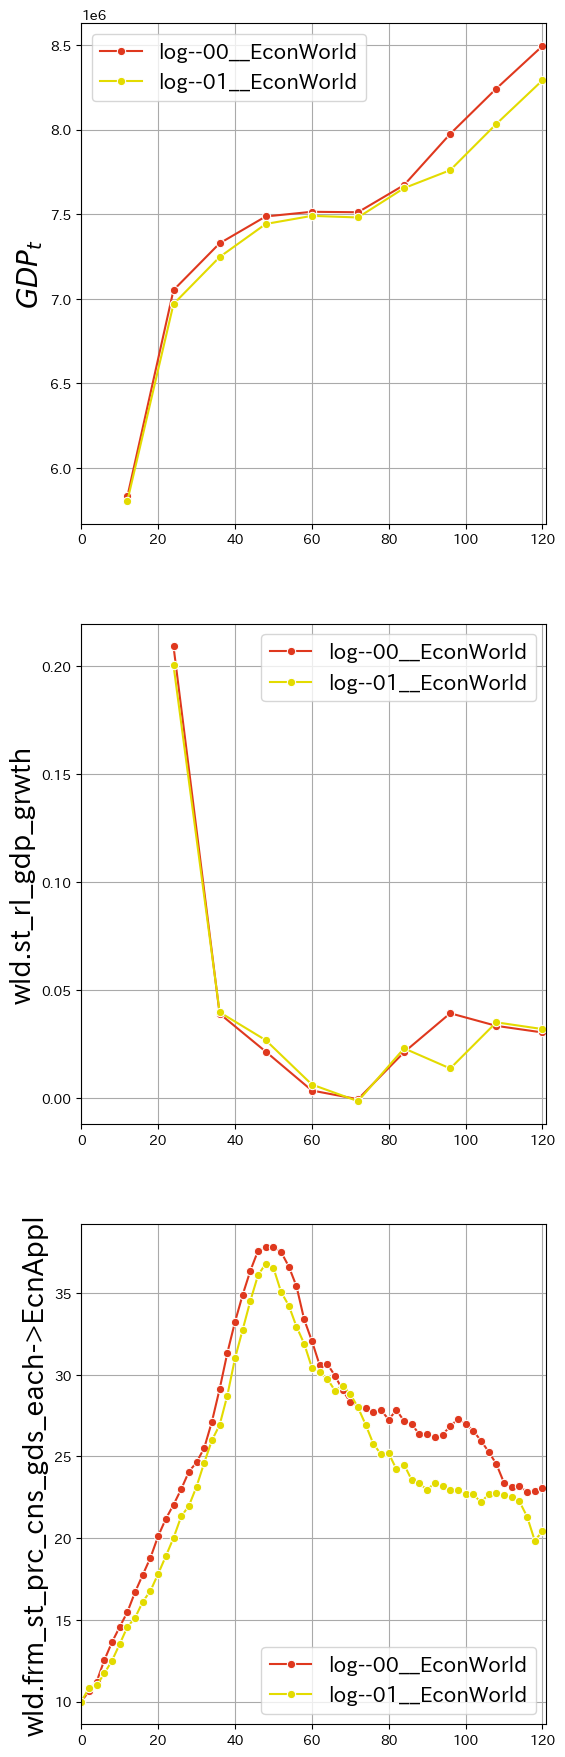

Cell executed in 2.197 s


In [13]:
_COLLECTIVE_COLS = [

    
#     # -------------------------- other states --------------------------
#     # 'st_n_households',
#     # 'st_n_firms',
#     # 'st_n_government',
#     # 'st_nominal_gdp',
     'st_real_gdp',
     'st_real_gdp_growth',

     'frm_st_price_cons_goods_each->EconApple',
# 
#     # -------------------------- states from firm --------------------------
#     'frm_st_prod_all_goods_agg',
#     'frm_st_prod_cons_goods_agg',
#     'frm_st_prod_cap_goods_agg',
#     'frm_st_labor_stock_cap_goods_agg_ratio',
# 
# 
#     'frm_st_prod_cons_goods_each->EconApple',
#     'frm_st_prod_cons_goods_each->EconBanana',
#     'frm_st_prod_cons_goods_each->EconOrange',
#     'frm_st_prod_cons_goods_each->EconLemon',
#     'frm_st_prod_cons_goods_each->EconPeach',
# 
# 
#     'frm_st_labor_stock_all_goods_each->EconApple',
#     'frm_st_labor_stock_all_goods_each->EconBanana',
#     'frm_st_labor_stock_all_goods_each->EconOrange',
#     'frm_st_labor_stock_all_goods_each->EconLemon',
#     'frm_st_labor_stock_all_goods_each->EconPeach',
# 
# 
#     'frm_st_cap_stock_all_goods_each->EconApple',
#     'frm_st_cap_stock_all_goods_each->EconBanana',
#     'frm_st_cap_stock_all_goods_each->EconOrange',
#     'frm_st_cap_stock_all_goods_each->EconLemon',
#     'frm_st_cap_stock_all_goods_each->EconPeach',
# 
# 
# 
#     'frm_st_idea_stock_all_goods_each->EconApple',
#     'frm_st_idea_stock_all_goods_each->EconBanana',
#     'frm_st_idea_stock_all_goods_each->EconOrange',
#     'frm_st_idea_stock_all_goods_each->EconLemon',
#     'frm_st_idea_stock_all_goods_each->EconPeach',
# 
# 
#       
#     
# 
#     
# 
#     # 'frm_st_growth_accounting_accum_goods_labor_cons_goods_agg',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->Breakfast',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->Lunch',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->Dinner',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->MovieTicket',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->SportsEventTicket',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->PaperbackBook',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->VideoGameNewRelease',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->LocalDayTripBudget',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->CapitalGoods',
# # 
#     # 'frm_st_growth_accounting_accum_goods_labor_cap_goods_agg',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->BreakfastCafeKitchenKit',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->LunchFastCasualPrepKitchenKit',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->DinnerFullServiceKitchenKit',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->MidRangeRestaurantFrontAndBackOfHouseKit',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->HouseholdConsumablesKittingAndPackagingCell',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->SingleScreenCinemaOperationsPackage',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->SmallSportsVenueEventOperationsKit',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->PrintOnDemandPaperbackProductionKit',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->IndieGameStudioComputeAndToolingBundle',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->DayTripOperatorVehicleAndBookingKit',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->GenericCapitalGoodsCapital',
#  # 
#     # 
#    # 
#     # 'frm_st_labor_stock_cons_goods_agg',
#     # 'frm_st_labor_stock_all_goods_each->Breakfast',
#     # 'frm_st_labor_stock_all_goods_each->Lunch',
#     # 'frm_st_labor_stock_all_goods_each->Dinner',
#     # 'frm_st_labor_stock_all_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_labor_stock_all_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_labor_stock_all_goods_each->MovieTicket',
#     # 'frm_st_labor_stock_all_goods_each->SportsEventTicket',
#     # 'frm_st_labor_stock_all_goods_each->PaperbackBook',
#     # 'frm_st_labor_stock_all_goods_each->VideoGameNewRelease',
#     # 'frm_st_labor_stock_all_goods_each->LocalDayTripBudget',
#     # 'frm_st_labor_stock_all_goods_each->CapitalGoods',
# # 
#     # 'frm_st_labor_stock_cap_goods_agg',
#     # 'frm_st_labor_stock_all_goods_each->BreakfastCafeKitchenKit',
#     # 'frm_st_labor_stock_all_goods_each->LunchFastCasualPrepKitchenKit',
#     # 'frm_st_labor_stock_all_goods_each->DinnerFullServiceKitchenKit',
#     # 'frm_st_labor_stock_all_goods_each->MidRangeRestaurantFrontAndBackOfHouseKit',
#     # 'frm_st_labor_stock_all_goods_each->HouseholdConsumablesKittingAndPackagingCell',
#     # 'frm_st_labor_stock_all_goods_each->SingleScreenCinemaOperationsPackage',
#     # 'frm_st_labor_stock_all_goods_each->SmallSportsVenueEventOperationsKit',
#     # 'frm_st_labor_stock_all_goods_each->PrintOnDemandPaperbackProductionKit',
#     # 'frm_st_labor_stock_all_goods_each->IndieGameStudioComputeAndToolingBundle',
#     # 'frm_st_labor_stock_all_goods_each->DayTripOperatorVehicleAndBookingKit',
#     # 'frm_st_labor_stock_all_goods_each->GenericCapitalGoodsCapital',
# # 
# # 
# # 
#     # 'frm_st_labor_stock_dirichlet_cons_goods_agg',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->Breakfast',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->Lunch',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->Dinner',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->MovieTicket',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->SportsEventTicket',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->PaperbackBook',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->VideoGameNewRelease',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->LocalDayTripBudget',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->CapitalGoods',
# # 
#     # 'frm_st_labor_stock_dirichlet_cap_goods_agg',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->BreakfastCafeKitchenKit',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->LunchFastCasualPrepKitchenKit',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->DinnerFullServiceKitchenKit',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->MidRangeRestaurantFrontAndBackOfHouseKit',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->HouseholdConsumablesKittingAndPackagingCell',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->SingleScreenCinemaOperationsPackage',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->SmallSportsVenueEventOperationsKit',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->PrintOnDemandPaperbackProductionKit',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->IndieGameStudioComputeAndToolingBundle',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->DayTripOperatorVehicleAndBookingKit',
#     # 'frm_st_labor_stock_dirichlet_all_goods_each->GenericCapitalGoodsCapital',
#  
# 
# 
#     # 'frm_st_demand_n_cons_goods_agg',
#     # 'frm_st_demand_n_cons_goods_each->Breakfast',
#     # 'frm_st_demand_n_cons_goods_each->Lunch',
#     # 'frm_st_demand_n_cons_goods_each->Dinner',
#     # 'frm_st_demand_n_cons_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_demand_n_cons_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_demand_n_cons_goods_each->MovieTicket',
#     # 'frm_st_demand_n_cons_goods_each->SportsEventTicket',
#     # 'frm_st_demand_n_cons_goods_each->PaperbackBook',
#     # 'frm_st_demand_n_cons_goods_each->VideoGameNewRelease',
#     # 'frm_st_demand_n_cons_goods_each->LocalDayTripBudget',
#     # 'frm_st_demand_n_cons_goods_each->CapitalGoods',
#     # 
#     # 'frm_st_demand_n_cap_goods_agg',
#     # 'frm_st_demand_n_cap_goods_each->BreakfastCafeKitchenKit',
#     # 'frm_st_demand_n_cap_goods_each->LunchFastCasualPrepKitchenKit',
#     # 'frm_st_demand_n_cap_goods_each->DinnerFullServiceKitchenKit',
#     # 'frm_st_demand_n_cap_goods_each->MidRangeRestaurantFrontAndBackOfHouseKit',
#     # 'frm_st_demand_n_cap_goods_each->HouseholdConsumablesKittingAndPackagingCell',
#     # 'frm_st_demand_n_cap_goods_each->SingleScreenCinemaOperationsPackage',
#     # 'frm_st_demand_n_cap_goods_each->SmallSportsVenueEventOperationsKit',
#     # 'frm_st_demand_n_cap_goods_each->PrintOnDemandPaperbackProductionKit',
#     # 'frm_st_demand_n_cap_goods_each->IndieGameStudioComputeAndToolingBundle',
#     # 'frm_st_demand_n_cap_goods_each->DayTripOperatorVehicleAndBookingKit',
#     'frm_st_demand_n_cap_goods_each->GenericCapitalGoodsCapital',
# 
# 
# 
#     # 'frm_st_stock_cons_goods_agg',
#     # 'frm_st_stock_cons_goods_each->Breakfast',
#     # 'frm_st_stock_cons_goods_each->Lunch',
#     # 'frm_st_stock_cons_goods_each->Dinner',
#     # 'frm_st_stock_cons_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_stock_cons_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_stock_cons_goods_each->MovieTicket',
#     # 'frm_st_stock_cons_goods_each->SportsEventTicket',
#     # 'frm_st_stock_cons_goods_each->PaperbackBook',
#     # 'frm_st_stock_cons_goods_each->VideoGameNewRelease',
#     # 'frm_st_stock_cons_goods_each->LocalDayTripBudget',
#     # 'frm_st_stock_cons_goods_each->CapitalGoods',
#     # 
#     # 'frm_st_stock_cap_goods_agg',
#     # 'frm_st_stock_cap_goods_each->BreakfastCafeKitchenKit',
#     # 'frm_st_stock_cap_goods_each->LunchFastCasualPrepKitchenKit',
#     # 'frm_st_stock_cap_goods_each->DinnerFullServiceKitchenKit',
#     # 'frm_st_stock_cap_goods_each->MidRangeRestaurantFrontAndBackOfHouseKit',
#     # 'frm_st_stock_cap_goods_each->HouseholdConsumablesKittingAndPackagingCell',
#     # 'frm_st_stock_cap_goods_each->SingleScreenCinemaOperationsPackage',
#     # 'frm_st_stock_cap_goods_each->SmallSportsVenueEventOperationsKit',
#     # 'frm_st_stock_cap_goods_each->PrintOnDemandPaperbackProductionKit',
#     # 'frm_st_stock_cap_goods_each->IndieGameStudioComputeAndToolingBundle',
#     # 'frm_st_stock_cap_goods_each->DayTripOperatorVehicleAndBookingKit',
#     # 'frm_st_stock_cap_goods_each->GenericCapitalGoodsCapital',
#  # 
# # 
# # 
#     # 'frm_st_price_cons_goods_agg',
#     # 'frm_st_price_cons_goods_each->Breakfast',
#     # 'frm_st_price_cons_goods_each->Lunch',
#     # 'frm_st_price_cons_goods_each->Dinner',
#     # 'frm_st_price_cons_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_price_cons_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_price_cons_goods_each->MovieTicket',
#     # 'frm_st_price_cons_goods_each->SportsEventTicket',
#     # 'frm_st_price_cons_goods_each->PaperbackBook',
#     # 'frm_st_price_cons_goods_each->VideoGameNewRelease',
#     # 'frm_st_price_cons_goods_each->LocalDayTripBudget',
#     # 'frm_st_price_cons_goods_each->CapitalGoods',
#     # 
#     # 
#     # 'frm_st_price_cap_goods_agg',
#     # 'frm_st_price_cap_goods_each->BreakfastCafeKitchenKit',
#     # 'frm_st_price_cap_goods_each->LunchFastCasualPrepKitchenKit',
#     # 'frm_st_price_cap_goods_each->DinnerFullServiceKitchenKit',
#     # 'frm_st_price_cap_goods_each->MidRangeRestaurantFrontAndBackOfHouseKit',
#     # 'frm_st_price_cap_goods_each->HouseholdConsumablesKittingAndPackagingCell',
#     # 'frm_st_price_cap_goods_each->SingleScreenCinemaOperationsPackage',
#     # 'frm_st_price_cap_goods_each->SmallSportsVenueEventOperationsKit',
#     # 'frm_st_price_cap_goods_each->PrintOnDemandPaperbackProductionKit',
#     # 'frm_st_price_cap_goods_each->IndieGameStudioComputeAndToolingBundle',
#     # 'frm_st_price_cap_goods_each->DayTripOperatorVehicleAndBookingKit',
#     # 'frm_st_price_cap_goods_each->GenericCapitalGoodsCapital',
#     # 
#     # 'frm_st_wage',
# 
# 
# 
#     # 'frm_st_sale_n_cons_goods_agg',
#     # 'frm_st_sale_n_cons_goods_each->Breakfast',
#     # 'frm_st_sale_n_cons_goods_each->Lunch',
#     # 'frm_st_sale_n_cons_goods_each->Dinner',
#     # 'frm_st_sale_n_cons_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_sale_n_cons_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_sale_n_cons_goods_each->MovieTicket',
#     # 'frm_st_sale_n_cons_goods_each->SportsEventTicket',
#     # 'frm_st_sale_n_cons_goods_each->PaperbackBook',
#     # 'frm_st_sale_n_cons_goods_each->VideoGameNewRelease',
#     # 'frm_st_sale_n_cons_goods_each->LocalDayTripBudget',
#     # 'frm_st_sale_n_cons_goods_each->CapitalGoods',
#     
#     # 'frm_st_sale_n_cap_goods_agg',
#     # 'frm_st_sale_n_cap_goods_each->BreakfastCafeKitchenKit',
#     # 'frm_st_sale_n_cap_goods_each->LunchFastCasualPrepKitchenKit',
#     # 'frm_st_sale_n_cap_goods_each->DinnerFullServiceKitchenKit',
#     # 'frm_st_sale_n_cap_goods_each->MidRangeRestaurantFrontAndBackOfHouseKit',
#     # 'frm_st_sale_n_cap_goods_each->HouseholdConsumablesKittingAndPackagingCell',
#     # 'frm_st_sale_n_cap_goods_each->SingleScreenCinemaOperationsPackage',
#     # 'frm_st_sale_n_cap_goods_each->SmallSportsVenueEventOperationsKit',
#     # 'frm_st_sale_n_cap_goods_each->PrintOnDemandPaperbackProductionKit',
#     # 'frm_st_sale_n_cap_goods_each->IndieGameStudioComputeAndToolingBundle',
#     # 'frm_st_sale_n_cap_goods_each->DayTripOperatorVehicleAndBookingKit',
#     # 'frm_st_sale_n_cap_goods_each->GenericCapitalGoodsCapital',
#  
#     
#    
# 
#     'frm_st_labor_stock_cons_goods_agg_ratio',
#     'frm_st_labor_stock_cap_goods_agg_ratio',
#     'frm_st_labor_stock_all_goods_agg_ratio',
# 
# 
# 
# 
#     
#     
#     
#     # 'frm_st_prod_cons_goods_each->Breakfast',
#     # 'frm_st_prod_cons_goods_each->Lunch',
#     # 'frm_st_prod_cons_goods_each->Dinner',
#     # 'frm_st_prod_cons_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_prod_cons_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_prod_cons_goods_each->MovieTicket',
#     # 'frm_st_prod_cons_goods_each->SportsEventTicket',
#     # 'frm_st_prod_cons_goods_each->PaperbackBook',
#     # 'frm_st_prod_cons_goods_each->VideoGameNewRelease',
#     # 'frm_st_prod_cons_goods_each->LocalDayTripBudget',
#     # 'frm_st_prod_cap_goods_each->CapitalGoods',
#     # 'frm_st_prod_cap_goods_agg',
#     # 
#     # 'frm_st_prod_cap_goods_each->CapitalGoods',
#     # 'frm_st_prod_cap_goods_each->BreakfastCapital',
#     # 'frm_st_prod_cap_goods_each->LunchCapital',
#     # 'frm_st_prod_cap_goods_each->DinnerCapital',
#     # 'frm_st_prod_cap_goods_each->MidRangeRestaurantDinnerCapital',
#     # 'frm_st_prod_cap_goods_each->DailyHouseholdConsumablesBundleCapital',
#     # 'frm_st_prod_cap_goods_each->MovieTicketCapital',
#     # 'frm_st_prod_cap_goods_each->SportsEventTicketCapital',
#     # 'frm_st_prod_cap_goods_each->PaperbackBookCapital',
#     # 'frm_st_prod_cap_goods_each->VideoGameNewReleaseCapital',
#     # 'frm_st_prod_cap_goods_each->LocalDayTripBudgetCapital',
#     # 'frm_st_prod_cap_goods_each->GenericCapitalGoodsCapital',
# # 
#     # 
#     # 'frm_st_price_cap_goods_each->CapitalGoods',
#     # 'frm_st_price_cap_goods_each->BreakfastCapital',
#     # 'frm_st_price_cap_goods_each->LunchCapital',
#     # 'frm_st_price_cap_goods_each->DinnerCapital',
#     # 'frm_st_price_cap_goods_each->MidRangeRestaurantDinnerCapital',
#     # 'frm_st_price_cap_goods_each->DailyHouseholdConsumablesBundleCapital',
#     # 'frm_st_price_cap_goods_each->MovieTicketCapital',
#     # 'frm_st_price_cap_goods_each->SportsEventTicketCapital',
#     # 'frm_st_price_cap_goods_each->PaperbackBookCapital',
#     # 'frm_st_price_cap_goods_each->VideoGameNewReleaseCapital',
#     # 'frm_st_price_cap_goods_each->LocalDayTripBudgetCapital',
#     # 'frm_st_price_cap_goods_each->GenericCapitalGoodsCapital',
# # 
#     # 
#     # 'frm_st_labor_stock_all_goods_agg',
#     # 'frm_st_labor_stock_cons_goods_agg',
#     # 'frm_st_labor_stock_cap_goods_agg',
#     # 'frm_st_labor_stock_cap_goods_agg_ratio',
# 
# 
# 
# 
#     
#     # 'frm_st_goods_labor_factor_cons_goods_each->Breakfast',
#     # 'frm_st_goods_labor_factor_cons_goods_each->Lunch',
#     # 'frm_st_goods_labor_factor_cons_goods_each->Dinner',
#     # 'frm_st_goods_labor_factor_cons_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_goods_labor_factor_cons_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_goods_labor_factor_cons_goods_each->MovieTicket',
#     # 'frm_st_goods_labor_factor_cons_goods_each->SportsEventTicket',
#     # 'frm_st_goods_labor_factor_cons_goods_each->PaperbackBook',
#     # 'frm_st_goods_labor_factor_cons_goods_each->VideoGameNewRelease',
#     # 'frm_st_goods_labor_factor_cons_goods_each->LocalDayTripBudget',
#     # 'frm_st_goods_labor_factor_cap_goods_each->CapitalGoods',
# 
# 
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->Breakfast',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->Lunch',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->Dinner',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->MovieTicket',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->SportsEventTicket',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->PaperbackBook',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->VideoGameNewRelease',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->LocalDayTripBudget',
#     # 'frm_st_growth_accounting_accum_goods_labor_all_goods_each->CapitalGoods',
# # 
# # 
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->Breakfast',
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->Lunch',
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->Dinner',
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->MovieTicket',
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->SportsEventTicket',
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->PaperbackBook',
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->VideoGameNewRelease',
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->LocalDayTripBudget',
#     # 'frm_st_growth_accounting_accum_cap_all_goods_each->CapitalGoods',
# # 
# # 
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->Breakfast',
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->Lunch',
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->Dinner',
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->MovieTicket',
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->SportsEventTicket',
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->PaperbackBook',
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->VideoGameNewRelease',
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->LocalDayTripBudget',
#     # 'frm_st_growth_accounting_accum_idea_all_goods_each->CapitalGoods',
# # 
#     # 
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->Breakfast',
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->Lunch',
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->Dinner',
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->MovieTicket',
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->SportsEventTicket',
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->PaperbackBook',
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->VideoGameNewRelease',
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->LocalDayTripBudget',
#     # 'frm_st_growth_accounting_accum_share_all_goods_each->CapitalGoods',
# 
# 
#  
# 
#     # 'frm_st_cap_factor_cons_goods_each->Breakfast',
#     # 'frm_st_cap_factor_cons_goods_each->Lunch',
#     # 'frm_st_cap_factor_cons_goods_each->Dinner',
#     # 'frm_st_cap_factor_cons_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_cap_factor_cons_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_cap_factor_cons_goods_each->MovieTicket',
#     # 'frm_st_cap_factor_cons_goods_each->SportsEventTicket',
#     # 'frm_st_cap_factor_cons_goods_each->PaperbackBook',
#     # 'frm_st_cap_factor_cons_goods_each->VideoGameNewRelease',
#     # 'frm_st_cap_factor_cons_goods_each->LocalDayTripBudget',
#     # 'frm_st_cap_factor_cap_goods_each->CapitalGoods',
# # 
# # 
# # 
#     # 'frm_st_idea_factor_cons_goods_each->Breakfast',
#     # 'frm_st_idea_factor_cons_goods_each->Lunch',
#     # 'frm_st_idea_factor_cons_goods_each->Dinner',
#     # 'frm_st_idea_factor_cons_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_idea_factor_cons_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_idea_factor_cons_goods_each->MovieTicket',
#     # 'frm_st_idea_factor_cons_goods_each->SportsEventTicket',
#     # 'frm_st_idea_factor_cons_goods_each->PaperbackBook',
#     # 'frm_st_idea_factor_cons_goods_each->VideoGameNewRelease',
#     # 'frm_st_idea_factor_cons_goods_each->LocalDayTripBudget',
#     # 'frm_st_idea_factor_cap_goods_each->CapitalGoods',
#     
#     # 'frm_st_goods_labor_factor_norm_all_goods_agg',
#     # 'frm_st_goods_labor_factor_norm_cons_goods_agg',
#     # 'frm_st_goods_labor_factor_norm_cap_goods_agg',
#     
#     # 'frm_st_labor_stock_cons_goods_each->EconApple',
#     # 'frm_st_labor_stock_cons_goods_each->EconBanana',
#     # 'frm_st_labor_stock_cons_goods_each->EconOrange',
#     # 'frm_st_labor_stock_cons_goods_each->EconLemon',
#     # 'frm_st_labor_stock_cons_goods_each->EconPeach',
# 
#     # 'frm_st_stock_cons_goods_each->Breakfast',
#     # 'frm_st_stock_cons_goods_each->Lunch',
#     # 'frm_st_stock_cons_goods_each->Dinner',
#     # 'frm_st_stock_cons_goods_each->MidRangeRestaurantDinner',
#     # 'frm_st_stock_cons_goods_each->DailyHouseholdConsumablesBundle',
#     # 'frm_st_stock_cons_goods_each->MovieTicket',
#     # 'frm_st_stock_cons_goods_each->SportsEventTicket',
#     # 'frm_st_stock_cons_goods_each->PaperbackBook',
#     # 'frm_st_stock_cons_goods_each->VideoGameNewRelease',
#     # 'frm_st_stock_cons_goods_each->LocalDayTripBudget',   
#     # 'frm_st_stock_cap_goods_each->CapitalGoods',   
# 
#     
#     # 'frm_st_cap_factor_norm_all_goods_agg',
#     # 'frm_st_cap_factor_norm_cons_goods_agg',
#     # 'frm_st_cap_factor_norm_cap_goods_agg',
#     
# #     'frm_st_cap_stock_all_goods_agg',
# #     'frm_st_cap_stock_cons_goods_agg',
# #     'frm_st_cap_stock_cap_goods_agg',
# # 
# # 
# #     # 'frm_st_cap_stock_cons_goods_each->EconApple',
# #     # 'frm_st_cap_stock_cons_goods_each->EconBanana',
# #     # 'frm_st_cap_stock_cons_goods_each->EconOrange',
# #     # 'frm_st_cap_stock_cons_goods_each->EconLemon',
# #     # 'frm_st_cap_stock_cons_goods_each->EconPeach',
# # 
# #     'frm_st_cap_stock_cons_goods_each->Breakfast',
# #     'frm_st_cap_stock_cons_goods_each->Lunch',
# #     'frm_st_cap_stock_cons_goods_each->Dinner',
# #     'frm_st_cap_stock_cons_goods_each->MidRangeRestaurantDinner',
# #     'frm_st_cap_stock_cons_goods_each->DailyHouseholdConsumablesBundle',
# #     'frm_st_cap_stock_cons_goods_each->MovieTicket',
# #     'frm_st_cap_stock_cons_goods_each->SportsEventTicket',
# #     'frm_st_cap_stock_cons_goods_each->PaperbackBook',
# #     'frm_st_cap_stock_cons_goods_each->VideoGameNewRelease',
# #     'frm_st_cap_stock_cons_goods_each->LocalDayTripBudget',   
# # 
# #     
# #     
# #     'frm_st_idea_factor_norm_all_goods_agg',
# #     'frm_st_idea_factor_norm_cons_goods_agg',
# #     'frm_st_idea_factor_norm_cap_goods_agg',
# #     
# #     'frm_st_idea_stock_all_goods_agg',
# #     'frm_st_idea_stock_cons_goods_agg',
# #     'frm_st_idea_stock_idea_goods',
# # 
# # 
# #     # 'frm_st_idea_stock_cons_goods_each->EconApple',
# #     # 'frm_st_idea_stock_cons_goods_each->EconBanana',
# #     # 'frm_st_idea_stock_cons_goods_each->EconOrange',
# #     # 'frm_st_idea_stock_cons_goods_each->EconLemon',
# #     # 'frm_st_idea_stock_cons_goods_each->EconPeach',
# # 
# #     'frm_st_idea_stock_cons_goods_each->Breakfast',
# #     'frm_st_idea_stock_cons_goods_each->Lunch',
# #     'frm_st_idea_stock_cons_goods_each->Dinner',
# #     'frm_st_idea_stock_cons_goods_each->MidRangeRestaurantDinner',
# #     'frm_st_idea_stock_cons_goods_each->DailyHouseholdConsumablesBundle',
# #     'frm_st_idea_stock_cons_goods_each->MovieTicket',
# #     'frm_st_idea_stock_cons_goods_each->SportsEventTicket',
# #     'frm_st_idea_stock_cons_goods_each->PaperbackBook',
# #     'frm_st_idea_stock_cons_goods_each->VideoGameNewRelease',
# #     'frm_st_idea_stock_cons_goods_each->LocalDayTripBudget',   
# # 
# #     
# #     
# #     
# #     'frm_st_price_cons_goods_agg',
# #     # 'frm_st_price_cons_goods_agg_change_factor_all_goods_agg',
# #     'frm_st_stock_cons_goods_agg',
# #     'frm_st_prod_cons_goods_agg',
# #     'frm_st_demand_n_cons_goods_agg',
# #     'frm_st_cons_goods_gap',
# #     'hsld_st_demand_n_cons_goods_agg',
# #     # 'frm_st_cons_goods_shortage',
# #     'frm_st_sale_n_cons_goods_agg',
# # 
# #     'frm_st_price_cap_goods_agg',
# #     # 'frm_st_price_cap_goods_agg_change_factor_all_goods_agg',
# #     'frm_st_stock_cap_goods_agg',
# #     'frm_st_prod_cap_goods_agg',
# #     'frm_st_demand_n_cap_goods_agg',
# #     'frm_st_cap_goods_gap',
# #     'frm_st_n_cap_investment_ratio_decision',
# #     # 'frm_st_cap_goods_shortage',
# #     'frm_st_sale_n_cap_goods_agg',
# #     
# #     'frm_st_all_goods_sale_cash_agg',
# #     'frm_st_sale_cash_cons_goods_agg',
# #     'frm_st_sale_cash_cap_goods_agg',
# #     
# #     'frm_st_personnel_cost',
# #     # 'frm_goods_labor_cash_flow_incl_household_investment',
# #     'frm_st_cash_flow',   # 2025-10-04
# #     
# #     # 'frm_st_cash_flow',
# #     # 'frm_st_financial_cash_flow',
# #     # 'frm_st_bond_flow',
# #     
# # 
# #     
# #     'frm_st_cash_balance_excl_debt_before_cap_investment',
# #     
# #     # 'frm_st_cap_investment',
# #     # 'frm_st_cap_investment_ratio',
# #     # 'frm_st_cap_investment_ratio_original_decision_micro',
# #     # 'frm_st_cap_investment_ratio_original_decision_macro',
# # 
# #     # 'frm_st_cap_investment_ratio_decision',
# #     'frm_st_cash_balance',
# #     'frm_st_cap_investment_cash_actual',
# #     'frm_st_cap_investment_ratio',
# #     'frm_st_cap_investment_ratio_decision_micro_avg',
# #     'frm_st_cap_investment_ratio_decision_micro_avg_weighted',
# #     # 'frm_st_cap_investment_ratio_actual_micro_avg',
# #     # 'frm_st_cap_investment_ratio_actual_micro_avg_weighted',
# #     
# # 
# # 
# #     
# #     'frm_st_cash_balance_excl_debt',
# #     'frm_st_cash_balance_pre_cap_investment',
# #     
# # 
# #     
# #     
# #     # 'frm_st_total_balance',
# #     # 'frm_st_cash_balance',
# #     # 'frm_st_bond_balance',
# #     
# # 
# # 
# #    
# #     
# #     'frm_st_wage',
# #     # 'frm_st_wage_change_factor_all_goods_agg',
# #     
# #     # 'frm_st_n_employees',
# # 
# #     
# #     # -------------------------- states from household --------------------------
# #     'hsld_st_income',
# #     
# #     'hsld_st_total_consump',
# #     # 'hsld_st_fixed_expense',
# #     # 'hsld_st_consump_cash_agg',
# #     'hsld_st_n_consump',
# #     # 'hsld_st_demand_n_cons_goods_agg',
# #     
# #     'hsld_st_wage',
# #     
# #     # 'hsld_st_willingness_to_work',
# #     # 'hsld_st_demand_n_cons_goods_agg',
# #     
# #     # 'hsld_st_cash_flow',
# #     # 'hsld_st_financial_cash_flow',
# #     # 'hsld_st_bond_flow',
# #     
# #     'hsld_st_monthly_saving',
# #     'hsld_st_monthly_saving_rate',
# # 
#      'hsld_st_cash_balance',
# #     
# #     # 'hsld_st_total_balance',
# #     # 'hsld_st_cash_balance',
# #     # 'hsld_st_bond_balance',
# # 
# #  
# #     # 'hsld_st_demand_n_cons_goods_agg',
# #     # 'hsld_st_total_consump',
# #     # 'hsld_st_n_consump',
# #     # 'hsld_st_fixed_expense',
# #     # 'hsld_st_wage',
# #     # 'hsld_st_labor_stock_all_goods_agg',
# #     
# #     'hsld_st_willingness_to_work',
# #     'hsld_st_demand_n_cons_goods_agg',
]

WORLD_COLS = [f'wld.{col}' for col in _COLLECTIVE_COLS]


if DO_DEV_PLOT:
    plot_dfs(world_dfs,
             WORLD_COLS,
             other_run_dfs=other_run_world_dfs,
             colors=COLORS)

# Collectives (i.e., world, country)

In [14]:
def save_fig(axes, output_dir, filename):
    output_pdf_path = Path(output_dir) / f'{filename}.pdf' if filename is not None else None
    if output_pdf_path is not None:
        output_pdf_path = Path(output_pdf_path)
        output_pdf_path.parent.mkdir(exist_ok=True, parents=True)
        try:
            ax = axes[0][0]
        except:
            try:
                ax = axes[0]
            except:
                ax = axes
        ax.figure.savefig(output_pdf_path, format='pdf', bbox_inches='tight', pad_inches=0.0)


def plot_dfs_with_right(dfs,
                        left_col: Union[str, List[str]],
                        left_ylim: Optional[Tuple[float, float]] = None,
                        left_ylim_scale: Optional[str] = None,
                        right_col: Optional[str] = None,
                        right_ylim: Optional[str] = None,
                        right_ylim_scale: Optional[str] = None,
                        df_labels: Optional[List[str]]='auto',
                        output_dir: Optional[str] = None,
                        targets: List[str] = [],
                        legend_size=8,
                        legend_order=None,
                        tight_layout_pad=TIGHT_LAYOUT_PAD,
                        hetero_plot=False,
                        colors=None,
                        other_run_dfs=None,
                        **kwargs):
    colors = colors or ([None] * len(dfs))
    dfs, other_run_dfs, df_labels, colors = dfs_dict_to_list(dfs, other_run_dfs=other_run_dfs, labels=df_labels, colors=colors)

    def scale_axis(ax):
        def maybe(val: Optional[float], default: float) -> float:
            if val is None:
                return default
            else:
                return val

        if left_ylim is not None:
            ax.set_ylim(maybe(left_ylim[0], ax.get_ylim()[0]),
                        maybe(left_ylim[1], ax.get_ylim()[1]))

        if left_ylim_scale is not None:
            ax.set_ylim(ax.get_ylim()[0] * maybe(left_ylim_scale[0], 1.0),
                        ax.get_ylim()[1] * maybe(left_ylim_scale[1], 1.0))

        ax_right = get_right_axis(ax)

        if ax_right is not None and right_ylim is not None:
            ax_right.set_ylim(maybe(right_ylim[0], ax_right.get_ylim()[0]),
                              maybe(right_ylim[1], ax_right.get_ylim()[1]))

        if ax_right is not None and right_ylim_scale is not None:
            ax_right = get_right_axis(ax)
            if ax_right is not None:
                ax_right.set_ylim(ax_right.get_ylim()[0] * maybe(right_ylim_scale[0], 1.0),
                                  ax_right.get_ylim()[1] * maybe(right_ylim_scale[1], 1.0))

        if ax_right is not None and kwargs.get('left_right_same_scale', False):
            ax_right.set_ylim(ax.get_ylim()[0], ax.get_ylim()[1])

    def make_name(target: str) -> str:
        # return f'df--{target}__col--{"__".join([str(c) for c in [left_col, right_col]])}'
        left_col_rep = left_col if isinstance(left_col, str) else '__'.join(left_col)
        return f'{"__".join([str(c) for c in [left_col_rep, right_col]])}.{"hetero_plot." if hetero_plot else ""}df--{target}'

    for target in targets:
        if '+' in target or target == 'all':
            continue
        idx = int(target)
        df = dfs[idx]
        _other_run_df = other_run_dfs[idx] if other_run_dfs is not None else None
        color = colors[idx]

        axes = plot_dfs(
            [df],
            [left_col] if isinstance(left_col, str) else left_col,
            right_cols=[right_col] if right_col is not None else None,
            separate_figures_for_dfs=True,
            colors=[color],
            legend_size=legend_size,
            legend_order=None,
            tight_layout_pad=tight_layout_pad,
            hetero_plot=hetero_plot,
            other_run_dfs=[_other_run_df],
            labels=None,
            **kwargs,
        )
        if not isinstance(axes, np.ndarray):
            scale_axis(axes)
        if output_dir is not None:
            save_fig(axes, output_dir, make_name(target))

    for target in targets:
        if '+' not in target and target != 'all':
            continue
        if target == 'all':
            idxs = range(len(dfs))
        else:
            idxs = [int(idx) for idx in target.split('+')]
        _labels = [df_labels[idx] for idx in idxs]
        axes = plot_dfs(
            [dfs[idx] for idx in idxs],
            [left_col] if isinstance(left_col, str) else left_col,
            # right_cols=[right_col],
            right_cols=[right_col] if right_col is not None else None,
            separate_figures_for_dfs=False,
            labels=_labels,
            colors=colors,
            legend_size=legend_size,
            legend_order=legend_order,
            tight_layout_pad=tight_layout_pad,
            hetero_plot=hetero_plot,
            other_run_dfs=other_run_dfs,
            **kwargs,
        )
        if not isinstance(axes, np.ndarray):
            scale_axis(axes)
        if output_dir is not None:
            save_fig(axes, output_dir, make_name(target))


def _plot_dfs_with_right_from_settings(dfs, settings: List[dict], output_dir=None, **kwargs):
    from copy import deepcopy
    settings = deepcopy(settings)
    for setting in settings:
        left_col = setting['left_col']
        setting.pop('left_col')
        plot_dfs_with_right(dfs, left_col, output_dir=output_dir, **setting, **kwargs)


def plot_dfs_with_right_from_settings(dfs,
                                      settings: List[dict],
                                      output_dir=None,
                                      no_label_for_output=False,
                                      do_legend_for_output=False,
                                      **kwargs):

    if output_dir is not None:
        try:
            old_backend = matplotlib.get_backend()
            plt.close('all')
            matplotlib.use('Agg')   # do not show

            _plot_dfs_with_right_from_settings(dfs, settings, output_dir=output_dir, no_label = no_label_for_output, no_legend=not do_legend_for_output, **kwargs)

            plt.close('all')
            matplotlib.use(old_backend)
        except Exception as e:
            print('[!!!!!!!!!!!!!!!!!!!!!!!!!!] After fixing the following error, reload ipynb as we have changed the backend but cannot restored.')
            raise

    _plot_dfs_with_right_from_settings(dfs, settings, output_dir=None, no_label=False, **kwargs)




Cell executed in 5.1 ms


# Ricardian trade

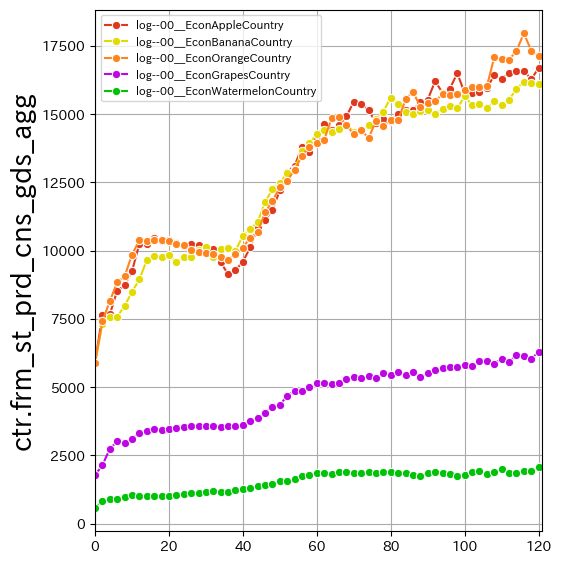

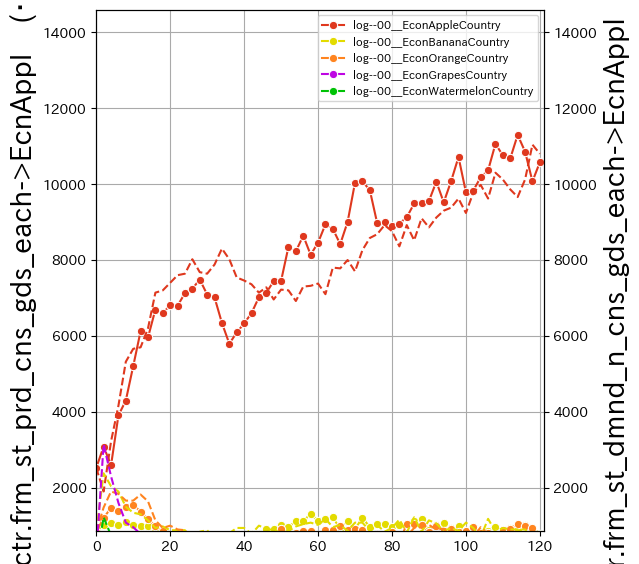

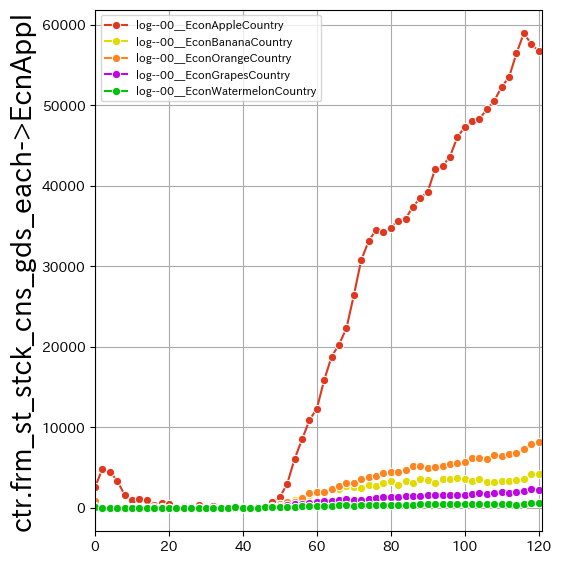

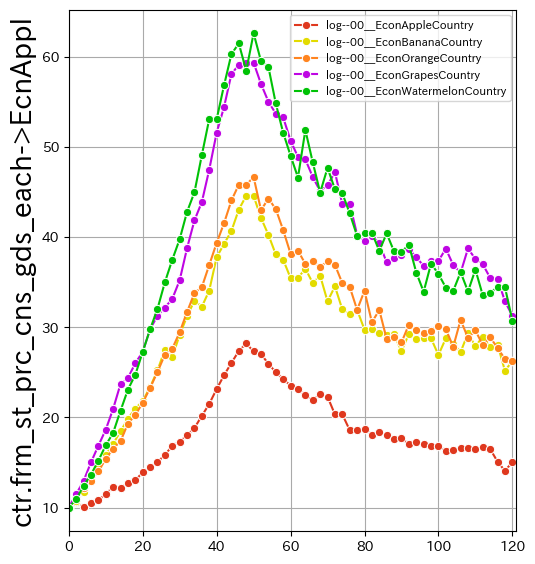

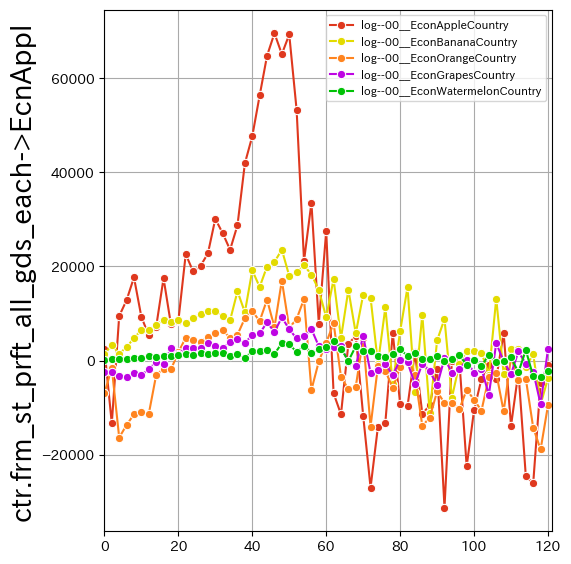

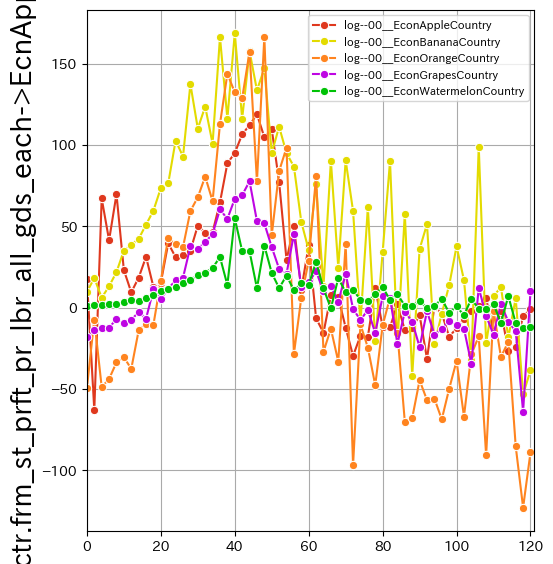

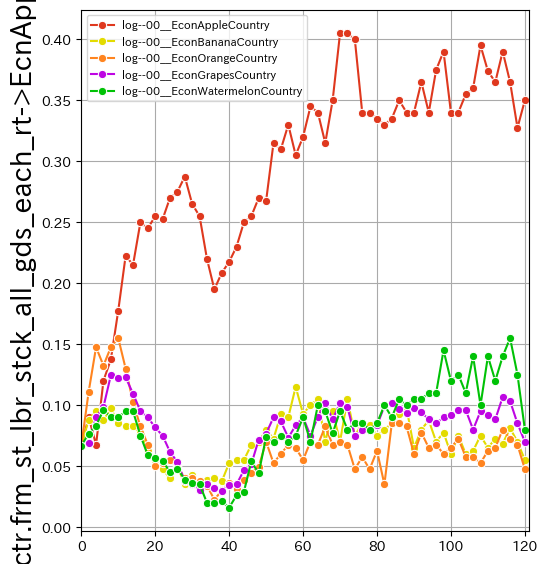

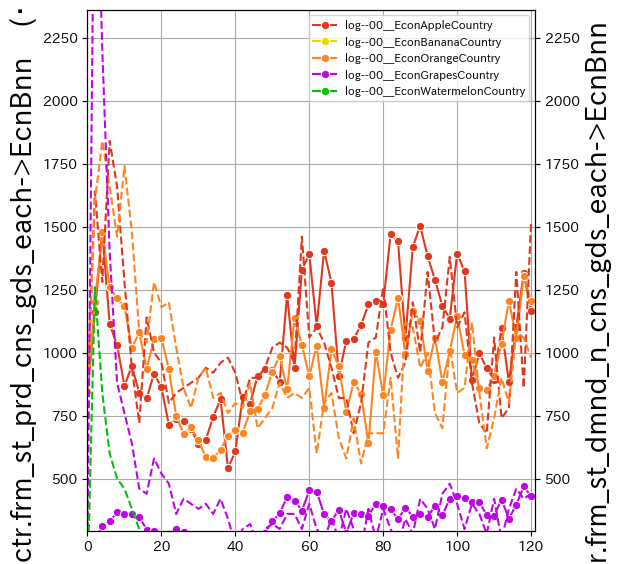

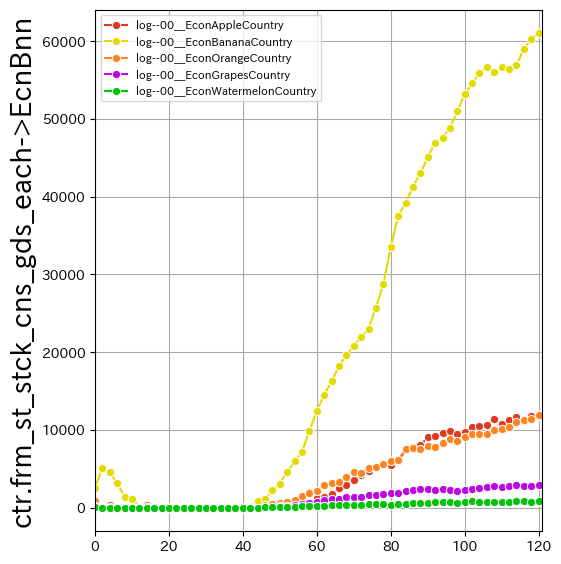

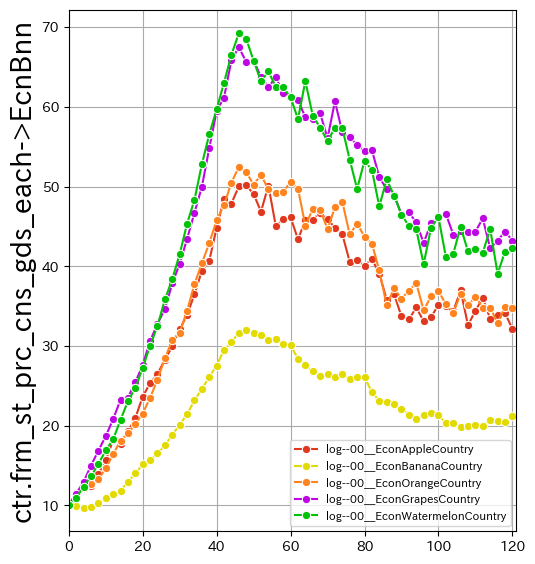

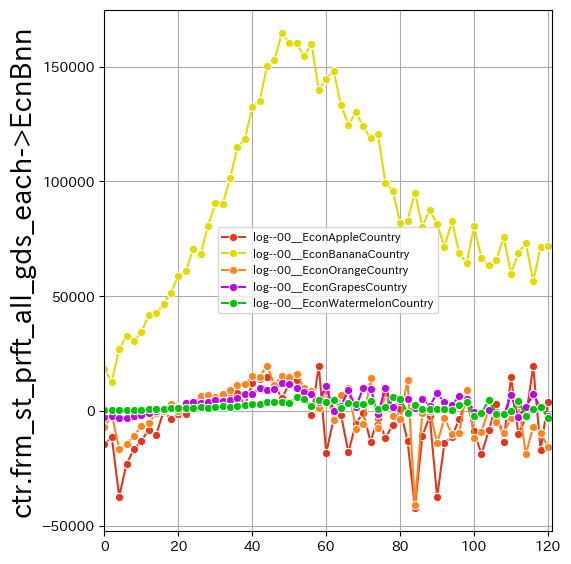

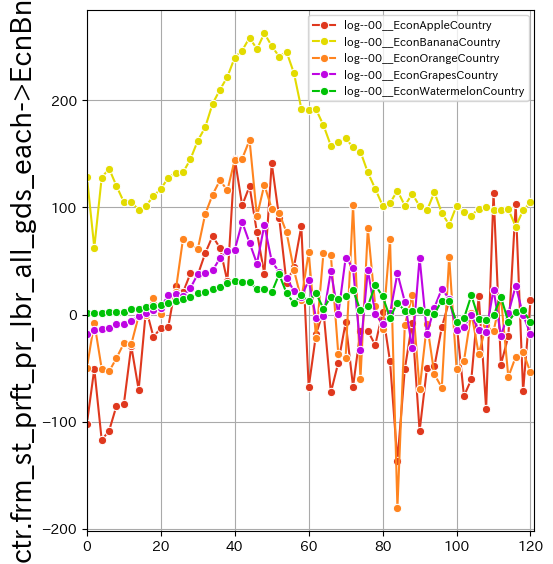

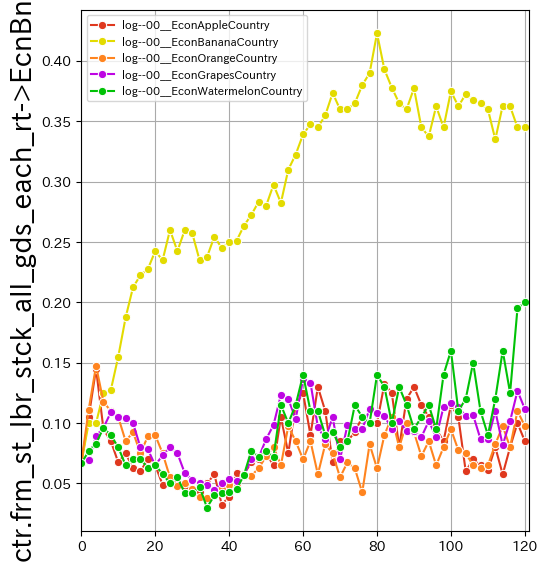

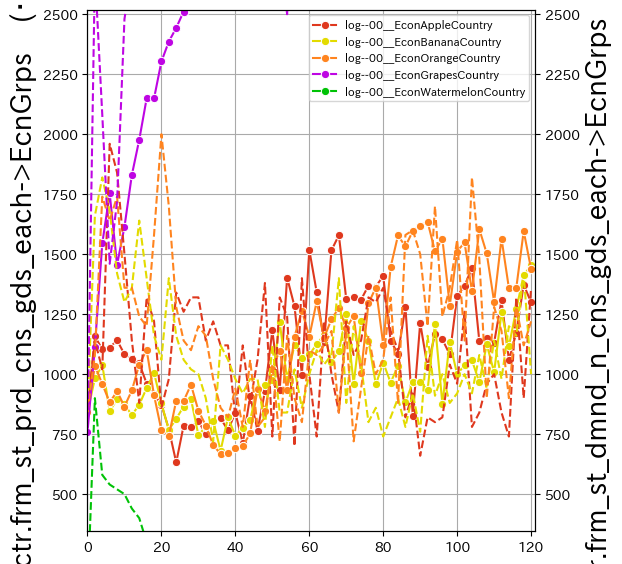

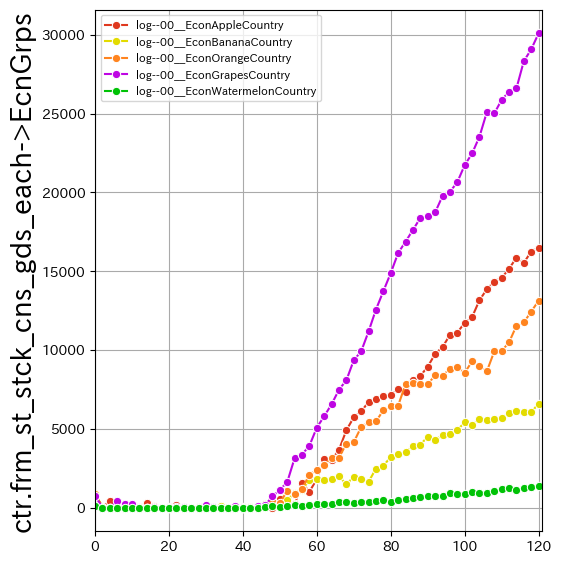

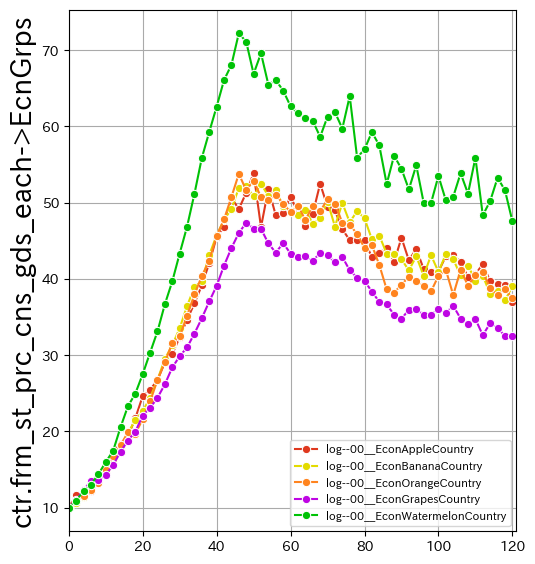

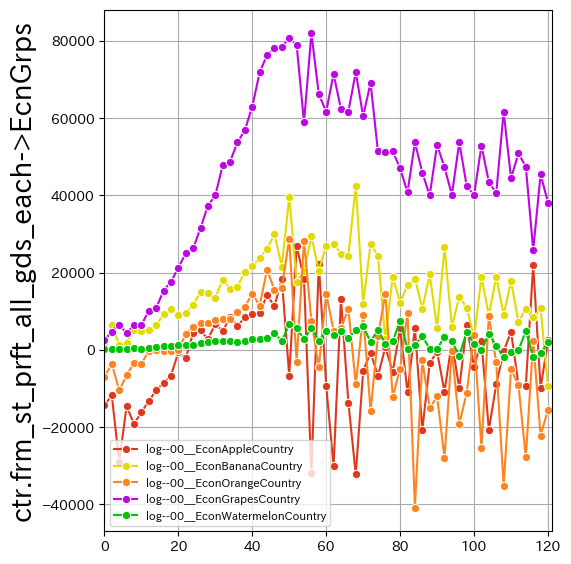

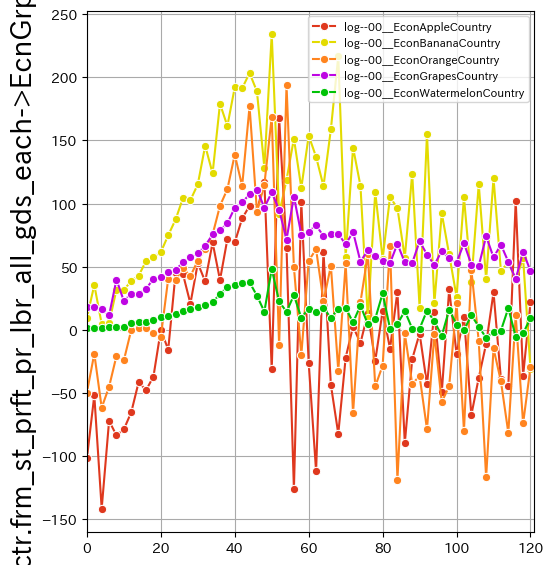

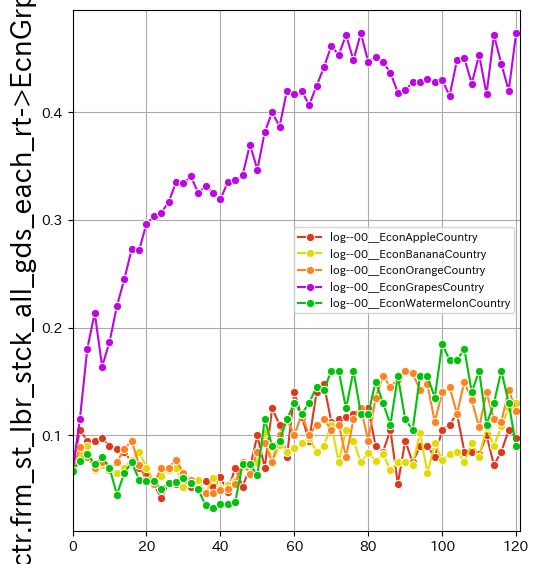

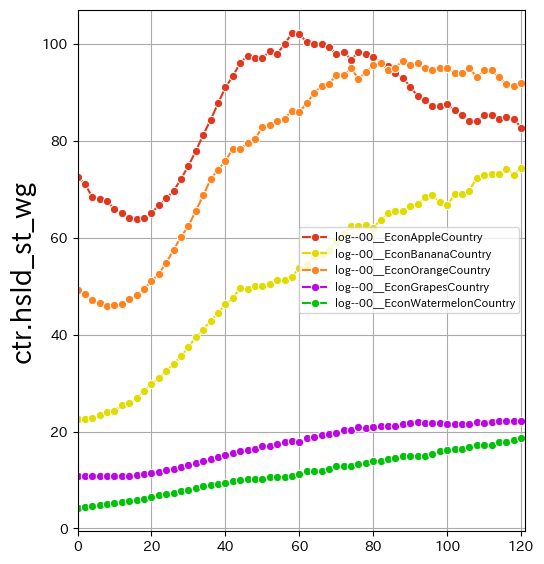

Cell executed in 23.994 s


In [15]:
if PLOT in ['recardian_trade', 'tariff_war']:
    end_timestep = None
    
    plot_settings = [
    
    
        
        {
            'left_col': 'ctr.frm_st_prod_cons_goods_agg',
            'targets': ['all'],
        },
    
    
    
    
        
        {
            'left_col': 'ctr.frm_st_prod_cons_goods_each->EconApple',
            'right_col': 'ctr.frm_st_demand_n_cons_goods_each->EconApple',
            'targets': ['all'],
            'left_right_same_scale': True,
            'left_ylim_scale': (1.0, 0.5),
        },
        {
            'left_col': 'ctr.frm_st_stock_cons_goods_each->EconApple',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_price_cons_goods_each->EconApple',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_profit_all_goods_each->EconApple',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_profit_per_labor_all_goods_each->EconApple',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->EconApple',
            'targets': ['all'],
        },
    
        
        
        {
            'left_col': 'ctr.frm_st_prod_cons_goods_each->EconBanana',
            'right_col': 'ctr.frm_st_demand_n_cons_goods_each->EconBanana',
            'targets': ['all'],
            'left_right_same_scale': True,
            'left_ylim_scale': (1.0, 0.5),
        },
        {
            'left_col': 'ctr.frm_st_stock_cons_goods_each->EconBanana',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_price_cons_goods_each->EconBanana',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_profit_all_goods_each->EconBanana',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_profit_per_labor_all_goods_each->EconBanana',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->EconBanana',
            'targets': ['all'],
        },
    
        
    
        # {
        #     'left_col': 'ctr.frm_st_prod_cons_goods_each->EconOrange',
        #     'right_col': 'ctr.frm_st_demand_n_cons_goods_each->EconOrange',
        #     'targets': ['all'],
        #     'left_right_same_scale': True,
        #     'left_ylim_scale': (1.0, 0.5),
        # },
        # {
        #     'left_col': 'ctr.frm_st_stock_cons_goods_each->EconOrange',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_price_cons_goods_each->EconOrange',
        #     'targets': ['all'],
        # },   
        # {
        #     'left_col': 'ctr.frm_st_profit_all_goods_each->EconOrange',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_profit_per_labor_all_goods_each->EconOrange',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->EconOrange',
        #     'targets': ['all'],
        # },
    # 
    # 
    # 
        {
            'left_col': 'ctr.frm_st_prod_cons_goods_each->EconGrapes',
            'right_col': 'ctr.frm_st_demand_n_cons_goods_each->EconGrapes',
            'targets': ['all'],
            'left_right_same_scale': True,
            'left_ylim_scale': (1.0, 0.5),
        },
        {
            'left_col': 'ctr.frm_st_stock_cons_goods_each->EconGrapes',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_price_cons_goods_each->EconGrapes',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_profit_all_goods_each->EconGrapes',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_profit_per_labor_all_goods_each->EconGrapes',
            'targets': ['all'],
        },
        {
            'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->EconGrapes',
            'targets': ['all'],
        },



        {
            'left_col': 'ctr.hsld_st_wage',
            'targets': ['all'],
        },

        
    # 
    # 
        # 
    # 
        # {
        #     'left_col': 'ctr.frm_st_prod_cons_goods_each->EconWatermelon',
        #     'right_col': 'ctr.frm_st_demand_n_cons_goods_each->EconWatermelon',
        #     'targets': ['all'],
        #     'left_right_same_scale': True,
        #     'left_ylim_scale': (1.0, 0.5),
        # },
        # {
        #     'left_col': 'ctr.frm_st_stock_cons_goods_each->EconWatermelon',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_price_cons_goods_each->EconWatermelon',
        #     'targets': ['all'],
        # },  
        # {
        #     'left_col': 'ctr.frm_st_profit_all_goods_each->EconWatermelon',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_profit_per_labor_all_goods_each->EconWatermelon',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->EconWatermelon',
        #     'targets': ['all'],
        # },
    # 
        # 
    # 
        # {
        #     'left_col': 'ctr.frm_st_prod_cap_goods_each->GenericCapital',
        #     'right_col': 'ctr.frm_st_demand_n_cap_goods_each->GenericCapital',
        #     'targets': ['all'],
        #     'left_right_same_scale': True,
        # },
        # {
        #     'left_col': 'ctr.frm_st_stock_cap_goods_each->GenericCapital',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_price_cap_goods_each->GenericCapital',
        #     'targets': ['all'],
        # },  
        # {
        #     'left_col': 'ctr.frm_st_profit_all_goods_each->GenericCapital',
        #     'targets': ['all'],
        # },  
        # {
        #     'left_col': 'ctr.frm_st_profit_per_labor_all_goods_each->GenericCapital',
        #     'targets': ['all'],
        # },  
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->GenericCapital',
        #     'targets': ['all'],
        # },
    # 
    # 
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each->EconApple',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each->EconBanana',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each->EconOrange',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each->EconGrapes',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each->EconWatermelon',
        #     'targets': ['all'],
        # },
    # 
    # 
        # 
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each->EconApplePlantingKit',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each->EconBananaPlantingKit',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each->EconOrangePlantingKit',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each->EconGrapesPlantingKit',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each->EconWatermelonPlantingKit',
        #     'targets': ['all'],
        # },
    # 
    # 
    # 
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_sectors_agg',
        #     'targets': ['all'],
        # },
    # 
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_agg',
        #     'targets': ['all'],
        # },
    # 
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->EconApplePlantingKit',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->EconBananaPlantingKit',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->EconOrangePlantingKit',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->EconGrapesPlantingKit',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_labor_stock_all_goods_each_ratio->EconWatermelonPlantingKit',
        #     'targets': ['all'],
        # },
    # 
    # 
    # 
        # {
        #     'left_col': 'ctr.hsld_st_wage',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.hsld_st_income',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.hsld_st_consump_cash_agg',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_demand_n_all_goods_agg',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.hsld_st_cash_balance',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.frm_st_cash_balance',
        #     'targets': ['all'],
        # },
        # {
        #     'left_col': 'ctr.hsld_st_monthly_saving_rate',
        #     'targets': ['all'],
        # },
    
    ]

    _colors = {}
    for country in country_dfs.keys():
        for good, color in ECON_FRUIT_COLORS.items():
            if country.find(good) >= 0:
                _colors[country] = color
                break
                
    output_dir = OUTPUT_TOP_DIR / 'timeseries' / 'with_trade' if OUTPUT_TOP_DIR is not None else None
                
    plot_dfs_with_right_from_settings(country_dfs,
                                      plot_settings,
                                      end_timestep=end_timestep,
                                      other_run_dfs=other_run_country_dfs,
                                      colors=_colors,
                                      # df_labels=DF_LABELS,
                                      output_dir=output_dir)

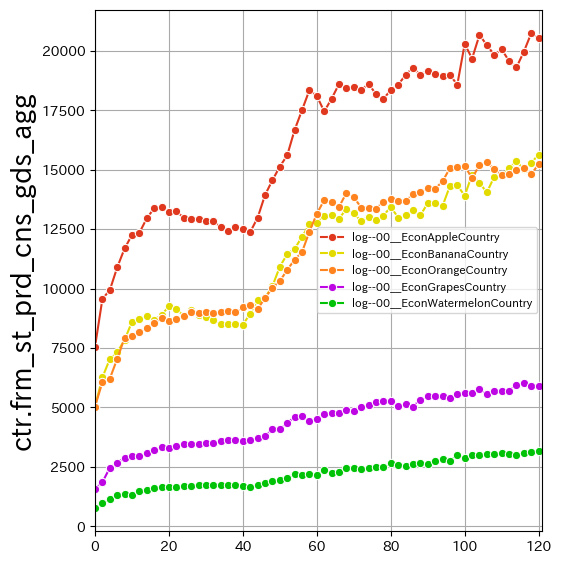

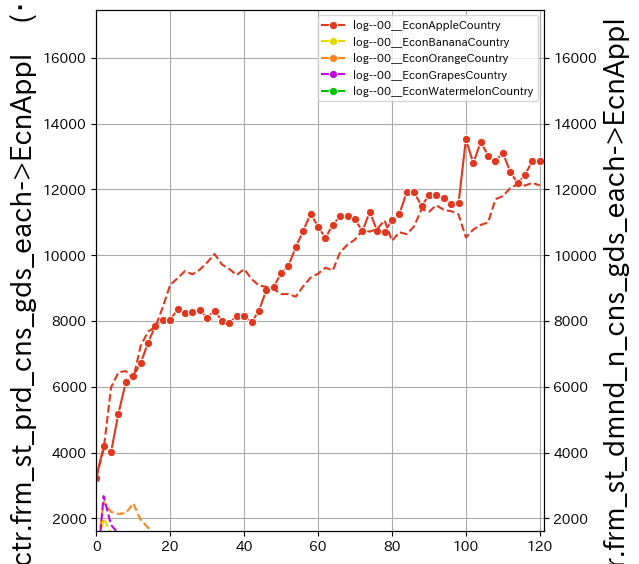

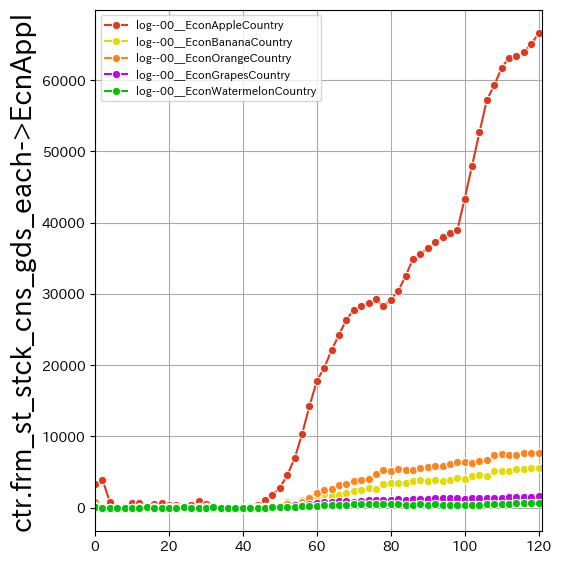

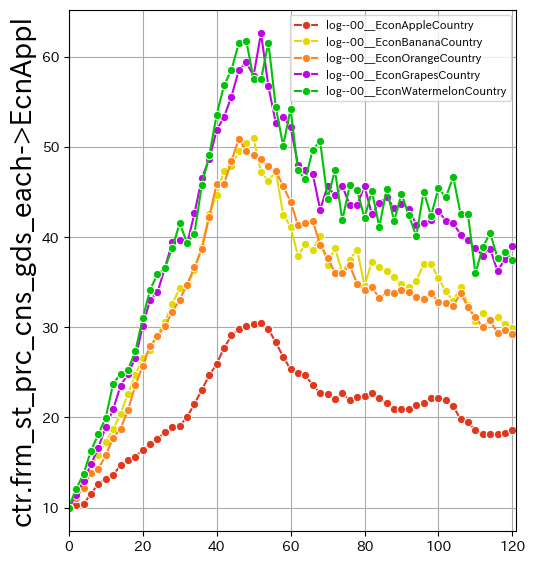

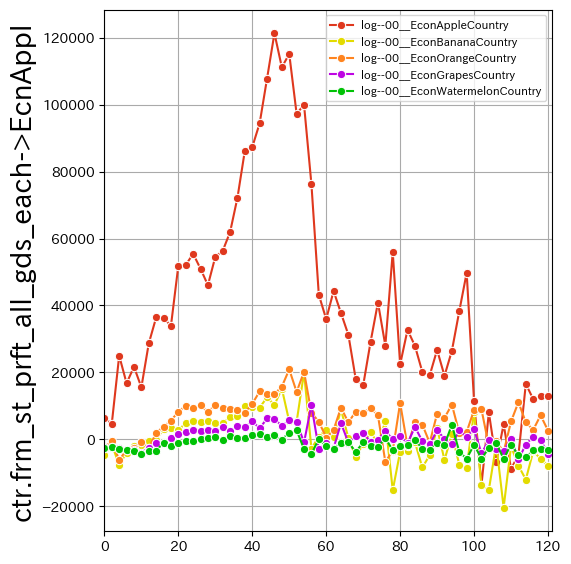

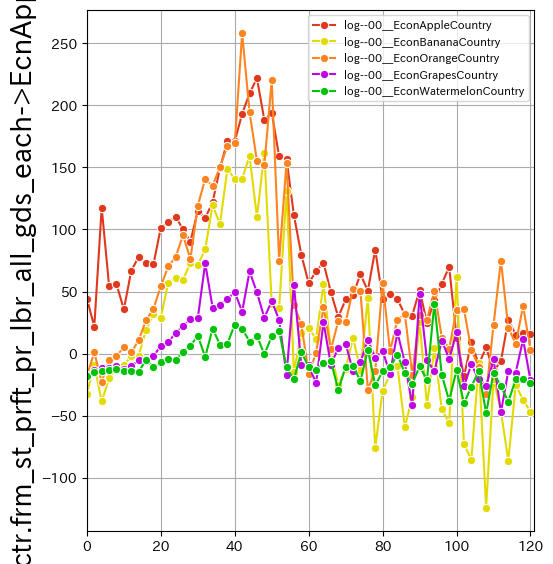

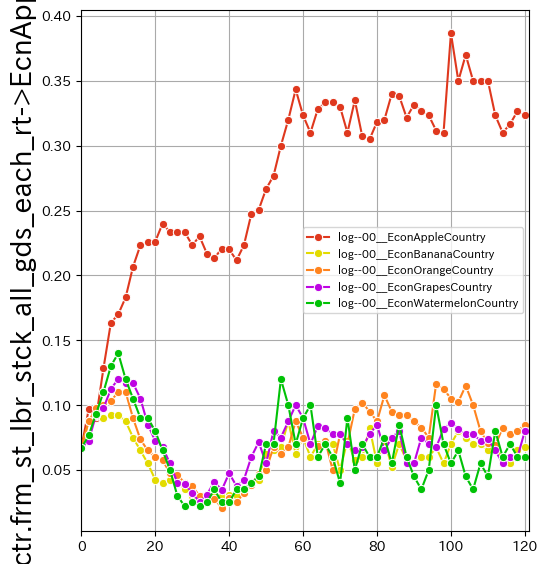

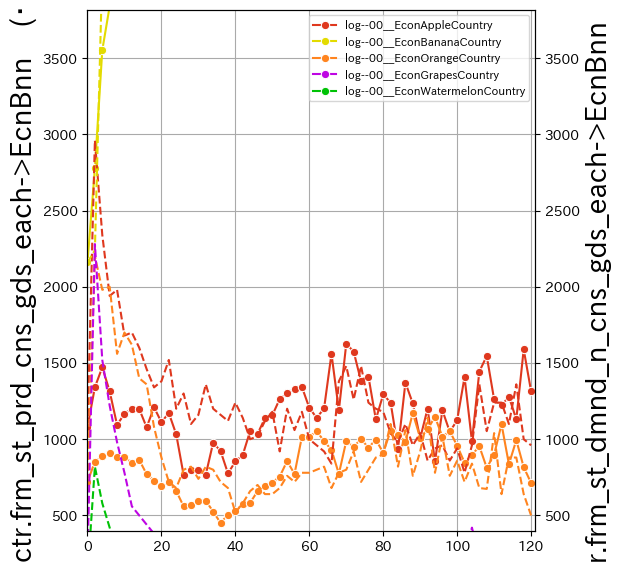

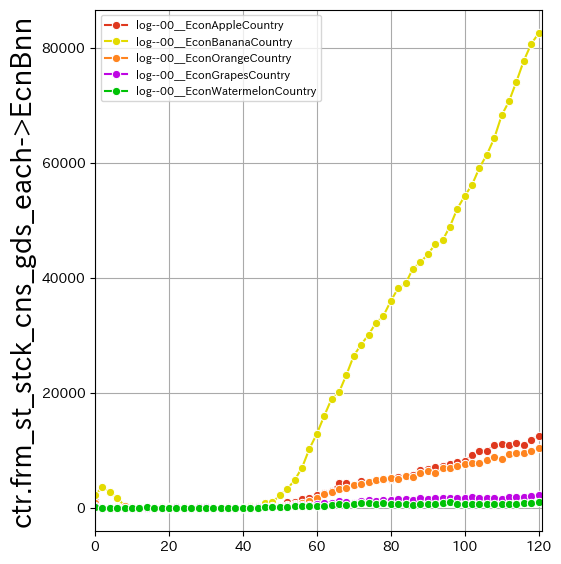

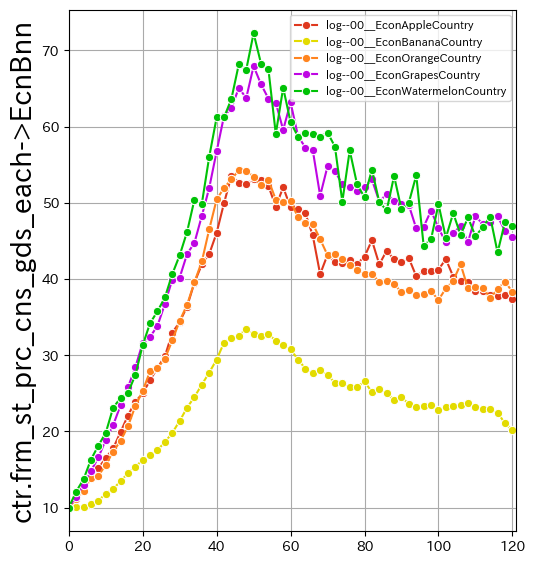

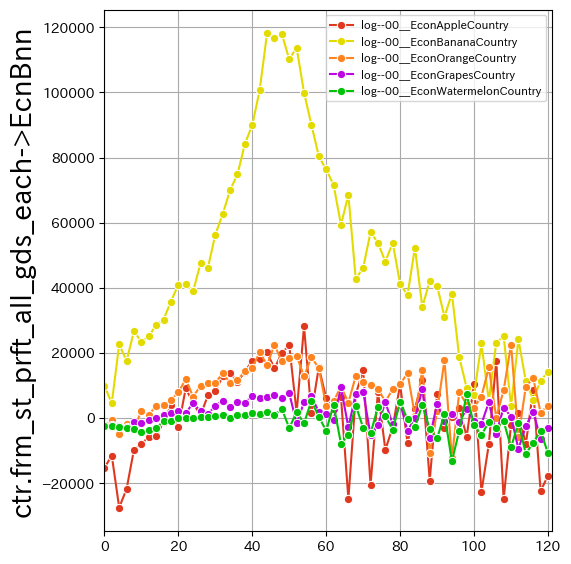

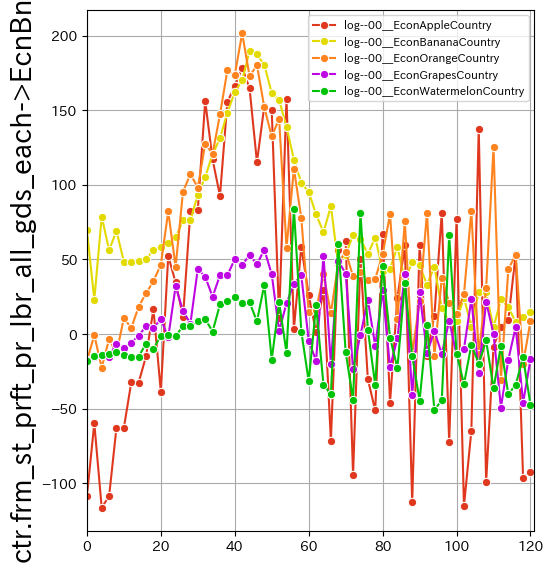

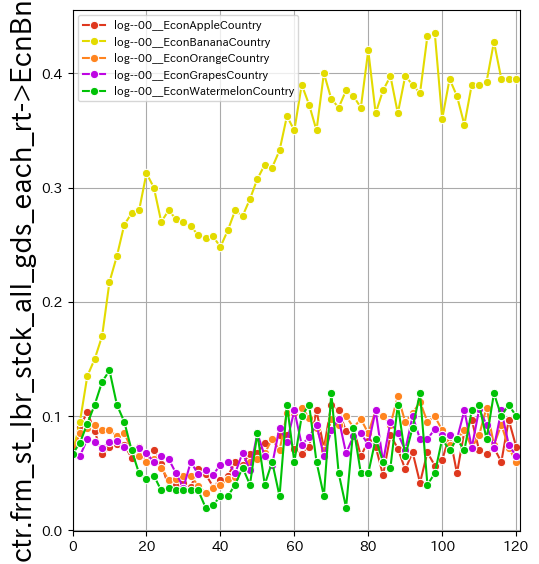

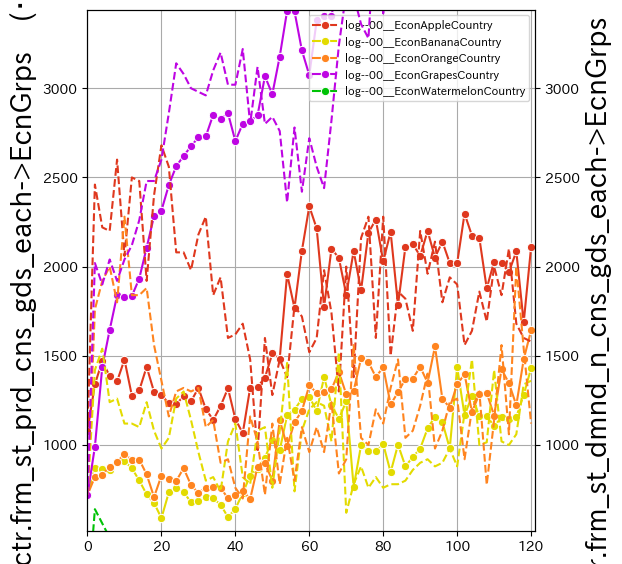

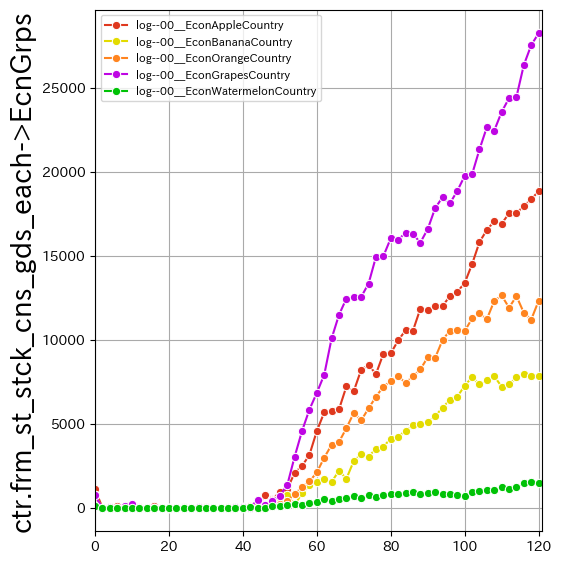

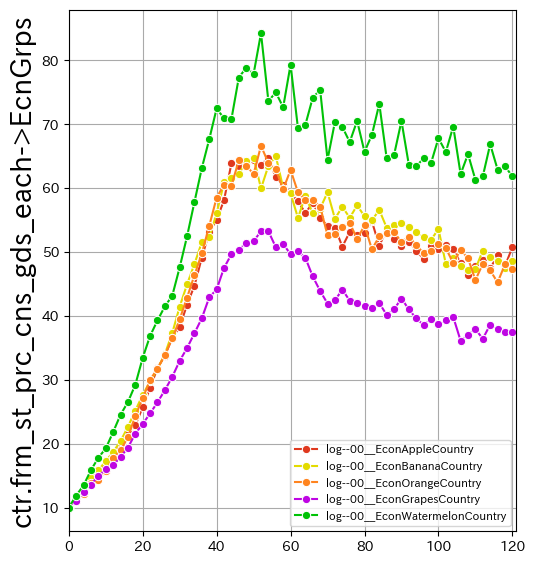

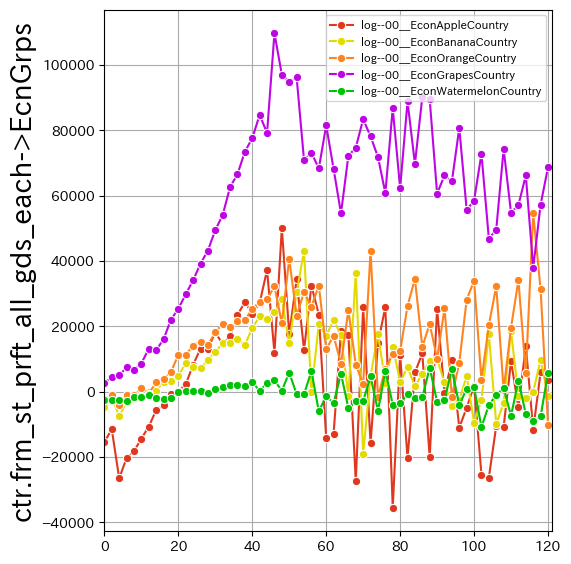

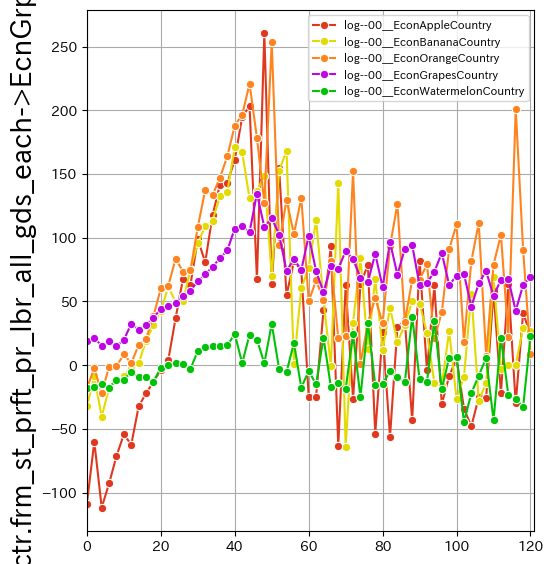

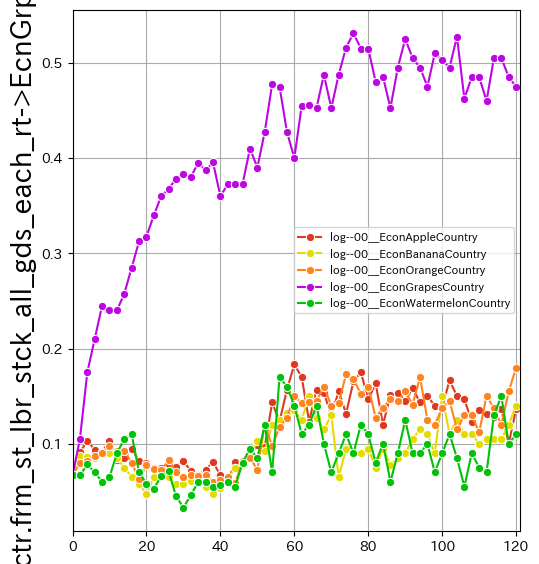

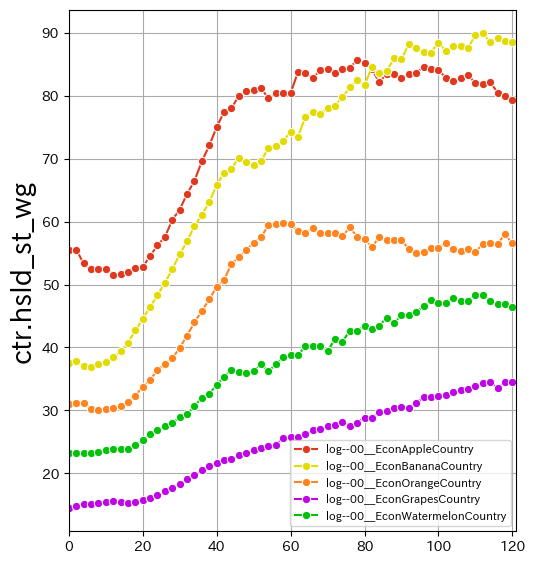

Cell executed in 21.028 s


In [16]:
if PLOT in ['recardian_trade', 'tariff_war']:
    output_dir = OUTPUT_TOP_DIR / 'timeseries' / 'wo_trade' if OUTPUT_TOP_DIR is not None else None
                
    plot_dfs_with_right_from_settings(wo_trade_country_dfs,
                                      plot_settings,
                                      end_timestep=end_timestep,
                                      other_run_dfs=wo_trade_other_run_country_dfs,
                                      colors=_colors,
                                      # df_labels=DF_LABELS,
                                      output_dir=output_dir)

In [17]:
from __future__ import annotations

from typing import Callable, Mapping, Optional, Sequence, Tuple, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

# =========================
# Types / constants
# =========================
TRADE_BEFORE_HATCH = "//"

AggHow = Union[str, Tuple[str, int], Tuple[str, int, int], Callable[[pd.DataFrame], pd.Series]]

# NOTE: These are referenced in your original code.
# Keep them as-is in your project; here we assume they exist.
# FIGSIZE = ...
# PLOT_CAMERA_READY = ...


# =========================
# Helpers (as in original)
# =========================
def _parse_how_str(how: str) -> Union[str, Tuple[str, int], Tuple[str, int, int]]:
    s = how.strip().lower()

    if s.endswith("]") and "[" in s:
        mode, inner = s[:-1].split("[", 1)
        mode = mode.strip()
        inner = inner.strip()

        if ":" in inner:
            a, b = inner.split(":", 1)
            try:
                if mode in ("middle", "mid", "center", "range", "slice"):
                    return (f"{mode}_mean", int(a), int(b))
            except ValueError:
                return how
        else:
            try:
                if mode in ("tail", "head"):
                    return (f"{mode}_mean", int(inner))
            except ValueError:
                return how

    parts = s.split(":")
    if len(parts) == 2:
        mode, n = parts
        try:
            return (mode, int(n))
        except ValueError:
            return how
    if len(parts) == 3:
        mode, a, b = parts
        try:
            return (mode, int(a), int(b))
        except ValueError:
            return how
    return how


def _clip_pos(pos: int, nrows: int) -> int:
    if nrows <= 0:
        return 0
    if pos < 0:
        pos = nrows + pos
    return max(0, min(pos, nrows - 1))


def _extract_good_name(col: str) -> str:
    return col.split("->", 1)[1] if "->" in col else col


def _safe_numeric_frame(df: pd.DataFrame, cols: Sequence[str]) -> pd.DataFrame:
    sub = df.reindex(columns=list(cols))
    return sub.apply(pd.to_numeric, errors="coerce")


def _resolve_label(key: str, label_map: Optional[Mapping[str, str]]) -> str:
    return label_map.get(key, key) if label_map else key


def _resolve_colors(
    keys_raw: Sequence[str],
    labels: Sequence[str],
    colors: Optional[Union[Mapping[str, str], Sequence[str]]],
    *,
    palette: str = "tab10",
) -> Sequence:
    n = len(keys_raw)
    if colors is None:
        return sns.color_palette(palette, n_colors=n)

    out = []
    if isinstance(colors, Mapping):
        for k, lab in zip(keys_raw, labels):
            out.append(colors.get(k, colors.get(lab, None)))
        fallback = iter(sns.color_palette(palette, n_colors=n))
        out = [c if c is not None else next(fallback) for c in out]
        return out

    if len(colors) == 0:
        return sns.color_palette(palette, n_colors=n)
    for i in range(n):
        out.append(colors[i % len(colors)])
    return out


# =========================
# summarize / matrix / normalization (as in original)
# =========================
def summarize_vector(
    df: pd.DataFrame,
    cols: Sequence[str],
    how: AggHow = "last",
    row: Optional[object] = None,
    fillna_value: float = 0.0,
) -> pd.Series:
    sub = _safe_numeric_frame(df, cols)

    if sub.shape[0] == 0:
        return pd.Series({c: fillna_value for c in cols}, dtype=float)

    if row is not None:
        v = sub.loc[row]
        if isinstance(v, pd.DataFrame):
            v = v.iloc[0]
        return v.reindex(list(cols)).fillna(fillna_value).astype(float)

    if isinstance(how, str):
        how = _parse_how_str(how)

    if isinstance(how, tuple) and len(how) == 2:
        mode, n = how
        mode = str(mode).lower()
        n = int(n)
        if mode.startswith(("tail_", "last_n_")) or mode == "rolling_mean":
            window = sub.tail(n)
        elif mode.startswith(("head_", "first_n_")):
            window = sub.head(n)
        else:
            raise ValueError(
                f"Unsupported tuple how={how}. Use ('tail_mean', n), ('head_mean', n), ..."
            )

        if window.shape[0] == 0:
            return pd.Series({c: fillna_value for c in cols}, dtype=float)

        if mode in ("tail_last", "last_n_last", "head_last", "first_n_last"):
            v = window.iloc[-1]
        elif mode in ("tail_first", "last_n_first", "head_first", "first_n_first"):
            v = window.iloc[0]
        elif mode in ("tail_sum", "last_n_sum", "head_sum", "first_n_sum"):
            v = window.sum(axis=0)
        elif mode in ("tail_mean", "last_n_mean", "rolling_mean", "head_mean", "first_n_mean"):
            v = window.mean(axis=0)
        elif mode in ("tail_median", "last_n_median", "head_median", "first_n_median"):
            v = window.median(axis=0)
        else:
            raise ValueError(
                f"Unsupported tuple how={how}. Use ('tail_mean', n), ('head_mean', n), ..."
            )

        return v.reindex(list(cols)).fillna(fillna_value).astype(float)

    if isinstance(how, tuple) and len(how) == 3:
        mode, a, b = how
        mode = str(mode).lower()
        a = int(a)
        b = int(b)

        nrows = sub.shape[0]
        a_pos = _clip_pos(a, nrows)
        b_pos = _clip_pos(b, nrows)
        start = min(a_pos, b_pos)
        end = max(a_pos, b_pos)

        window = sub.iloc[start : end + 1]
        if window.shape[0] == 0:
            return pd.Series({c: fillna_value for c in cols}, dtype=float)

        if mode in ("range_last", "slice_last", "middle_last", "mid_last", "center_last"):
            v = window.iloc[-1]
        elif mode in ("range_first", "slice_first", "middle_first", "mid_first", "center_first"):
            v = window.iloc[0]
        elif mode in ("range_sum", "slice_sum", "middle_sum", "mid_sum", "center_sum"):
            v = window.sum(axis=0)
        elif mode in ("range_mean", "slice_mean", "middle_mean", "mid_mean", "center_mean"):
            v = window.mean(axis=0)
        elif mode in ("range_median", "slice_median", "middle_median", "mid_median", "center_median"):
            v = window.median(axis=0)
        else:
            raise ValueError(
                f"Unsupported tuple how={how}. Use ('range_mean', n, m), ('middle_mean', n, m), ..."
            )

        return v.reindex(list(cols)).fillna(fillna_value).astype(float)

    if isinstance(how, str):
        h = how.lower()
        if h == "last":
            v = sub.iloc[-1]
        elif h == "first":
            v = sub.iloc[0]
        elif h == "sum":
            v = sub.sum(axis=0)
        elif h == "mean":
            v = sub.mean(axis=0)
        elif h == "median":
            v = sub.median(axis=0)
        else:
            raise ValueError(
                f"Unsupported how='{how}'. Use 'last','sum','mean','median' or "
                f"('tail_mean', n)/('head_mean', n)/('middle_mean', n, m) or "
                f"'tail[n]'/'head[n]'/'middle[n:m]' or callable."
            )
    else:
        v = how(sub)
        if not isinstance(v, pd.Series):
            raise TypeError("Callable how must return pd.Series with index=cols.")

    return v.reindex(list(cols)).fillna(fillna_value).astype(float)


def build_country_good_matrix(
    country_dfs: Mapping[str, pd.DataFrame],
    cols: Sequence[str],
    countries: Optional[Sequence[str]] = None,
    how: AggHow = "last",
    row: Optional[object] = None,
    fillna_value: float = 0.0,
    clip_negative: bool = False,
) -> pd.DataFrame:
    if countries is None:
        countries = list(country_dfs.keys())

    goods = [_extract_good_name(c) for c in cols]

    rows = []
    for cid in countries:
        s = summarize_vector(country_dfs[cid], cols, how=how, row=row, fillna_value=fillna_value)
        vals = s.to_numpy(dtype=float)
        if clip_negative:
            vals = np.clip(vals, 0.0, None)
        rows.append(vals)

    return pd.DataFrame(rows, index=list(countries), columns=goods, dtype=float)


def normalize_rows_to_one(df: pd.DataFrame) -> pd.DataFrame:
    denom = df.sum(axis=1).replace(0.0, np.nan)
    return df.div(denom, axis=0).fillna(0.0)


def normalize_cols_to_one(df: pd.DataFrame) -> pd.DataFrame:
    denom = df.sum(axis=0).replace(0.0, np.nan)
    return df.div(denom, axis=1).fillna(0.0)


# =========================
# Plotting
# =========================
def plot_100pct_stacked_bar(
    share_df: pd.DataFrame,
    *,
    x_label_map: Optional[Mapping[str, str]] = None,
    stack_label_map: Optional[Mapping[str, str]] = None,
    x_order: Optional[Sequence[str]] = None,
    stack_order: Optional[Sequence[str]] = None,
    stack_colors: Optional[Union[Mapping[str, str], Sequence[str]]] = None,
    palette: str = "tab10",
    figsize: Tuple[float, float] = FIGSIZE,
    title: Optional[str] = None,
    xlabel: Optional[str] = None,
    ylabel: str = "Share",
    legend: bool = True,
    legend_kwargs: Optional[dict] = None,
    legend_fontsize: Optional[float] = None,
    rotation: int = 0,
    bar_width: float = 0.7,
    bar_gap: float = 0.2,
    bar_kwargs: Optional[dict] = None,
    ax: Optional[plt.Axes] = None,
    # seaborn 見た目設定
    sns_style: str = "whitegrid",
    sns_context: str = "notebook",
    font_scale: float = 1.0,
    rc: Optional[Mapping[str, object]] = None,
    # ===== 追加：軸/ tick サイズ調整 =====
    title_fontsize: Optional[float] = None,
    xlabel_fontsize: Optional[float] = None,
    ylabel_fontsize: Optional[float] = None,
    tick_fontsize: Optional[float] = None,
    xtick_fontsize: Optional[float] = None,
    ytick_fontsize: Optional[float] = None,
    tick_length: Optional[float] = None,
    tick_width: Optional[float] = None,
    # ====================================
    **ignore_kwargs,
) -> Tuple[plt.Figure, plt.Axes]:
    if x_order is None:
        x_order = list(share_df.index)
    if stack_order is None:
        stack_order = list(share_df.columns)

    plot_df = share_df.reindex(index=list(x_order), columns=list(stack_order)).fillna(0.0)

    x_keys = list(plot_df.index)
    x_labels = [_resolve_label(x, x_label_map) for x in x_keys]

    stack_keys = list(plot_df.columns)
    stack_labels = [_resolve_label(s, stack_label_map) for s in stack_keys]

    colors = _resolve_colors(stack_keys, stack_labels, stack_colors, palette=palette)

    if bar_kwargs is None:
        bar_kwargs = {}

    with sns.axes_style(sns_style, rc=rc or {}), sns.plotting_context(
        sns_context, font_scale=font_scale, rc=rc or {}
    ):
        if ax is None:
            fig, ax = plt.subplots(figsize=figsize)
        else:
            fig = ax.figure

        x = np.arange(len(x_labels))
        bottom = np.zeros(len(x_labels), dtype=float)

        for i, (k, lab) in enumerate(zip(stack_keys, stack_labels)):
            vals = plot_df[k].to_numpy(dtype=float)
            ax.bar(
                x,
                vals,
                bottom=bottom,
                width=bar_width,
                label=lab,
                color=colors[i],
                **bar_kwargs,
            )
            bottom += vals

        ax.set_ylim(0.0, 1.0)
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.set_xticks(x)
        ax.set_xticklabels(x_labels, rotation=rotation, ha="right" if rotation else "center")

        if title:
            ax.set_title(title)
        if xlabel is not None:
            ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

        if legend:
            lk = dict(legend_kwargs or {})
            if legend_fontsize is not None and "fontsize" not in lk and "prop" not in lk:
                lk["fontsize"] = legend_fontsize
            ax.legend(**lk)

        fig.tight_layout()

    # 既存：bar_gap 対応の再配置（そのまま）
    n = len(x_labels)
    x_step = bar_width + bar_gap
    x = np.arange(n) * x_step
    bottom = np.zeros(n, dtype=float)

    for i, (k, lab) in enumerate(zip(stack_keys, stack_labels)):
        vals = plot_df[k].to_numpy(dtype=float)
        ax.bar(
            x,
            vals,
            bottom=bottom,
            width=bar_width,
            label=lab,
            color=colors[i],
            **bar_kwargs,
        )
        bottom += vals

    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, rotation=rotation, ha="right" if rotation else "center")
    ax.set_xlim(x[0] - x_step / 2, x[-1] + x_step / 2)

    # ===== 追加：軸/ tick サイズ調整（指定時のみ反映）=====
    if title and title_fontsize is not None:
        ax.set_title(title, fontsize=title_fontsize)
    if xlabel is not None and xlabel_fontsize is not None:
        ax.set_xlabel(xlabel, fontsize=xlabel_fontsize)
    if ylabel_fontsize is not None:
        ax.set_ylabel(ylabel, fontsize=ylabel_fontsize)

    tp = {}
    if tick_fontsize is not None:
        tp["labelsize"] = tick_fontsize
    if tick_length is not None:
        tp["length"] = tick_length
    if tick_width is not None:
        tp["width"] = tick_width
    if tp:
        ax.tick_params(axis="both", **tp)

    if xtick_fontsize is not None:
        ax.tick_params(axis="x", labelsize=xtick_fontsize)
    if ytick_fontsize is not None:
        ax.tick_params(axis="y", labelsize=ytick_fontsize)

    if any(v is not None for v in (
        title_fontsize, xlabel_fontsize, ylabel_fontsize,
        tick_fontsize, xtick_fontsize, ytick_fontsize,
        tick_length, tick_width
    )):
        fig.tight_layout()
    # =======================================================

    return fig, ax


def plot_prod_share_by_good(
    country_dfs: Mapping[str, pd.DataFrame],
    prod_cols: Sequence[str],
    *,
    countries: Optional[Sequence[str]] = None,
    how: AggHow = "last",
    row: Optional[object] = None,
    country_label_map: Optional[Mapping[str, str]] = None,
    good_label_map: Optional[Mapping[str, str]] = None,
    country_colors: Optional[Union[Mapping[str, str], Sequence[str]]] = None,
    good_order: Optional[Sequence[str]] = None,
    country_order: Optional[Sequence[str]] = None,
    figsize: Tuple[float, float] = FIGSIZE,
    title: str = "Production share by good (100% stacked)" if not PLOT_CAMERA_READY else None,
    rotation: int = 20,
    bar_width: float = 0.8,
    bar_gap: float = 0.2,
    clip_negative: bool = True,
    # seaborn
    sns_style: str = "whitegrid",
    sns_context: str = "notebook",
    font_scale: float = 1.0,
    rc: Optional[Mapping[str, object]] = None,
    palette: str = "tab10",
    legend: bool = True,
    legend_kwargs: Optional[dict] = None,
    legend_fontsize: Optional[float] = None,
    # ===== 追加：軸/ tick サイズ調整 =====
    title_fontsize: Optional[float] = None,
    xlabel_fontsize: Optional[float] = None,
    ylabel_fontsize: Optional[float] = None,
    tick_fontsize: Optional[float] = None,
    xtick_fontsize: Optional[float] = None,
    ytick_fontsize: Optional[float] = None,
    tick_length: Optional[float] = None,
    tick_width: Optional[float] = None,
    # ====================================
    **kwargs,
) -> Tuple[plt.Figure, plt.Axes, pd.DataFrame]:
    mat = build_country_good_matrix(
        country_dfs, prod_cols, countries=countries, how=how, row=row, clip_negative=clip_negative
    )
    share_by_good = normalize_cols_to_one(mat).T

    if good_order is None:
        good_order = list(share_by_good.index)
    if country_order is None:
        country_order = list(share_by_good.columns)

    fig, ax = plot_100pct_stacked_bar(
        share_by_good,
        x_label_map=good_label_map,
        stack_label_map=country_label_map,
        x_order=good_order,
        stack_order=country_order,
        stack_colors=country_colors,
        palette=palette,
        figsize=figsize,
        title=title,
        xlabel="Goods" if not PLOT_CAMERA_READY else None,
        ylabel="Country share" if not PLOT_CAMERA_READY else None,
        rotation=rotation,
        bar_width=bar_width,
        bar_gap=bar_gap,
        sns_style=sns_style,
        sns_context=sns_context,
        font_scale=font_scale,
        rc=rc,
        legend=legend,
        legend_kwargs=legend_kwargs,
        legend_fontsize=legend_fontsize,
        # pass-through
        title_fontsize=title_fontsize,
        xlabel_fontsize=xlabel_fontsize,
        ylabel_fontsize=ylabel_fontsize,
        tick_fontsize=tick_fontsize,
        xtick_fontsize=xtick_fontsize,
        ytick_fontsize=ytick_fontsize,
        tick_length=tick_length,
        tick_width=tick_width,
        **kwargs,
    )
    return fig, ax, share_by_good


def plot_labor_allocation_by_country(
    country_dfs: Mapping[str, pd.DataFrame],
    labor_ratio_cols: Sequence[str],
    *,
    countries: Optional[Sequence[str]] = None,
    how: AggHow = "last",
    row: Optional[object] = None,
    country_label_map: Optional[Mapping[str, str]] = None,
    good_label_map: Optional[Mapping[str, str]] = None,
    good_colors: Optional[Union[Mapping[str, str], Sequence[str]]] = None,
    country_order: Optional[Sequence[str]] = None,
    good_order: Optional[Sequence[str]] = None,
    figsize: Tuple[float, float] = FIGSIZE,
    title: str = "Labor allocation by country (normalized, 100% stacked)" if not PLOT_CAMERA_READY else None,
    rotation: int = 20,
    bar_width: float = 0.8,
    bar_gap: float = 0.2,
    clip_negative: bool = True,
    # seaborn
    sns_style: str = "whitegrid",
    sns_context: str = "notebook",
    font_scale: float = 1.0,
    rc: Optional[Mapping[str, object]] = None,
    palette: str = "tab10",
    legend: bool = True,
    legend_kwargs: Optional[dict] = None,
    legend_fontsize: Optional[float] = None,
    # ===== 追加：軸/ tick サイズ調整 =====
    title_fontsize: Optional[float] = None,
    xlabel_fontsize: Optional[float] = None,
    ylabel_fontsize: Optional[float] = None,
    tick_fontsize: Optional[float] = None,
    xtick_fontsize: Optional[float] = None,
    ytick_fontsize: Optional[float] = None,
    tick_length: Optional[float] = None,
    tick_width: Optional[float] = None,
    # ====================================
    **kwargs,
) -> Tuple[plt.Figure, plt.Axes, pd.DataFrame]:
    mat = build_country_good_matrix(
        country_dfs, labor_ratio_cols, countries=countries, how=how, row=row, clip_negative=clip_negative
    )
    share_by_country = normalize_rows_to_one(mat)

    if country_order is None:
        country_order = list(share_by_country.index)
    if good_order is None:
        good_order = list(share_by_country.columns)

    fig, ax = plot_100pct_stacked_bar(
        share_by_country,
        x_label_map=country_label_map,
        stack_label_map=good_label_map,
        x_order=country_order,
        stack_order=good_order,
        stack_colors=good_colors,
        palette=palette,
        figsize=figsize,
        title=title,
        xlabel="Countries" if not PLOT_CAMERA_READY else None,
        ylabel="Labor share" if not PLOT_CAMERA_READY else None,
        rotation=rotation,
        bar_width=bar_width,
        bar_gap=bar_gap,
        sns_style=sns_style,
        sns_context=sns_context,
        font_scale=font_scale,
        rc=rc,
        legend=legend,
        legend_kwargs=legend_kwargs,
        legend_fontsize=legend_fontsize,
        # pass-through
        title_fontsize=title_fontsize,
        xlabel_fontsize=xlabel_fontsize,
        ylabel_fontsize=ylabel_fontsize,
        tick_fontsize=tick_fontsize,
        xtick_fontsize=xtick_fontsize,
        ytick_fontsize=ytick_fontsize,
        tick_length=tick_length,
        tick_width=tick_width,
        **kwargs,
    )
    return fig, ax, share_by_country


def plot_labor_allocation_by_country_with_optional_before(
    country_dfs: Mapping[str, pd.DataFrame],
    labor_ratio_cols: Sequence[str],
    *,
    wo_trade_country_dfs: Optional[Mapping[str, pd.DataFrame]] = None,
    countries: Optional[Sequence[str]] = None,
    how="last",
    row=None,
    country_label_map=None,
    good_label_map=None,
    country_order: Optional[Sequence[str]] = None,
    good_order: Optional[Sequence[str]] = None,
    good_colors=None,
    palette: str = "tab10",
    # before/after
    scenario_labels: Tuple[str, str] = ("Before (No trade)", "After (Trade)"),
    scenario_hatches: Tuple[Optional[str], Optional[str]] = (TRADE_BEFORE_HATCH, None),
    figsize: Tuple[float, float] = FIGSIZE,
    title: str = "Labor allocation by country (share)" if not PLOT_CAMERA_READY else None,
    rotation: int = 20,
    bar_width: float = 0.35,
    pair_gap: float = 0.05,
    group_gap: float = 0.25,
    # seaborn
    sns_style: str = "whitegrid",
    sns_context: str = "notebook",
    font_scale: float = 1.0,
    rc=None,
    # フォント（既存）
    title_fontsize=None,
    xlabel_fontsize=None,
    ylabel_fontsize=None,
    tick_fontsize=None,
    legend_fontsize=None,
    # ===== 追加：x/y別 tick + tick長さ/太さ =====
    xtick_fontsize=None,
    ytick_fontsize=None,
    tick_length=None,
    tick_width=None,
    # =========================================
    **kwargs,
):
    if countries is None:
        if wo_trade_country_dfs is None:
            countries = list(country_dfs.keys())
        else:
            countries = [c for c in wo_trade_country_dfs.keys() if c in country_dfs]

    after_mat = build_country_good_matrix(
        country_dfs, labor_ratio_cols, countries=countries, how=how, row=row, clip_negative=True
    )
    after_share = normalize_rows_to_one(after_mat)

    if wo_trade_country_dfs is None:
        if country_order is None:
            country_order = list(after_share.index)
        if good_order is None:
            good_order = list(after_share.columns)

        fig, ax = plot_100pct_stacked_bar(
            after_share,
            x_label_map=country_label_map,
            stack_label_map=good_label_map,
            x_order=country_order,
            stack_order=good_order,
            stack_colors=good_colors,
            palette=palette,
            figsize=figsize,
            title=title,
            xlabel="Countries" if not PLOT_CAMERA_READY else None,
            ylabel="Labor share" if not PLOT_CAMERA_READY else None,
            rotation=rotation,
            sns_style=sns_style,
            sns_context=sns_context,
            font_scale=font_scale,
            rc=rc,
            # fonts
            title_fontsize=title_fontsize,
            xlabel_fontsize=xlabel_fontsize,
            ylabel_fontsize=ylabel_fontsize,
            tick_fontsize=tick_fontsize,
            xtick_fontsize=xtick_fontsize,
            ytick_fontsize=ytick_fontsize,
            tick_length=tick_length,
            tick_width=tick_width,
            legend_fontsize=legend_fontsize,
            **kwargs,
        )
        return fig, ax

    before_mat = build_country_good_matrix(
        wo_trade_country_dfs, labor_ratio_cols, countries=countries, how=how, row=row, clip_negative=True
    )
    before_share = normalize_rows_to_one(before_mat)

    # NOTE: plot_country_stacked_before_after はあなたの別定義をそのまま使う前提（変更不要）
    fig, ax = plot_country_stacked_before_after(
        before_share,
        after_share,
        country_label_map=country_label_map,
        good_label_map=good_label_map,
        country_order=country_order,
        good_order=good_order,
        good_colors=good_colors,
        palette=palette,
        scenario_labels=scenario_labels,
        scenario_hatches=scenario_hatches,
        figsize=figsize,
        title=title,
        xlabel="Countries",
        ylabel="Labor share",
        rotation=rotation,
        bar_width=bar_width,
        pair_gap=pair_gap,
        group_gap=group_gap,
        as_percent=True,
        sns_style=sns_style,
        sns_context=sns_context,
        font_scale=font_scale,
        rc=rc,
        title_fontsize=title_fontsize,
        xlabel_fontsize=xlabel_fontsize,
        ylabel_fontsize=ylabel_fontsize,
        tick_fontsize=tick_fontsize,
        legend_fontsize=legend_fontsize,
        **kwargs,
    )

    # ===== 追加：戻り ax に後処理で反映（指定時のみ）=====
    tp = {}
    if tick_fontsize is not None:
        tp["labelsize"] = tick_fontsize
    if tick_length is not None:
        tp["length"] = tick_length
    if tick_width is not None:
        tp["width"] = tick_width
    if tp:
        ax.tick_params(axis="both", **tp)
    if xtick_fontsize is not None:
        ax.tick_params(axis="x", labelsize=xtick_fontsize)
    if ytick_fontsize is not None:
        ax.tick_params(axis="y", labelsize=ytick_fontsize)

    if title is not None and title_fontsize is not None:
        ax.set_title(title, fontsize=title_fontsize)
    if xlabel_fontsize is not None:
        ax.set_xlabel("Countries", fontsize=xlabel_fontsize)
    if ylabel_fontsize is not None:
        ax.set_ylabel("Labor share", fontsize=ylabel_fontsize)

    if any(v is not None for v in (
        title_fontsize, xlabel_fontsize, ylabel_fontsize,
        tick_fontsize, xtick_fontsize, ytick_fontsize,
        tick_length, tick_width
    )):
        fig.tight_layout()
    # =======================================================

    return fig, ax


def plot_prod_mix_by_country(
    country_dfs: Mapping[str, pd.DataFrame],
    prod_cols: Sequence[str],
    *,
    countries: Optional[Sequence[str]] = None,
    how: AggHow = "last",
    row: Optional[object] = None,
    country_label_map: Optional[Mapping[str, str]] = None,
    good_label_map: Optional[Mapping[str, str]] = None,
    good_colors: Optional[Union[Mapping[str, str], Sequence[str]]] = None,
    country_order: Optional[Sequence[str]] = None,
    good_order: Optional[Sequence[str]] = None,
    figsize: Tuple[float, float] = FIGSIZE,
    title: str = "Production mix by country (100% stacked)" if not PLOT_CAMERA_READY else None,
    rotation: int = 20,
    bar_width: float = 0.8,
    bar_gap: float = 0.2,
    clip_negative: bool = True,
    # seaborn
    sns_style: str = "whitegrid",
    sns_context: str = "notebook",
    font_scale: float = 1.0,
    rc: Optional[Mapping[str, object]] = None,
    palette: str = "tab10",
    legend: bool = True,
    legend_kwargs: Optional[dict] = None,
    legend_fontsize: Optional[float] = None,
    # ===== 追加：軸/ tick サイズ調整 =====
    title_fontsize: Optional[float] = None,
    xlabel_fontsize: Optional[float] = None,
    ylabel_fontsize: Optional[float] = None,
    tick_fontsize: Optional[float] = None,
    xtick_fontsize: Optional[float] = None,
    ytick_fontsize: Optional[float] = None,
    tick_length: Optional[float] = None,
    tick_width: Optional[float] = None,
    # ====================================
    **kwargs,
) -> Tuple[plt.Figure, plt.Axes, pd.DataFrame]:
    mat = build_country_good_matrix(
        country_dfs, prod_cols, countries=countries, how=how, row=row, clip_negative=clip_negative
    )
    share_by_country = normalize_rows_to_one(mat)

    if country_order is None:
        country_order = list(share_by_country.index)
    if good_order is None:
        good_order = list(share_by_country.columns)

    fig, ax = plot_100pct_stacked_bar(
        share_by_country,
        x_label_map=country_label_map,
        stack_label_map=good_label_map,
        x_order=country_order,
        stack_order=good_order,
        stack_colors=good_colors,
        palette=palette,
        figsize=figsize,
        title=title,
        xlabel="Countries" if not PLOT_CAMERA_READY else None,
        ylabel="Production share" if not PLOT_CAMERA_READY else None,
        rotation=rotation,
        bar_width=bar_width,
        bar_gap=bar_gap,
        sns_style=sns_style,
        sns_context=sns_context,
        font_scale=font_scale,
        rc=rc,
        legend=legend,
        legend_kwargs=legend_kwargs,
        legend_fontsize=legend_fontsize,
        # pass-through
        title_fontsize=title_fontsize,
        xlabel_fontsize=xlabel_fontsize,
        ylabel_fontsize=ylabel_fontsize,
        tick_fontsize=tick_fontsize,
        xtick_fontsize=xtick_fontsize,
        ytick_fontsize=ytick_fontsize,
        tick_length=tick_length,
        tick_width=tick_width,
        **kwargs,
    )
    return fig, ax, share_by_country


def plot_prod_by_good_stacked_by_country(
    country_dfs: Mapping[str, pd.DataFrame],
    prod_cols: Sequence[str],
    *,
    wo_trade_country_dfs: Optional[Mapping[str, pd.DataFrame]] = None,
    countries: Optional[Sequence[str]] = None,
    how="last",
    row=None,
    # ラベル・順序
    good_label_map=None,
    country_label_map=None,
    good_order: Optional[Sequence[str]] = None,
    country_order: Optional[Sequence[str]] = None,
    # 色は「国」単位（積み上げの色）
    country_colors: Optional[Union[Mapping[str, str], Sequence[str]]] = None,
    palette: str = "tab10",
    # before/after 表示
    scenario_labels: Tuple[str, str] = ("Before (No trade)", "After (Trade)"),
    scenario_hatches: Tuple[Optional[str], Optional[str]] = (TRADE_BEFORE_HATCH, None),
    show_scenario_legend: bool = True,
    show_country_legend: bool = True,
    country_legend_kwargs: Optional[dict] = None,
    scenario_legend_kwargs: Optional[dict] = None,
    # 見た目
    figsize: Tuple[float, float] = FIGSIZE,
    title: str = "Production by good (stacked by country)" if not PLOT_CAMERA_READY else None,
    xlabel: str = "Goods" if not PLOT_CAMERA_READY else None,
    ylabel: str = "Production quantity" if not PLOT_CAMERA_READY else None,
    rotation: int = 20,
    # バー配置
    bar_width: float = 0.35,
    pair_gap: float = 0.05,
    group_gap: float = 0.25,
    # seaborn
    sns_style: str = "whitegrid",
    sns_context: str = "notebook",
    font_scale: float = 1.0,
    rc=None,
    # フォント（既存）
    title_fontsize=None,
    xlabel_fontsize=None,
    ylabel_fontsize=None,
    tick_fontsize=None,
    legend_fontsize=None,
    # ===== 追加：x/y別 tick + tick長さ/太さ =====
    xtick_fontsize=None,
    ytick_fontsize=None,
    tick_length=None,
    tick_width=None,
    # =========================================
    ax: Optional[plt.Axes] = None,
    **ignore_kwargs,
):
    if countries is None:
        if wo_trade_country_dfs is None:
            countries = list(country_dfs.keys())
        else:
            countries = [c for c in wo_trade_country_dfs.keys() if c in country_dfs]

    after_mat = build_country_good_matrix(
        country_dfs, prod_cols, countries=countries, how=how, row=row, clip_negative=True
    )

    before_mat = None
    if wo_trade_country_dfs is not None:
        before_mat = build_country_good_matrix(
            wo_trade_country_dfs, prod_cols, countries=countries, how=how, row=row, clip_negative=True
        )

    goods = list(after_mat.columns)
    if good_order is None:
        good_order = goods
    if country_order is None:
        country_order = list(after_mat.index)

    after_gc = after_mat.reindex(index=list(country_order), columns=list(good_order)).T
    if before_mat is not None:
        before_gc = before_mat.reindex(index=list(country_order), columns=list(good_order)).T
    else:
        before_gc = None

    goods_raw = list(after_gc.index)
    goods_lab = [_resolve_label(g, good_label_map) for g in goods_raw]

    countries_raw = list(after_gc.columns)
    countries_lab = [_resolve_label(c, country_label_map) for c in countries_raw]

    colors = _resolve_colors(countries_raw, countries_lab, country_colors, palette=palette)

    nG = len(goods_raw)

    if before_gc is None:
        step = bar_width + group_gap
        centers = np.arange(nG) * step
        x_after = centers
        x_before = None
    else:
        pair_total = 2 * bar_width + pair_gap
        step = pair_total + group_gap
        centers = np.arange(nG) * step
        offset = (bar_width + pair_gap) / 2.0
        x_before = centers - offset
        x_after = centers + offset

    hatch_before, hatch_after = scenario_hatches

    with sns.axes_style(sns_style, rc=rc or {}), sns.plotting_context(
        sns_context, font_scale=font_scale, rc=rc or {}
    ):
        if ax is None:
            fig, ax = plt.subplots(figsize=figsize)
        else:
            fig = ax.figure

        bottom_a = np.zeros(nG, dtype=float)
        for j, (c_raw, c_lab) in enumerate(zip(countries_raw, countries_lab)):
            vals_a = after_gc[c_raw].to_numpy(float)
            ax.bar(
                x_after,
                vals_a,
                bottom=bottom_a,
                width=bar_width,
                color=colors[j],
                hatch=hatch_after if hatch_after else None,
                label=c_lab if show_country_legend else None,
                edgecolor="black" if (hatch_before or hatch_after) else None,
                linewidth=0.5 if (hatch_before or hatch_after) else 0.0,
            )
            bottom_a += vals_a

        if before_gc is not None and x_before is not None:
            bottom_b = np.zeros(nG, dtype=float)
            for j, c_raw in enumerate(countries_raw):
                vals_b = before_gc[c_raw].to_numpy(float)
                ax.bar(
                    x_before,
                    vals_b,
                    bottom=bottom_b,
                    width=bar_width,
                    color=colors[j],
                    hatch=hatch_before if hatch_before else None,
                    label="_nolegend_",
                    edgecolor="black" if (hatch_before or hatch_after) else None,
                    linewidth=0.5 if (hatch_before or hatch_after) else 0.0,
                )
                bottom_b += vals_b

        ax.set_xticks(centers)
        ax.set_xticklabels(goods_lab, rotation=rotation, ha="right" if rotation else "center")

        ax.set_title(title, fontsize=title_fontsize)
        ax.set_xlabel(xlabel, fontsize=xlabel_fontsize)
        ax.set_ylabel(ylabel, fontsize=ylabel_fontsize)

        # ===== 追加：tick調整（指定時のみ）=====
        tp = {}
        if tick_fontsize is not None:
            tp["labelsize"] = tick_fontsize
        if tick_length is not None:
            tp["length"] = tick_length
        if tick_width is not None:
            tp["width"] = tick_width
        if tp:
            ax.tick_params(axis="both", **tp)
        if xtick_fontsize is not None:
            ax.tick_params(axis="x", labelsize=xtick_fontsize)
        if ytick_fontsize is not None:
            ax.tick_params(axis="y", labelsize=ytick_fontsize)
        # ======================================

        if show_country_legend:
            lk = dict(country_legend_kwargs or {})
            if legend_fontsize is not None and "fontsize" not in lk and "prop" not in lk:
                lk["fontsize"] = legend_fontsize
            leg1 = ax.legend(**lk)
            ax.add_artist(leg1)

        if show_scenario_legend and before_gc is not None:
            patches = [
                Patch(facecolor="white", edgecolor="black",
                      hatch=hatch_before if hatch_before else None, label=scenario_labels[0]),
                Patch(facecolor="white", edgecolor="black",
                      hatch=hatch_after if hatch_after else None, label=scenario_labels[1]),
            ]
            lk2 = dict(scenario_legend_kwargs or {})
            if legend_fontsize is not None and "fontsize" not in lk2 and "prop" not in lk2:
                lk2["fontsize"] = legend_fontsize
            ax.legend(handles=patches, **lk2)

        fig.tight_layout()

    return fig, ax


Cell executed in 19.5 ms


In [18]:
from __future__ import annotations

from typing import Callable, Mapping, Optional, Sequence, Tuple, Union, Dict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

AggHow = Union[str, Callable[[pd.DataFrame], pd.Series]]




def _default_common_countries(
    before_country_dfs: Mapping[str, pd.DataFrame],
    after_country_dfs: Mapping[str, pd.DataFrame],
) -> Sequence[str]:
    """
    デフォルトは「before の順序を維持した交差集合」。
    """
    return [c for c in before_country_dfs.keys() if c in after_country_dfs]


def plot_world_stacked_before_after(
    wo_trade_country_dfs,
    country_dfs,
    prod_cols,
    *,
    countries=None,
    how="last",
    row=None,
    good_label_map=None,
    good_order=None,
    world_label: str = "World",

    # 見た目（必要なら）
    good_colors=None,
    palette="tab10",
    scenario_labels=("Before (No trade)", "After (Trade)"),
    scenario_hatches=(TRADE_BEFORE_HATCH, None),

    figsize=FIGSIZE,
    title="World production (stacked, Before/After)" if not PLOT_CAMERA_READY else None,
    ylabel="Production quantity (stacked)" if not PLOT_CAMERA_READY else None,

    bar_width=0.35,
    pair_gap=0.05,
    group_gap=0.0,   # 世界は1つなので基本0でOK

    # seaborn
    sns_style="whitegrid",
    sns_context="notebook",
    font_scale=1.0,
    rc=None,

    # フォント
    title_fontsize=None,
    xlabel_fontsize=None,
    ylabel_fontsize=None,
    tick_fontsize=None,
    xtick_fontsize=None,
    ytick_fontsize=None,
    tick_length=None,
    tick_width=None,
    legend_fontsize=None,

    **kwargs,
):
    if countries is None:
        countries = _default_common_countries(wo_trade_country_dfs, country_dfs)

    before_mat = build_country_good_matrix(
        wo_trade_country_dfs, prod_cols, countries=countries, how=how, row=row, clip_negative=True
    )
    after_mat = build_country_good_matrix(
        country_dfs, prod_cols, countries=countries, how=how, row=row, clip_negative=True
    )

    world_before = before_mat.sum(axis=0)
    world_after = after_mat.sum(axis=0)

    if good_order is None:
        good_order = list(world_before.index)
    world_before = world_before.reindex(list(good_order)).fillna(0.0)
    world_after = world_after.reindex(list(good_order)).fillna(0.0)

    before_df = pd.DataFrame([world_before.to_numpy(float)], index=["World"], columns=list(world_before.index))
    after_df  = pd.DataFrame([world_after.to_numpy(float)],  index=["World"], columns=list(world_after.index))

    fig, ax = plot_country_stacked_before_after(
        before_df,
        after_df,
        # country_label_map={"World": world_label},
        good_label_map=good_label_map,
        country_order=["World"],
        good_order=list(world_before.index),
        good_colors=good_colors,
        palette=palette,
        scenario_labels=scenario_labels,
        scenario_hatches=scenario_hatches,
        # show_scenario_legend=True,
        # show_goods_legend=True,
        figsize=figsize,
        title=title,
        xlabel="",                 # 世界だけなので不要なら空
        ylabel=ylabel,
        # rotation=0,
        bar_width=bar_width,
        pair_gap=pair_gap,
        group_gap=group_gap,
        as_percent=False,
        sns_style=sns_style,
        sns_context=sns_context,
        font_scale=font_scale,
        rc=rc,
        title_fontsize=title_fontsize,
        xlabel_fontsize=xlabel_fontsize,
        ylabel_fontsize=ylabel_fontsize,
        tick_fontsize=tick_fontsize,
        xtick_fontsize=xtick_fontsize,
        ytick_fontsize=ytick_fontsize,
        tick_length=tick_length,
        tick_width=tick_width,
        legend_fontsize=legend_fontsize,

        **kwargs,
    )
    return fig, ax, world_before, world_after



# ---------------------------
# (1) 世界全体：各財の生産量 before/after（横並び棒）
# ---------------------------
def plot_world_goods_before_after(
    wo_trade_country_dfs: Mapping[str, pd.DataFrame],
    country_dfs: Mapping[str, pd.DataFrame],
    prod_cols: Sequence[str],
    *,
    countries: Optional[Sequence[str]] = None,
    how: AggHow = "last",
    row: Optional[object] = None,
    good_label_map: Optional[Mapping[str, str]] = None,
    good_order: Optional[Sequence[str]] = None,

    scenario_labels: Tuple[str, str] = ("Before (No trade)", "After (Trade)"),
    scenario_colors: Optional[Sequence[str]] = None,  # 2色
    palette: str = "tab10",

    figsize: Tuple[float, float] = FIGSIZE,
    title: str = "World production by good (Before/After)" if not PLOT_CAMERA_READY else None,
    xlabel: str = "Goods" if not PLOT_CAMERA_READY else None,
    ylabel: str = "Production (quantity)" if not PLOT_CAMERA_READY else None,

    rotation: int = 20,
    # バー配置
    bar_width: float = 0.35,
    pair_gap: float = 0.05,
    group_gap: float = 0.25,

    # 文字サイズ
    title_fontsize: Optional[float] = None,
    xlabel_fontsize: Optional[float] = None,
    ylabel_fontsize: Optional[float] = None,
    tick_fontsize: Optional[float] = None,
    xtick_fontsize: Optional[float] = None,
    ytick_fontsize: Optional[float] = None,
    tick_length: Optional[float] = None,
    tick_width: Optional[float] = None,
    legend_fontsize: Optional[float] = None,

    # seaborn見た目
    sns_style: str = "whitegrid",
    sns_context: str = "notebook",
    font_scale: float = 1.0,
    rc: Optional[Mapping[str, object]] = None,

    ax: Optional[plt.Axes] = None,
    
    **ignore_kwargs,
) -> Tuple[plt.Figure, plt.Axes, pd.Series, pd.Series]:
    """
    戻り値: fig, ax, world_before(Series), world_after(Series)
    """
    if countries is None:
        countries = _default_common_countries(wo_trade_country_dfs, country_dfs)

    # country x goods
    before_mat = build_country_good_matrix(
        wo_trade_country_dfs, prod_cols, countries=countries, how=how, row=row, clip_negative=True
    )
    after_mat = build_country_good_matrix(
        country_dfs, prod_cols, countries=countries, how=how, row=row, clip_negative=True
    )

    world_before = before_mat.sum(axis=0)  # goods
    world_after = after_mat.sum(axis=0)

    goods_raw = list(world_before.index)
    if good_order is None:
        good_order = goods_raw
    world_before = world_before.reindex(list(good_order)).fillna(0.0)
    world_after = world_after.reindex(list(good_order)).fillna(0.0)

    goods_raw = list(world_before.index)
    goods_lab = [_resolve_label(g, good_label_map) for g in goods_raw]

    # 2色（シナリオ）
    if scenario_colors is None:
        scenario_colors = sns.color_palette(palette, n_colors=2)
    c_before, c_after = scenario_colors[0], scenario_colors[1]

    # 位置計算（bar_width を変えても「変な隙間」になりにくい）
    n = len(goods_lab)
    pair_total = 2 * bar_width + pair_gap
    step = pair_total + group_gap
    centers = np.arange(n) * step
    offset = (bar_width + pair_gap) / 2.0
    x_before = centers - offset
    x_after = centers + offset

    with sns.axes_style(sns_style, rc=rc or {}), sns.plotting_context(
        sns_context, font_scale=font_scale, rc=rc or {}
    ):
        if ax is None:
            fig, ax = plt.subplots(figsize=figsize)
        else:
            fig = ax.figure

        ax.bar(x_before, world_before.to_numpy(float), width=bar_width, label=scenario_labels[0], color=c_before)
        ax.bar(x_after,  world_after.to_numpy(float),  width=bar_width, label=scenario_labels[1], color=c_after)

        ax.set_xticks(centers)
        ax.set_xticklabels(goods_lab, rotation=rotation, ha="right" if rotation else "center")

        ax.set_title(title, fontsize=title_fontsize)
        ax.set_xlabel(xlabel, fontsize=xlabel_fontsize)
        ax.set_ylabel(ylabel, fontsize=ylabel_fontsize)

        tick_kw = {}
        if tick_fontsize is not None:
            tick_kw["labelsize"] = tick_fontsize
        if tick_length is not None:
            tick_kw["length"] = tick_length
        if tick_width is not None:
            tick_kw["width"] = tick_width
        if tick_kw:
            ax.tick_params(axis="both", **tick_kw)
        if xtick_fontsize is not None:
            ax.tick_params(axis="x", labelsize=xtick_fontsize)
        if ytick_fontsize is not None:
            ax.tick_params(axis="y", labelsize=ytick_fontsize)

        lk = {}
        if legend_fontsize is not None:
            lk["fontsize"] = legend_fontsize
        ax.legend(**lk)

        fig.tight_layout()

    return fig, ax, world_before, world_after


# ---------------------------
# (2)(3)(4) 国別：before/after を横並び「積み上げ棒」で比較
# ---------------------------
def plot_country_stacked_before_after(
    before_df: pd.DataFrame,   # index=countries, columns=goods
    after_df: pd.DataFrame,
    *,
    country_label_map: Optional[Mapping[str, str]] = None,
    good_label_map: Optional[Mapping[str, str]] = None,
    country_order: Optional[Sequence[str]] = None,
    good_order: Optional[Sequence[str]] = None,

    # 色は「財」単位（before/afterで共通）
    good_colors: Optional[Union[Mapping[str, str], Sequence[str]]] = None,
    palette: str = "tab10",

    scenario_labels: Tuple[str, str] = ("Before", "After"),
    scenario_hatches: Tuple[Optional[str], Optional[str]] = (TRADE_BEFORE_HATCH, None),  # beforeにハッチ
    show_scenario_legend: bool = True,

    show_goods_legend: bool = True,
    goods_legend_kwargs: Optional[dict] = None,
    scenario_legend_kwargs: Optional[dict] = None,

    figsize: Tuple[float, float] = FIGSIZE,
    title: str = "",
    xlabel: str = "Countries",
    ylabel: str = "",

    rotation: int = 20,
    # バー配置
    bar_width: float = 0.35,
    pair_gap: float = 0.05,
    group_gap: float = 0.25,

    # y軸が比率（0-1）かどうか
    as_percent: bool = False,

    # 文字サイズ
    title_fontsize: Optional[float] = None,
    xlabel_fontsize: Optional[float] = None,
    ylabel_fontsize: Optional[float] = None,
    tick_fontsize: Optional[float] = None,
    xtick_fontsize: Optional[float] = None,
    ytick_fontsize: Optional[float] = None,
    tick_length: Optional[float] = None,
    tick_width: Optional[float] = None,
    legend_fontsize: Optional[float] = None,

    # seaborn見た目
    sns_style: str = "whitegrid",
    sns_context: str = "notebook",
    font_scale: float = 1.0,
    rc: Optional[Mapping[str, object]] = None,

    ax: Optional[plt.Axes] = None,
    
    **ignore_kwargs,
) -> Tuple[plt.Figure, plt.Axes]:
    """
    各国について before/after の積み上げ棒を横並びで描く。
    """
    if country_order is None:
        country_order = list(before_df.index)
    if good_order is None:
        good_order = list(before_df.columns)

    b = before_df.reindex(index=list(country_order), columns=list(good_order)).fillna(0.0)
    a = after_df.reindex(index=list(country_order), columns=list(good_order)).fillna(0.0)

    countries_raw = list(b.index)
    countries_lab = [_resolve_label(c, country_label_map) for c in countries_raw]

    goods_raw = list(b.columns)
    goods_lab = [_resolve_label(g, good_label_map) for g in goods_raw]

    colors = _resolve_colors(goods_raw, goods_lab, good_colors, palette=palette)

    nC = len(countries_lab)
    pair_total = 2 * bar_width + pair_gap
    step = pair_total + group_gap
    centers = np.arange(nC) * step
    offset = (bar_width + pair_gap) / 2.0
    x_before = centers - offset
    x_after = centers + offset

    hatch_before, hatch_after = scenario_hatches

    with sns.axes_style(sns_style, rc=rc or {}), sns.plotting_context(
        sns_context, font_scale=font_scale, rc=rc or {}
    ):
        if ax is None:
            fig, ax = plt.subplots(figsize=figsize)
        else:
            fig = ax.figure

        bottom_b = np.zeros(nC, dtype=float)
        bottom_a = np.zeros(nC, dtype=float)

        # 財ごとに積み上げる。legendは goods を1回だけ付ける（重複防止）
        for j, (g_raw, g_lab) in enumerate(zip(goods_raw, goods_lab)):
            vals_b = b[g_raw].to_numpy(float)
            vals_a = a[g_raw].to_numpy(float)

            ax.bar(
                x_before, vals_b, bottom=bottom_b, width=bar_width,
                color=colors[j],
                hatch=hatch_before if hatch_before else None,
                label=g_lab if show_goods_legend else None,
                edgecolor="black" if (hatch_before or hatch_after) else None,
                linewidth=0.5 if (hatch_before or hatch_after) else 0.0,
            )
            ax.bar(
                x_after, vals_a, bottom=bottom_a, width=bar_width,
                color=colors[j],
                hatch=hatch_after if hatch_after else None,
                label="_nolegend_",  # goods legendの重複を避ける
                edgecolor="black" if (hatch_before or hatch_after) else None,
                linewidth=0.5 if (hatch_before or hatch_after) else 0.0,
            )

            bottom_b += vals_b
            bottom_a += vals_a

        ax.set_xticks(centers)
        ax.set_xticklabels(countries_lab, rotation=rotation, ha="right" if rotation else "center")

        if as_percent:
            ax.set_ylim(0.0, 1.0)
            ax.yaxis.set_major_formatter(PercentFormatter(1.0))

        ax.set_title(title, fontsize=title_fontsize)
        ax.set_xlabel(xlabel, fontsize=xlabel_fontsize)
        ax.set_ylabel(ylabel, fontsize=ylabel_fontsize)

        tick_kw = {}
        if tick_fontsize is not None:
            tick_kw["labelsize"] = tick_fontsize
        if tick_length is not None:
            tick_kw["length"] = tick_length
        if tick_width is not None:
            tick_kw["width"] = tick_width
        if tick_kw:
            ax.tick_params(axis="both", **tick_kw)
        if xtick_fontsize is not None:
            ax.tick_params(axis="x", labelsize=xtick_fontsize)
        if ytick_fontsize is not None:
            ax.tick_params(axis="y", labelsize=ytick_fontsize)

        # --- 凡例（2種類：goods と scenario） ---
        legend_handles = []
        legend_labels = []

        if show_goods_legend:
            # goods legend
            lk_goods = dict(goods_legend_kwargs or {})
            if legend_fontsize is not None and "fontsize" not in lk_goods and "prop" not in lk_goods:
                lk_goods["fontsize"] = legend_fontsize
            leg1 = ax.legend(**lk_goods)
            ax.add_artist(leg1)  # 2つ目のlegendを重ねるため

        if show_scenario_legend:
            # scenario legend（ハッチでBefore/Afterを示す）
            patches = []
            if hatch_before is not None:
                patches.append(Patch(facecolor="white", edgecolor="black", hatch=hatch_before, label=scenario_labels[0]))
            else:
                patches.append(Patch(facecolor="white", edgecolor="black", label=scenario_labels[0]))
            if hatch_after is not None:
                patches.append(Patch(facecolor="white", edgecolor="black", hatch=hatch_after, label=scenario_labels[1]))
            else:
                patches.append(Patch(facecolor="white", edgecolor="black", label=scenario_labels[1]))

            lk_scn = dict(scenario_legend_kwargs or {})
            if legend_fontsize is not None and "fontsize" not in lk_scn and "prop" not in lk_scn:
                lk_scn["fontsize"] = legend_fontsize
            ax.legend(handles=patches, **lk_scn)

        fig.tight_layout()

    return fig, ax


# ---------------------------
# まとめ：before/after matrix を作って描くための薄いラッパー
# ---------------------------
def build_before_after_mats(
    wo_trade_country_dfs: Mapping[str, pd.DataFrame],
    country_dfs: Mapping[str, pd.DataFrame],
    cols: Sequence[str],
    *,
    countries: Optional[Sequence[str]] = None,
    how: AggHow = "last",
    row: Optional[object] = None,
    clip_negative: bool = True,
) -> Tuple[pd.DataFrame, pd.DataFrame, Sequence[str]]:
    if countries is None:
        countries = _default_common_countries(wo_trade_country_dfs, country_dfs)

    before_mat = build_country_good_matrix(
        wo_trade_country_dfs, cols, countries=countries, how=how, row=row, clip_negative=clip_negative
    )
    after_mat = build_country_good_matrix(
        country_dfs, cols, countries=countries, how=how, row=row, clip_negative=clip_negative
    )
    return before_mat, after_mat, countries




# ---------------------------
# 貿易：輸出入（sale - consumption）を「輸入=負」で国×財の細い横並び棒
# ---------------------------
def compute_net_trade(
    country_dfs: Mapping[str, pd.DataFrame],
    sale_cols: Sequence[str],
    cons_cols: Sequence[str],
    *,
    countries: Optional[Sequence[str]] = None,
    how: AggHow = "last",
    row: Optional[object] = None,
    fillna_value: float = 0.0,
) -> pd.DataFrame:
    """
    net = sale - consumption
    (index=countries, columns=goods)
    """
    sale = build_country_good_matrix(
        country_dfs, sale_cols, countries=countries, how=how, row=row, fillna_value=fillna_value, clip_negative=False
    )
    cons = build_country_good_matrix(
        country_dfs, cons_cols, countries=countries, how=how, row=row, fillna_value=fillna_value, clip_negative=False
    )
    if list(sale.columns) != list(cons.columns):
        raise ValueError("Goods columns mismatch between sale_cols and cons_cols. Ensure same goods & ordering.")
    return sale - cons


def plot_trade_net_by_country_goods(
    net_trade: pd.DataFrame,
    *,
    country_label_map: Optional[Mapping[str, str]] = None,
    good_label_map: Optional[Mapping[str, str]] = None,
    country_order: Optional[Sequence[str]] = None,
    good_order: Optional[Sequence[str]] = None,
    figsize: Tuple[float, float] = FIGSIZE,
    title: str = "Net trade (Export + / Import -)" if not PLOT_CAMERA_READY else None,
    rotation: int = 20,
    bar_width: float = 0.12,          # ← 細い棒の幅（調整可能）
    bar_gap: float = 0.02,            # ← 同一国の棒同士の隙間
    good_colors: Optional[Union[Mapping[str, str], Sequence[str]]] = None,
    palette: str = "tab10",
    legend: bool = True,
    legend_kwargs: Optional[dict] = None,
    legend_fontsize: Optional[float] = None,   # ← 追加
    # フォント/ティック
    title_fontsize: Optional[float] = None,
    xlabel_fontsize: Optional[float] = None,
    ylabel_fontsize: Optional[float] = None,
    tick_fontsize: Optional[float] = None,
    xtick_fontsize: Optional[float] = None,
    ytick_fontsize: Optional[float] = None,
    tick_length: Optional[float] = None,
    tick_width: Optional[float] = None,
    ax: Optional[plt.Axes] = None,
    # seaborn
    sns_style: str = "whitegrid",
    sns_context: str = "notebook",
    font_scale: float = 1.0,
    rc: Optional[Mapping[str, object]] = None,

    hatch_all: Optional[str] = None,      # ← 追加（例: TRADE_BEFORE_HATCH や "xx"）
    hatch_edgecolor: str = "black",       # ← 追加
    hatch_linewidth: float = 0.6,         # ← 追加
    
    **ignore_kwargs,
) -> Tuple[plt.Figure, plt.Axes]:
    """
    横軸=国。
    各国の位置に、財の数だけ細い棒を横並び。
    値が正なら輸出、負なら輸入（importは負なので色分け不要）。
    """
    if country_order is None:
        country_order = list(net_trade.index)
    if good_order is None:
        good_order = list(net_trade.columns)

    plot_df = net_trade.reindex(index=list(country_order), columns=list(good_order)).fillna(0.0)

    countries_raw = list(plot_df.index)
    countries_lab = [_resolve_label(c, country_label_map) for c in countries_raw]

    goods_raw = list(plot_df.columns)
    goods_lab = [_resolve_label(g, good_label_map) for g in goods_raw]

    C = len(countries_raw)
    G = len(goods_raw)

    # 位置：国を 0..C-1 に置き、各財を左右にオフセット
    x = np.arange(C)
    offsets = (np.arange(G) - (G - 1) / 2.0) * (bar_width + bar_gap)

    # 財ごとの色（輸出入ではなく「財」を識別したい場合用。不要なら単色にしてもOK）
    colors = _resolve_colors(goods_raw, goods_lab, good_colors, palette=palette)

    # 目安：国の間隔は1.0なので、(G*bar_width + (G-1)*bar_gap) が 1.0 を超えると隣国と重なりやすい
    # 例：G=5なら bar_width=0.12, bar_gap=0.02 → 0.68 で安全

    with sns.axes_style(sns_style, rc=rc or {}), sns.plotting_context(
        sns_context, font_scale=font_scale, rc=rc or {}
    ):
        if ax is None:
            fig, ax = plt.subplots(figsize=figsize)
        else:
            fig = ax.figure

        for j, (g_raw, g_lab) in enumerate(zip(goods_raw, goods_lab)):
            ax.bar(
                x + offsets[j],
                plot_df[g_raw].to_numpy(dtype=float),
                width=bar_width,
                label=g_lab,
                color=colors[j],
            )

        ax.axhline(0.0, linewidth=1.0)
        ax.set_xticks(x)
        ax.set_xticklabels(countries_lab, rotation=rotation, ha="right" if rotation else "center")
        if not PLOT_CAMERA_READY:
            if ylabel_fontsize is not None:
                ax.set_ylabel("Net trade", fontsize=ylabel_fontsize)
            else:
                ax.set_ylabel("Net trade")
            if title_fontsize is not None:
                ax.set_title(title, fontsize=title_fontsize)
            else:
                ax.set_title(title)

        tick_kw = {}
        if tick_fontsize is not None:
            tick_kw["labelsize"] = tick_fontsize
        if tick_length is not None:
            tick_kw["length"] = tick_length
        if tick_width is not None:
            tick_kw["width"] = tick_width
        if tick_kw:
            ax.tick_params(axis="both", **tick_kw)
        if xtick_fontsize is not None:
            ax.tick_params(axis="x", labelsize=xtick_fontsize)
        if ytick_fontsize is not None:
            ax.tick_params(axis="y", labelsize=ytick_fontsize)

        # if legend:
        #     ax.legend(**(legend_kwargs or {}))
        if legend:
            lk = dict(legend_kwargs or {})
            if legend_fontsize is not None and "fontsize" not in lk and "prop" not in lk:
                lk["fontsize"] = legend_fontsize
            ax.legend(**lk)

        fig.tight_layout()

    for j, (g_raw, g_lab) in enumerate(zip(goods_raw, goods_lab)):
        ax.bar(
            x + offsets[j],
            plot_df[g_raw].to_numpy(dtype=float),
            width=bar_width,
            label=g_lab,
            color=colors[j],
            hatch=hatch_all if hatch_all else None,
            edgecolor=hatch_edgecolor if hatch_all else None,
            linewidth=hatch_linewidth if hatch_all else 0.0,
        )

    return fig, ax


Cell executed in 11.2 ms


In [19]:
prod_all_goods_each_cols = [
    'ctr.frm_st_prod_cons_goods_each->EconApple',
    'ctr.frm_st_prod_cons_goods_each->EconBanana',
    'ctr.frm_st_prod_cons_goods_each->EconOrange',
    'ctr.frm_st_prod_cons_goods_each->EconGrapes',
    'ctr.frm_st_prod_cons_goods_each->EconWatermelon',
]

labor_stock_all_goods_each_ratio_cols = [
    'ctr.frm_st_labor_stock_all_goods_each_ratio->EconApple',
    'ctr.frm_st_labor_stock_all_goods_each_ratio->EconBanana',
    'ctr.frm_st_labor_stock_all_goods_each_ratio->EconOrange',
    'ctr.frm_st_labor_stock_all_goods_each_ratio->EconGrapes',
    'ctr.frm_st_labor_stock_all_goods_each_ratio->EconWatermelon',
]

sale_n_cons_goods_each_cols = [
    'ctr.frm_st_sale_n_cons_goods_each->EconApple',
    'ctr.frm_st_sale_n_cons_goods_each->EconBanana',
    'ctr.frm_st_sale_n_cons_goods_each->EconOrange',
    'ctr.frm_st_sale_n_cons_goods_each->EconGrapes',
    'ctr.frm_st_sale_n_cons_goods_each->EconWatermelon',
]
consump_n_each_cols = [
    'ctr.hsld_st_consump_n_each->EconApple',
    'ctr.hsld_st_consump_n_each->EconBanana',
    'ctr.hsld_st_consump_n_each->EconOrange',
    'ctr.hsld_st_consump_n_each->EconGrapes',
    'ctr.hsld_st_consump_n_each->EconWatermelon',
]


_fruit_jp_map = {
    'Apple': 'リンゴ',
    'Banana': 'バナナ',
    'Orange': 'ミカン',
    'Grapes': 'ブドウ',
    'Watermelon': 'メロン',
}

# 表示名（任意）
country_label_map = {
    country: [fruit_jp for fruit, fruit_jp in _fruit_jp_map.items() if country.find(fruit) >= 0][0] + '国'
    for country in country_dfs.keys()
}
good_label_map = {
    # prod_all_goods_each_col: [fruit_jp for fruit, fruit_jp in _fruit_jp_map.items() if prod_all_goods_each_col.find(fruit) >= 0][0]
    _extract_good_name(prod_all_goods_each_col): [fruit_jp for fruit, fruit_jp in _fruit_jp_map.items() if prod_all_goods_each_col.find(fruit) >= 0][0]
    for prod_all_goods_each_col in prod_all_goods_each_cols
}

country_colors = {country_label: [color for fruit, color in ECON_FRUIT_COLORS.items() if country.find(fruit) >= 0][0]
                  for country, country_label in country_label_map.items()}
good_colors = {good_label: [color for fruit, color in ECON_FRUIT_COLORS.items() if good.find(fruit) >= 0][0]
               for good, good_label in good_label_map.items()}
good_colors = {good: [color for fruit, color in ECON_FRUIT_COLORS.items() if good.find(fruit) >= 0][0]
               for good, good_label in good_label_map.items()}

legend_fontsize = 8
bar_width = 0.02
bar_gap = bar_width * 0.75
rotation = 40

font_scale = 0.25

trade_how_aggregate = 'tail_mean:5'
# trade_how_aggregate = 'middle[55:65]'



title_fontsize = 10
xlabel_fontsize = 10
ylabel_fontsize = 10
xtick_fontsize = 7.5
ytick_fontsize = 7.5


def _make_ax(figsize=FIGSIZE):
    fig, ax = make_figure(
        nrows=1,
        ncols=1,
        size=figsize,
        tight_layout_pad=TIGHT_LAYOUT_PAD,
        margins=MARGINS,
    )
    return ax

if OUTPUT_TOP_DIR is not None:
    trade_others_output_dir = OUTPUT_TOP_DIR / 'others'
else:
    trade_others_output_dir = None

Cell executed in 2.0 ms


In [20]:
trade_kwargs = {
    'how': trade_how_aggregate,
    # 'how': ("range_mean", 45, 55),
    'sns_style': "whitegrid",
    'country_label_map': country_label_map,
    'good_label_map': good_label_map,
    'legend_fontsize': legend_fontsize,
    # 'legend': not PLOT_CAMERA_READY,
    'legend': False,
    'rotation': rotation,
    'bar_width': bar_width,
    'bar_gap': bar_gap,
    'font_scale': font_scale,
    'sns_context': "talk",
    'country_colors': country_colors,
    'good_colors': good_colors,

    'title_fontsize': title_fontsize,
    'xlabel_fontsize': xlabel_fontsize,
    'ylabel_fontsize': ylabel_fontsize,
    'xtick_fontsize': xtick_fontsize,
    'ytick_fontsize': ytick_fontsize,
}

Cell executed in 0.7 ms


In [21]:
trade_before_after_kwargs = {
    'how': trade_how_aggregate,
    'pair_gap': bar_gap * 1/2,
    'group_gap': bar_gap * 2,

    'scenario_labels': ("Before (No trade)", "After (Trade)"),
    'scenario_labels': None,
    'scenario_hatches': (TRADE_BEFORE_HATCH, None),      # Beforeをハッチ（比較しやすい）
    'show_scenario_legend': False,
    # 'show_goods_legend': not PLOT_CAMERA_READY,
    # 'show_country_legend': not PLOT_CAMERA_READY,
    'show_goods_legend': False,
    'show_country_legend': False,
    'goods_legend_kwargs': {"loc": "upper right"},
    'scenario_legend_kwargs': {"loc": "upper left"},

    'country_label_map': country_label_map,
    'good_label_map': good_label_map,

    'good_colors': good_colors,
    'country_colors': country_colors,
    'legend_fontsize': legend_fontsize,
    # 'legend': not PLOT_CAMERA_READY,
    'legend': False,
    'rotation': rotation,
    'bar_width': bar_width,
    'font_scale': font_scale,

    'title_fontsize': title_fontsize,
    'xlabel_fontsize': xlabel_fontsize,
    'ylabel_fontsize': ylabel_fontsize,
    'xtick_fontsize': xtick_fontsize,
    'ytick_fontsize': ytick_fontsize,
}


Cell executed in 0.9 ms


In [22]:
trade_timeseries_kwargs = {
    'show': False,
    'figsize': FIGSIZE,
    'right_plot_kwargs': {"linestyle": RIGHT_LINESTYLE},   # ← 右軸を破線に
    'legend': False,

    'title_fontsize': title_fontsize,
    'xlabel_fontsize': xlabel_fontsize,
    'ylabel_fontsize': ylabel_fontsize,
    'xtick_fontsize': xtick_fontsize,
    'ytick_fontsize': ytick_fontsize,
}

Cell executed in 0.6 ms


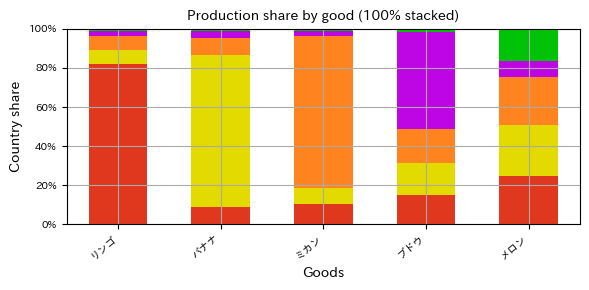

Cell executed in 639.4 ms


In [23]:
# 100%積み上げ棒：棒幅を細くしたいなら bar_width を小さく
fig, ax, _ = plot_prod_share_by_good(
    country_dfs,
    prod_all_goods_each_cols,
    ax=_make_ax(),
    **trade_kwargs,
)

save_fig(ax, trade_others_output_dir, 'country_share')

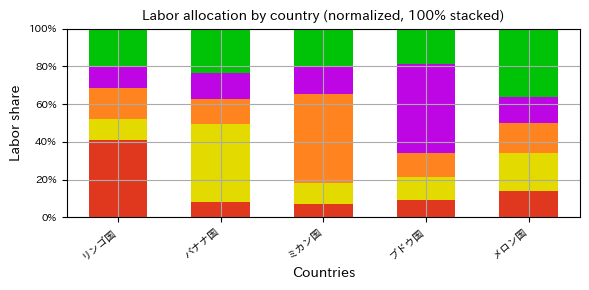

Cell executed in 505.1 ms


In [24]:
fig, ax, _ = plot_labor_allocation_by_country(
    country_dfs,
    labor_stock_all_goods_each_ratio_cols,
    ax=_make_ax(),
    **trade_kwargs,
)

save_fig(ax, trade_others_output_dir, 'labor_share_country_each')

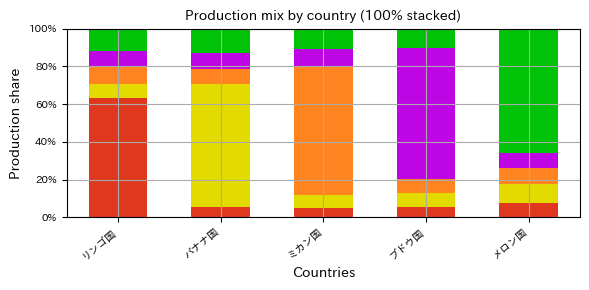

Cell executed in 884.4 ms


In [25]:
fig, ax, _ = plot_prod_mix_by_country(
    country_dfs,
    prod_all_goods_each_cols,
    ax=_make_ax(),
    **trade_kwargs,
)

save_fig(ax, trade_others_output_dir, 'production_goods_each')

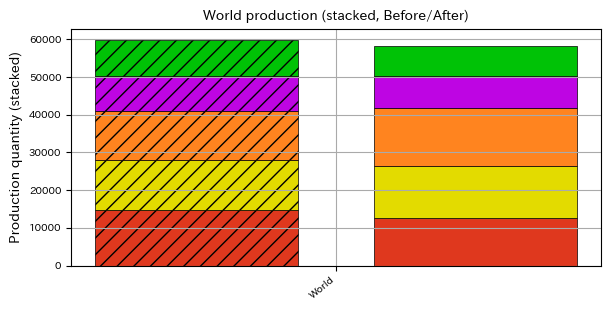

Cell executed in 446.3 ms


In [26]:
# 直近20ステップ平均で世界合計（積み上げ before/after）
fig, ax, wb, wa = plot_world_stacked_before_after(
    wo_trade_country_dfs,
    country_dfs,
    prod_all_goods_each_cols,
    # how=("tail_mean", 20),
    # title="World production (stacked) - last 20-step mean",
    # bar_width=0.35,
    # pair_gap=0.06,
    # legend_fontsize=9,

    ax=_make_ax(),
    **trade_before_after_kwargs,
)

save_fig(ax, trade_others_output_dir, 'production_goods_agg_before_after')

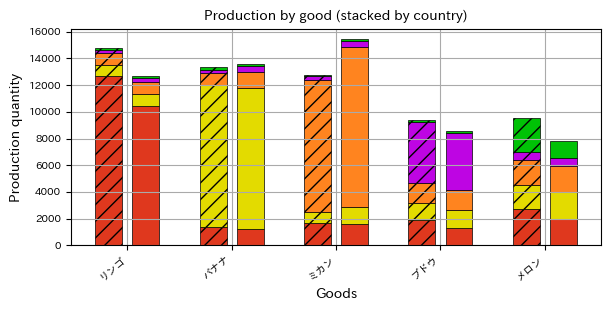

Cell executed in 517.5 ms


In [27]:
fig, ax = plot_prod_by_good_stacked_by_country(
    country_dfs,
    prod_all_goods_each_cols,
    wo_trade_country_dfs=wo_trade_country_dfs,
    ax=_make_ax(),
    **trade_before_after_kwargs,
)

save_fig(ax, trade_others_output_dir, 'production_goods_each_before_after')

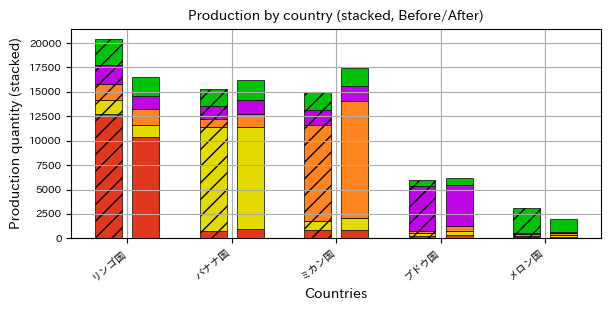

Cell executed in 576.4 ms


In [28]:
before_prod, after_prod, countries = build_before_after_mats(
    wo_trade_country_dfs,
    country_dfs,
    prod_all_goods_each_cols,
    how=trade_how_aggregate,
    clip_negative=True,
)

fig, ax = plot_country_stacked_before_after(
    before_prod,
    after_prod,
    title="Production by country (stacked, Before/After)" if not PLOT_CAMERA_READY else None,
    xlabel="Countries" if not PLOT_CAMERA_READY else None,
    ylabel="Production quantity (stacked)" if not PLOT_CAMERA_READY else None,
    ax=_make_ax(),
    **trade_before_after_kwargs,
)


save_fig(ax, trade_others_output_dir, 'production_country_each_before_after')

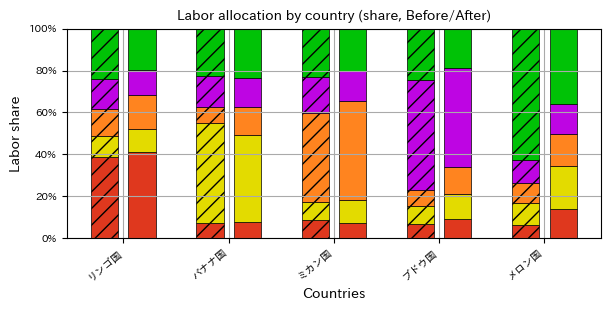

Cell executed in 525.1 ms


In [29]:
before_labor, after_labor, countries = build_before_after_mats(
    wo_trade_country_dfs,
    country_dfs,
    labor_stock_all_goods_each_ratio_cols,
    how=trade_how_aggregate,
    clip_negative=True,
)

before_labor_share = normalize_rows_to_one(before_labor)
after_labor_share  = normalize_rows_to_one(after_labor)

fig, ax = plot_country_stacked_before_after(
    before_labor_share,
    after_labor_share,
    title="Labor allocation by country (share, Before/After)" if not PLOT_CAMERA_READY else None,
    xlabel="Countries" if not PLOT_CAMERA_READY else None,
    ylabel="Labor share" if not PLOT_CAMERA_READY else None,
    as_percent=True,                  # ← 100%表示にする
    ax=_make_ax(),
    **trade_before_after_kwargs,
)

save_fig(ax, trade_others_output_dir, 'labor_share_country_each_before_after')

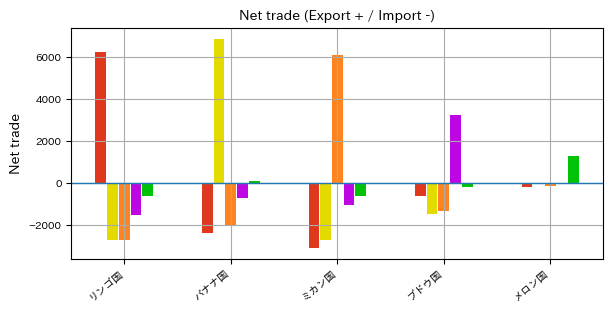

Cell executed in 477.7 ms


In [30]:
# _kwargs = trade_kwargs.copy()
_kwargs = trade_before_after_kwargs.copy()
# _kwargs['bar_width'] = _kwargs['bar_width'] * 0.1
# _kwargs['bar_gap'] = 0.01
_kwargs['bar_width'] = 0.10
_kwargs['bar_gap'] = 0.01
_kwargs['font_scale'] *= 0.75

# net = compute_net_trade(
#     wo_trade_country_dfs,
#     sale_n_cons_goods_each_cols,
#     consump_n_each_cols,
#     how=trade_kwargs['how'],
# )
# fig, ax = plot_trade_net_by_country_goods(
#     net,
#     hatch_all=TRADE_BEFORE_HATCH,   # ← 全棒に網
#     **_kwargs,
# )
# save_fig(ax, trade_others_output_dir, 'net_trade_before')


net = compute_net_trade(
    country_dfs,
    sale_n_cons_goods_each_cols,
    consump_n_each_cols,
    how=trade_how_aggregate,
)
fig, ax = plot_trade_net_by_country_goods(
    net,
    ax=_make_ax(),
    **_kwargs,
)
save_fig(ax, trade_others_output_dir, 'net_trade_after')


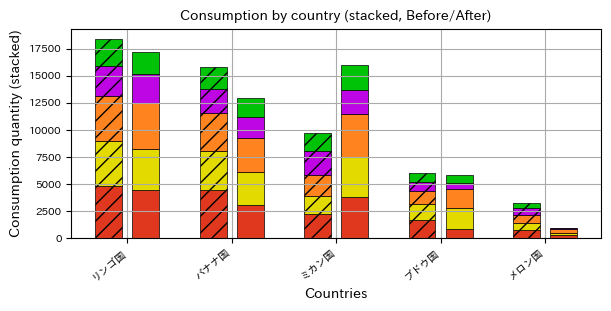

Cell executed in 708.4 ms


In [31]:
before_cons, after_cons, countries = build_before_after_mats(
    wo_trade_country_dfs,
    country_dfs,
    consump_n_each_cols,
    how=trade_how_aggregate,
    clip_negative=True,
)

fig, ax = plot_country_stacked_before_after(
    before_cons,
    after_cons,
    title="Consumption by country (stacked, Before/After)" if not PLOT_CAMERA_READY else None,
    xlabel="Countries" if not PLOT_CAMERA_READY else None,
    ylabel="Consumption quantity (stacked)" if not PLOT_CAMERA_READY else None,
    ax=_make_ax(),
    **trade_before_after_kwargs,
)

save_fig(ax, trade_others_output_dir, 'consump_country_each_before_after')

In [32]:
from __future__ import annotations

from typing import Dict, List, Mapping, Optional, Sequence, Tuple, Union
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def plot_df_left_right_cols(
    df: pd.DataFrame,
    left_cols: Union[str, Sequence[str]],
    right_cols: Optional[Union[str, Sequence[str]]] = None,
    *,
    # x軸
    x_col: Optional[str] = None,          # 指定すれば df[x_col] をxに使う。Noneなら df.index
    sort_by_x: bool = False,              # x_col指定時にxでソートするか（時系列列など）

    # ラベル
    title: Optional[str] = None,
    xlabel: Optional[str] = None,
    left_ylabel: Optional[str] = None,
    right_ylabel: Optional[str] = None,
    col_label_map: Optional[Mapping[str, str]] = None,  # 列名→表示名

    # 色（優先順位: left/right個別 > colors(dict) > colors(list) > palette）
    colors: Optional[Union[Mapping[str, str], Sequence[str]]] = None,
    left_colors: Optional[Union[Mapping[str, str], Sequence[str]]] = None,
    right_colors: Optional[Union[Mapping[str, str], Sequence[str]]] = None,
    palette: str = "tab10",

    # 線のスタイル
    linewidth: float = 1.6,
    alpha: float = 1.0,
    left_plot_kwargs: Optional[dict] = None,
    right_plot_kwargs: Optional[dict] = None,

    # 軸スケール
    left_ylim: Optional[Tuple[Optional[float], Optional[float]]] = None,
    right_ylim: Optional[Tuple[Optional[float], Optional[float]]] = None,
    left_ylim_scale: Optional[Tuple[Optional[float], Optional[float]]] = None,
    right_ylim_scale: Optional[Tuple[Optional[float], Optional[float]]] = None,
    left_yscale: Optional[str] = None,    # "linear" / "log" / ...
    right_yscale: Optional[str] = None,

    # 体裁
    figsize: Tuple[float, float] = FIGSIZE,
    grid: bool = True,

    # フォントサイズ
    title_fontsize: Optional[float] = None,
    label_fontsize: Optional[float] = None,  # 後方互換：xlabel/ylabel_fontsize が None のとき使用
    xlabel_fontsize: Optional[float] = None,
    ylabel_fontsize: Optional[float] = None,
    tick_fontsize: Optional[float] = None,   # x/y 両方の tick label
    xtick_fontsize: Optional[float] = None,  # x だけ上書き
    ytick_fontsize: Optional[float] = None,  # y だけ上書き
    tick_length: Optional[float] = None,
    tick_width: Optional[float] = None,

    # 凡例（左・右をまとめて1つ）
    legend: bool = True,
    legend_loc: str = "best",
    legend_size: Optional[float] = 9,
    legend_ncol: int = 1,
    legend_order: Optional[List[str]] = None,  # 表示順をラベルで指定（存在するものだけ反映）
    legend_frameon: bool = True,
    do_legend_for_right_cols=False,

    # seaborn見た目（局所適用）
    sns_style: str = "whitegrid",
    sns_context: str = "notebook",
    font_scale: float = 1.0,
    rc: Optional[Mapping[str, object]] = None,

    # Notebook表示安定化
    show: bool = False,     # Trueなら display/plt.show を明示
    close: bool = False,    # show後に close するか

    # 既存axに描きたい場合（通常はNoneでOK）
    ax: Optional[plt.Axes] = None,

    # 列が無いときの挙動
    skip_missing: bool = False,  # Falseなら存在しない列があればKeyError
):
    """
    単一dfで、同一グラフに
      - left y-axis: left_cols
      - right y-axis: right_cols（任意）
    をプロットする。

    戻り値: (fig, ax_left, ax_right)
      - ax_right は right_cols が None/空なら None
    """

    def _as_list(x) -> List[str]:
        if x is None:
            return []
        if isinstance(x, str):
            return [x]
        return list(x)

    left_cols_l = _as_list(left_cols)
    right_cols_l = _as_list(right_cols)

    if len(left_cols_l) == 0 and len(right_cols_l) == 0:
        raise ValueError("left_cols/right_cols のどちらかは少なくとも1列指定してください。")

    # 列存在チェック
    all_cols = left_cols_l + right_cols_l
    missing = [c for c in all_cols if c not in df.columns]
    if missing and not skip_missing:
        from warnings import warn
        warn(f"df に存在しない列があります: {missing}")
        return None, None, None
    if skip_missing:
        left_cols_l = [c for c in left_cols_l if c in df.columns]
        right_cols_l = [c for c in right_cols_l if c in df.columns]

    # xの決定
    plot_df = df
    if x_col is not None:
        if x_col not in df.columns:
            raise KeyError(f"x_col '{x_col}' が df.columns にありません。")
        if sort_by_x:
            plot_df = df.sort_values(by=x_col)
        x = plot_df[x_col].to_numpy()
        if xlabel is None:
            xlabel = x_col
    else:
        x = plot_df.index.to_numpy()
        if xlabel is None and not PLOT_CAMERA_READY:
            xlabel = "index"

    # 表示ラベル
    def _label(col: str) -> str:
        if col_label_map is None:
            return col
        return col_label_map.get(col, col)

    # 色解決（dict / list / palette）
    def _color_for(col: str, source) -> Optional[str]:
        if source is None:
            return None
        if isinstance(source, Mapping):
            return source.get(col, None)
        # list/tuple: col順に割当てるのでここでは使わない（後でまとめて割当）
        return None

    # paletteによるデフォルト色（左→右の順で割当）
    default_seq = sns.color_palette(palette, n_colors=max(1, len(left_cols_l) + len(right_cols_l)))
    default_iter = itertools.cycle(default_seq)

    # list指定のときの順序割当（左→右）
    if isinstance(colors, (list, tuple)):
        colors_iter = itertools.cycle(list(colors))
    else:
        colors_iter = None

    # left/right個別 list の場合の割当
    left_list_iter = itertools.cycle(list(left_colors)) if isinstance(left_colors, (list, tuple)) else None
    right_list_iter = itertools.cycle(list(right_colors)) if isinstance(right_colors, (list, tuple)) else None

    def _pick_color(col: str, side: str) -> str:
        # 1) left/right個別 dict
        if side == "left":
            c = _color_for(col, left_colors)
            if c is not None:
                return c
        else:
            c = _color_for(col, right_colors)
            if c is not None:
                return c

        # 2) colors dict
        c = _color_for(col, colors)
        if c is not None:
            return c

        # 3) left/right個別 list
        if side == "left" and left_list_iter is not None:
            return next(left_list_iter)
        if side == "right" and right_list_iter is not None:
            return next(right_list_iter)

        # 4) colors list
        if colors_iter is not None:
            return next(colors_iter)

        # 5) palette
        return next(default_iter)

    # seabornの見た目を局所適用
    left_plot_kwargs = dict(left_plot_kwargs or {})
    right_plot_kwargs = dict(right_plot_kwargs or {})

    with sns.axes_style(sns_style, rc=dict(rc or {})), sns.plotting_context(
        sns_context, font_scale=font_scale, rc=dict(rc or {})
    ):
        if ax is None:
            fig, ax_left = plt.subplots(figsize=figsize)
        else:
            ax_left = ax
            fig = ax_left.figure

        ax_right = None
        if len(right_cols_l) > 0:
            ax_right = ax_left.twinx()

        # left axis plot
        handles = []
        labels = []

        for col in left_cols_l:
            y = plot_df[col].to_numpy()
            line, = ax_left.plot(
                x, y,
                color=_pick_color(col, "left"),
                linewidth=linewidth,
                alpha=alpha,
                label=_label(col),
                **left_plot_kwargs,
            )
            handles.append(line)
            labels.append(_label(col))

        # right axis plot
        if ax_right is not None:
            for col in right_cols_l:
                y = plot_df[col].to_numpy()
                line, = ax_right.plot(
                    x, y,
                    color=_pick_color(col, "right"),
                    linewidth=linewidth,
                    alpha=alpha,
                    label=_label(col),
                    **right_plot_kwargs,
                )
                handles.append(line)
                if do_legend_for_right_cols:
                    labels.append(_label(col))

        # grid（左側に付けるのが自然）
        ax_left.grid(grid)

        # scales
        if left_yscale is not None:
            ax_left.set_yscale(left_yscale)
        if ax_right is not None and right_yscale is not None:
            ax_right.set_yscale(right_yscale)

        # y-limits
        def _maybe(v: Optional[float], default: float) -> float:
            return default if v is None else v

        if left_ylim is not None:
            lo, hi = ax_left.get_ylim()
            ax_left.set_ylim(_maybe(left_ylim[0], lo), _maybe(left_ylim[1], hi))

        if left_ylim_scale is not None:
            lo, hi = ax_left.get_ylim()
            ax_left.set_ylim(
                lo * _maybe(left_ylim_scale[0], 1.0),
                hi * _maybe(left_ylim_scale[1], 1.0),
            )

        if ax_right is not None and right_ylim is not None:
            lo, hi = ax_right.get_ylim()
            ax_right.set_ylim(_maybe(right_ylim[0], lo), _maybe(right_ylim[1], hi))

        if ax_right is not None and right_ylim_scale is not None:
            lo, hi = ax_right.get_ylim()
            ax_right.set_ylim(
                lo * _maybe(right_ylim_scale[0], 1.0),
                hi * _maybe(right_ylim_scale[1], 1.0),
            )

        # labels/title
        if title is not None:
            ax_left.set_title(title, fontsize=title_fontsize)

        _xlabel_fs = xlabel_fontsize if xlabel_fontsize is not None else label_fontsize
        _ylabel_fs = ylabel_fontsize if ylabel_fontsize is not None else label_fontsize

        ax_left.set_xlabel(xlabel, fontsize=_xlabel_fs)
        if left_ylabel is not None:
            ax_left.set_ylabel(left_ylabel, fontsize=_ylabel_fs)
        if ax_right is not None and right_ylabel is not None:
            ax_right.set_ylabel(right_ylabel, fontsize=_ylabel_fs)

        # ticks
        _x_tick_fs = xtick_fontsize if xtick_fontsize is not None else tick_fontsize
        _y_tick_fs = ytick_fontsize if ytick_fontsize is not None else tick_fontsize

        _tp_common = {}
        if tick_length is not None:
            _tp_common["length"] = tick_length
        if tick_width is not None:
            _tp_common["width"] = tick_width

        if (_x_tick_fs is not None) or _tp_common:
            _kw = dict(_tp_common)
            if _x_tick_fs is not None:
                _kw["labelsize"] = _x_tick_fs
            ax_left.tick_params(axis="x", **_kw)

        if (_y_tick_fs is not None) or _tp_common:
            _kw = dict(_tp_common)
            if _y_tick_fs is not None:
                _kw["labelsize"] = _y_tick_fs
            ax_left.tick_params(axis="y", **_kw)
            if ax_right is not None:
                ax_right.tick_params(axis="y", **_kw)

        # legend（左右の線をまとめて1つ）
        if legend:
            # 順序指定（legend_orderは“表示ラベル”で指定）
            if legend_order is not None:
                order_map = {name: i for i, name in enumerate(legend_order)}
                zipped = list(zip(handles, labels))
                # order_mapに無いものは後ろへ
                zipped.sort(key=lambda hl: order_map.get(hl[1], 10**9))
                handles, labels = zip(*zipped) if zipped else ([], [])

            ax_left.legend(
                handles, labels,
                loc=legend_loc,
                fontsize=legend_size,
                ncol=legend_ncol,
                frameon=legend_frameon,
            )

        fig.tight_layout()

        # Notebookでの「2回目以降出ない」対策：明示表示オプション
        if show:
            try:
                from IPython.display import display
                display(fig)
            except Exception:
                plt.show()
            if close:
                plt.close(fig)

    return fig, ax_left, ax_right


Cell executed in 10.4 ms


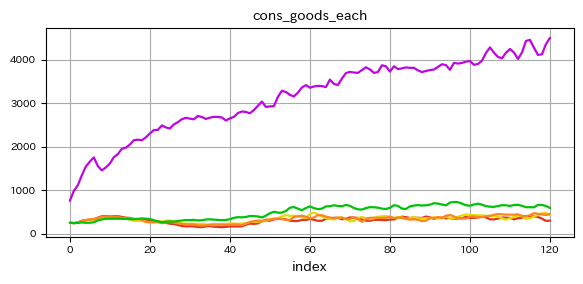

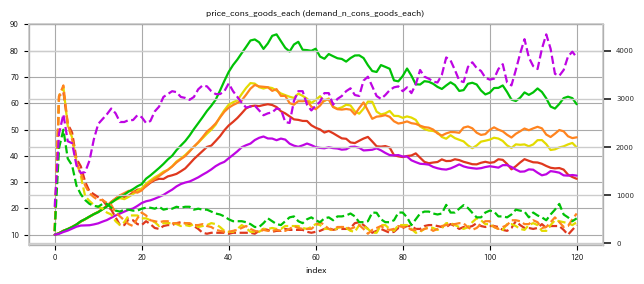

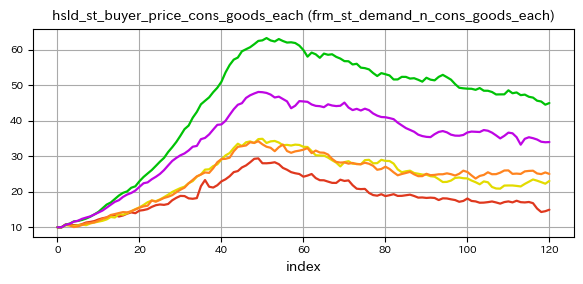

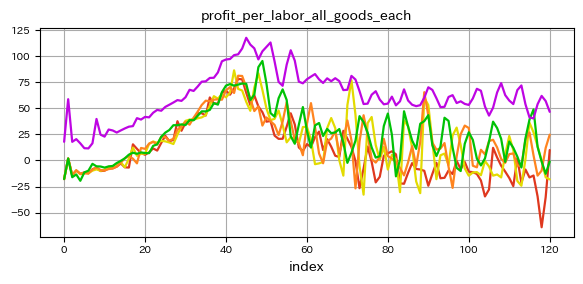

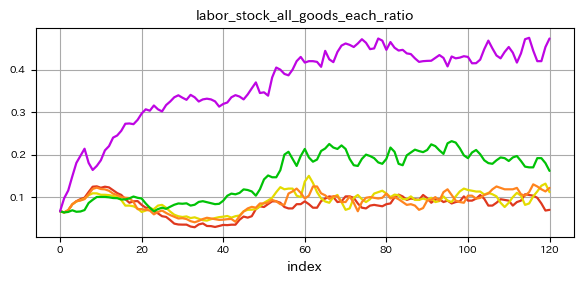

Cell executed in 2.113 s


In [33]:
if PLOT == 'recardian_trade':
    country_fruit = 'Grapes'
elif PLOT == 'tariff_war':
    country_fruit = 'Apple'
    # country_fruit = 'Banana'
    # country_fruit = 'Orange'
    # country_fruit = 'Grapes'
    # country_fruit = 'WaterMelon'



if PLOT in ['recardian_trade', 'tariff_war']:
    major_country = f'Econ{country_fruit}Country'
    country = [df for _country, df in country_dfs.items()
               if _country.find(country_fruit) >= 0][0]

    def plot(left_cols, filename, right_cols=None, **kwargs):
        _colors = {}
        _labol_map = {}
        
        for col in left_cols:
            for good, color in ECON_FRUIT_COLORS.items():
                if col.find(good) >= 0:
                    _colors[col] = color
                    break
        for col in left_cols:
            _labol_map[col] = re.sub('.*->(.*)', '\g<1>', col)

        if right_cols is not None:
            for col in right_cols:
                for good, color in ECON_FRUIT_COLORS.items():
                    if col.find(good) >= 0:
                        _colors[col] = color
                        break
            for col in right_cols:
                _labol_map[col] = re.sub('.*->(.*)', '\g<1>', col)

        left_major_col = [col for col in left_cols if col.find(country_fruit) >= 0][0]
        left_cols_ordered = [col for col in left_cols if col != left_major_col] + [left_major_col]
 
        _kwargs = trade_timeseries_kwargs.copy() | kwargs.copy()
        if right_cols is not None:
            right_major_col = [col for col in right_cols if col.find(country_fruit) >= 0][0]
            right_cols_ordered = [col for col in right_cols if col != right_major_col] + [right_major_col]
            _kwargs.update({
                'title_fontsize' : int(_kwargs['title_fontsize'] * 2/3),
                'xlabel_fontsize': int(_kwargs['xlabel_fontsize'] * 2/3),
                'ylabel_fontsize': int(_kwargs['ylabel_fontsize'] * 2/3),
                'xtick_fontsize' : int(_kwargs['xtick_fontsize'] * 2/3),
                'ytick_fontsize' : int(_kwargs['ytick_fontsize'] * 2/3),
            })
            figsize = (FIGSIZE[0] * 1.1, FIGSIZE[1])
        else:
            right_major_col = None
            right_cols_ordered = None
            figsize = FIGSIZE
            
        fig, axL, axR = plot_df_left_right_cols(
            country,
            left_cols=left_cols_ordered,
            right_cols=right_cols_ordered,
            legend_order=[_labol_map[col] for col in left_cols]\
                + ([_labol_map[col] for col in right_cols] if right_cols is not None else []),
            ax=_make_ax(figsize=figsize),
            colors=_colors,
            col_label_map=_labol_map,
            **_kwargs,
        )
        if axL is not None:
            save_fig(axL, trade_others_output_dir, filename)

    plot(
        [
            'ctr.frm_st_prod_cons_goods_each->EconApple',
            'ctr.frm_st_prod_cons_goods_each->EconBanana',
            'ctr.frm_st_prod_cons_goods_each->EconOrange',
            'ctr.frm_st_prod_cons_goods_each->EconGrapes',
            'ctr.frm_st_prod_cons_goods_each->EconWatermelon',
        ],
        'timeseries.prod_cons_goods_each',
        title='cons_goods_each' if not PLOT_CAMERA_READY else None,
    )


    plot(
        [
            'ctr.frm_st_price_cons_goods_each->EconApple',
            'ctr.frm_st_price_cons_goods_each->EconBanana',
            'ctr.frm_st_price_cons_goods_each->EconOrange',
            'ctr.frm_st_price_cons_goods_each->EconGrapes',
            'ctr.frm_st_price_cons_goods_each->EconWatermelon',
        ],
        'timeseries.price_cons_goods_each',
        right_cols=[
            'ctr.frm_st_demand_n_cons_goods_each->EconApple',
            'ctr.frm_st_demand_n_cons_goods_each->EconBanana',
            'ctr.frm_st_demand_n_cons_goods_each->EconOrange',
            'ctr.frm_st_demand_n_cons_goods_each->EconGrapes',
            'ctr.frm_st_demand_n_cons_goods_each->EconWatermelon',
        ],
        do_legend_for_right_cols=False,
        title='price_cons_goods_each (demand_n_cons_goods_each) ' if not PLOT_CAMERA_READY else None,
    )


    plot(
        [
            'ctr.hsld_st_buyer_price_cons_goods_each->EconApple',
            'ctr.hsld_st_buyer_price_cons_goods_each->EconBanana',
            'ctr.hsld_st_buyer_price_cons_goods_each->EconOrange',
            'ctr.hsld_st_buyer_price_cons_goods_each->EconGrapes',
            'ctr.hsld_st_buyer_price_cons_goods_each->EconWatermelon',
        ],
        'timeseries.hsld_st_buyer_price_cons_goods_each',
        # right_cols=[
        #     'ctr.frm_st_demand_n_cons_goods_each->EconApple',
        #     'ctr.frm_st_demand_n_cons_goods_each->EconBanana',
        #     'ctr.frm_st_demand_n_cons_goods_each->EconOrange',
        #     'ctr.frm_st_demand_n_cons_goods_each->EconGrapes',
        #     'ctr.frm_st_demand_n_cons_goods_each->EconWatermelon',
        # ],
        do_legend_for_right_cols=False,
        title='hsld_st_buyer_price_cons_goods_each (frm_st_demand_n_cons_goods_each)' if not PLOT_CAMERA_READY else None,
    )

    
    plot(
        [
            'ctr.frm_st_profit_per_labor_all_goods_each->EconApple',
            'ctr.frm_st_profit_per_labor_all_goods_each->EconBanana',
            'ctr.frm_st_profit_per_labor_all_goods_each->EconOrange',
            'ctr.frm_st_profit_per_labor_all_goods_each->EconGrapes',
            'ctr.frm_st_profit_per_labor_all_goods_each->EconWatermelon',
        ],
        'timeseries.profit_per_labor_all_goods_each',
        # left_ylim_scale=(0.5, 0.2),
        # left_ylim_scale=(0.5, 0.5),
        title='profit_per_labor_all_goods_each' if not PLOT_CAMERA_READY else None,
    )
# 
# 
    plot(
        [
            'ctr.frm_st_labor_stock_all_goods_each_ratio->EconApple',
            'ctr.frm_st_labor_stock_all_goods_each_ratio->EconBanana',
            'ctr.frm_st_labor_stock_all_goods_each_ratio->EconOrange',
            'ctr.frm_st_labor_stock_all_goods_each_ratio->EconGrapes',
            'ctr.frm_st_labor_stock_all_goods_each_ratio->EconWatermelon',
        ],
        'timeseries.labor_stock_all_goods_each_ratio',
        title='labor_stock_all_goods_each_ratio' if not PLOT_CAMERA_READY else None,
    )


## economic growth

In [34]:
if PLOT in ['economic_growth', 'economic_growth_with_component_ablation']:
    all_targets = ['0+1+2+3'] if PLOT == 'economic_growth_with_component_ablation' else ['0+1']
    
    plot_settings = [
        {
            'left_col': 'wld.st_real_gdp',
            'right_col': None,
            'targets': all_targets,
        },
        
    
        {
            'left_col': 'wld.frm_st_value_all_goods_agg',
            'targets': all_targets,
        },
    
        
        # {
        #     'left_col': 'wld.frm_st_growth_accounting_accum_goods_labor_all_goods_agg',
        #     'right_col': 'wld.frm_st_labor_stock_all_goods_agg',
        #     'targets': all_targets,
        #     
        #     'left_ylim': (-0.4, 1.0),
        #     'right_ylim_scale': (0.5, 1.5),
        # },
    # 
        # 
        # {
        #     'left_col': 'wld.frm_st_growth_accounting_accum_cap_all_goods_agg',
        #     'right_col': 'wld.frm_st_cap_stock_all_goods_agg',
        #     'targets': all_targets,
        #     
        #     'left_ylim': (-0.4, 1.0),
        # },
        # 
        # 
        # {
        #     'left_col': 'wld.frm_st_growth_accounting_accum_idea_all_goods_agg',
        #     'right_col': 'wld.frm_st_idea_stock_all_goods_agg',
        #     'targets': all_targets,
        #     
        #     'left_ylim': (-0.4, 1.0),
        # },
    
        
        {
            'left_col': 'wld.frm_st_growth_accounting_accum_goods_labor_all_goods_agg',
            'targets': all_targets,
            
            'left_ylim': (-0.4, 1.1),
            'right_ylim_scale': (0.5, 1.5),
        },
    
        
        {
            'left_col': 'wld.frm_st_growth_accounting_accum_cap_all_goods_agg',
            'targets': all_targets,
            
            'left_ylim': (-0.4, 1.1),
        },
        
        
        {
            'left_col': 'wld.frm_st_growth_accounting_accum_idea_all_goods_agg',
            'targets': all_targets,
            
            'left_ylim': (-0.4, 1.1),
        },
    
    
        {
            'left_col': 'wld.frm_st_labor_stock_all_goods_agg',
            'targets': all_targets,
            'left_ylim_scale': (0.5, 1.5),
        },
    
        
        {
            'left_col': 'wld.frm_st_cap_stock_all_goods_agg',
            'targets': all_targets,
        },
        
        
        {
            'left_col': 'wld.frm_st_idea_stock_all_goods_agg',
            'targets': all_targets,
        },
    
    
        {
            'left_col': 'wld.frm_st_cap_investment_ratio',
            'right_col': 'wld.frm_st_labor_stock_R_D_ratio',
            'targets': ['-1'],
            
            'left_ylim': (0.0, 0.5),
            'right_ylim': (0.0, 0.7),
        },
        
        
        {
            'left_col': 'wld.frm_st_cap_investment_cash_actual',
            'targets': ['-1'],
            'left_ylim_scale': (0.5, 2.0),
        },
    
        
        {
            'left_col': 'wld.frm_st_labor_stock_all_sectors_agg',
            'targets': ['-1'],
            'left_ylim_scale': (0.5, 2.0),
        },
       
    
        {
            'left_col': 'wld.frm_st_prod_cons_goods_agg',
            'right_col': 'wld.frm_st_demand_n_cons_goods_agg',
            'targets': ['-1'],
            
            # 'left_ylim': (2500, 6500),
            'left_right_same_scale': True,
        },
    
        {
            'left_col': 'wld.frm_st_value_cons_goods_agg',
            'right_col': 'wld.frm_st_demand_value_cons_goods_agg',
            'targets': ['-1'],
            
            # 'left_ylim': (2500, 6500),
            'left_right_same_scale': True,
        },
    
        
        {
            'left_col': 'wld.frm_st_price_cons_goods_agg',
            'targets': ['-1'],
        },
        
     
        {
            'left_col': 'wld.frm_st_sale_n_cap_goods_agg',
            'targets': ['-1'],
            'left_ylim_scale': (0.5, 1.5),
        },
    ]

    
    output_dir = OUTPUT_TOP_DIR / 'plots'
    no_label = True
    if PLOT_CAMERA_READY:
        val_factors = {
            'wld.frm_st_growth_accounting_accum_cap_all_goods_agg': [1.20, None, None, None],
            'wld.frm_st_cap_stock_all_goods_agg': [1.30, None, None, None],
            
            'wld.frm_st_growth_accounting_accum_idea_all_goods_agg': [20, None, None, None],
            'wld.frm_st_idea_stock_all_goods_agg': [1.03, None, None, None],
        }
    else:
        val_factors = {}
    plot_dfs_with_right_from_settings(world_dfs,
                                      plot_settings,
                                      legend_order=[0, 3, 1, 2],
                                      other_run_dfs=other_run_world_dfs,
                                      output_dir=output_dir,
                                      colors=COLORS,
                                      df_labels=DF_LABELS,
                                      do_legend_for_output=False,
                                      val_factors=val_factors)

Cell executed in 2.7 ms


# saver vs spender

In [35]:
if PLOT == 'saver_vs_spender':
    
    if LOG_PATHS[-1].find('gpt-5.1') >= 0 or LOG_PATHS[-1].find('claude-haiku-4-5') >= 0:
        end_timestep = 140
        gdp_ylim_scale = (1.0, 0.5)
    else:
        end_timestep = None
        # gdp_ylim_scale = None
        gdp_ylim_scale = (1.0, 0.8)
    
    # value_based_demand_ylim_scale = (-0.05, 1.0)
    # value_based_demand_ylim_scale = None
    value_based_demand_ylim = (-3000, None)
    
    
    plot_settings = [
    
       
        {
            'left_col': 'wld.st_real_gdp',
            # 'right_col': 'wld.frm_st_cap_factor_norm_all_goods_agg',
            'right_col': 'wld.frm_st_growth_accounting_accum_cap_all_goods_agg',
            'targets': ['0+1'],
            'left_ylim_scale': gdp_ylim_scale,
        },
    
        
        {
            'left_col': 'wld.frm_st_value_all_goods_agg',
            'targets': ['0+1'],
            'left_ylim_scale': gdp_ylim_scale,
        },
        
        
        {
            'left_col': 'wld.frm_st_growth_accounting_accum_goods_labor_all_goods_agg',
            'right_col': 'wld.frm_st_labor_stock_all_goods_agg',
            'targets': ['0+1'],
            
            'left_ylim': (-0.4, 1.4),
            'right_ylim_scale': (1.0, 1.4),
            # 'shift_right_ylim_bit': True,
        },
    
        
        {
            'left_col': 'wld.frm_st_growth_accounting_accum_cap_all_goods_agg',
            'right_col': 'wld.frm_st_cap_stock_all_goods_agg',
            'targets': ['0+1'],
            
            'left_ylim': (-0.4, 1.4),
        },
        
        
        {
            'left_col': 'wld.frm_st_growth_accounting_accum_idea_all_goods_agg',
            'right_col': 'wld.frm_st_idea_stock_all_goods_agg',
            'targets': ['0+1'],
            
            'left_ylim': (-0.4, 1.4),
        },
       
        
        {
            'left_col': 'wld.hsld_st_monthly_saving_rate_macro',
            'right_col': 'wld.hsld_st_demand_n_cons_goods_agg',
            'targets': ['0+1'],
            'right_ylim': (-0.5, 1.4),
            # 'right_ylim': (-5000, 130000),
        },
    
        
        {
            'left_col': 'wld.frm_st_labor_stock_cap_goods_agg_ratio',
            'right_col': 'wld.frm_st_prod_cap_goods_agg',
            'right_ylim_scale': (0.8, 1.4),
            'targets': ['0+1'],
        },
    
        
        {
            # 'left_col': 'wld.frm_st_prod_cap_goods_agg'",
            'left_col': 'wld.frm_st_price_cap_goods_excl_generic_agg',
            'targets': ['0+1'],
        },
    
        
        {
            'left_col': 'wld.frm_st_cap_investment_ratio',
            'right_col': 'wld.frm_st_cap_investment_cash_actual',
            'targets': ['0+1'],
            
            'left_ylim': (0.0, 0.5),
            # 'right_ylim': (0.0, 0.5),
            'shift_right_ylim_bit': True,
            'right_ylim_scale': (0.5, 1.5),
        },
    
        
        {
            'left_col': 'wld.frm_st_sale_n_cap_goods_agg',
            'targets': ['0+1'],
            'left_ylim_scale': (0.0, 2.0),
        },
    
        
        {
            'left_col': 'wld.frm_st_labor_stock_all_sectors_agg',
            'right_col': 'wld.frm_st_labor_stock_R_D_ratio',
            'targets': ['0+1'],
            # 'left_ylim_scale': (1.0, 1.5),
            'right_ylim': (0.0, 0.5),
        },
    
    
    
    
    
    
    
    
    
    
    
    
    
    
        
    
    
    
    
    
        
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->DailyHouseholdConsumablesBundle',
            'targets': ['1'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->Breakfast',
            'targets': ['1'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->Lunch',
            'targets': ['1'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->Dinner',
            'targets': ['1'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->PaperbackBook',
            'targets': ['1'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->MidRangeRestaurantDinner',
            'targets': ['1'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->MovieTicket',
            'targets': ['1'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->SportsEventTicket',
            'targets': ['1'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->VideoGameNewRelease',
            'targets': ['1'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->LocalDayTripBudget',
            'targets': ['1'],
            'left_ylim': value_based_demand_ylim,
        },
    
    
    
    
     
    
    
    
    
        
    ]
    

    output_dir = OUTPUT_TOP_DIR / 'plots' if OUTPUT_TOP_DIR is not None else None
    plot_dfs_with_right_from_settings(world_dfs,
                                      plot_settings,
                                      end_timestep=end_timestep,
                                      other_run_dfs=other_run_world_dfs,
                                      colors=COLORS_COMPARISON,
                                      df_labels=DF_LABELS,
                                      output_dir=output_dir)


Cell executed in 2.7 ms


## R_D vs non-R_D

In [36]:
if PLOT in ['R_D_vs_non-R_D', 'R_D_vs_non-R_D.other_llms']:
    
    
    if LOG_PATHS[-1].find('gemini') >= 0 and LOG_PATHS[-1].find('wo_') < 0:
        end_timestep = 250
        gdp_ylim_scale = (1.0, 0.7)
    elif LOG_PATHS[-1].find('gpt-5.1') >= 0:
        end_timestep = 300
        gdp_ylim_scale = (1.0, 0.4)
    else:
        end_timestep = None
        gdp_ylim_scale = None
    
    
    
    
    plot_settings = [
        {
            'left_col': 'wld.st_real_gdp',
            'targets': ['0+1'],
            'end_timestep': end_timestep,
            'left_ylim_scale': gdp_ylim_scale,
        },
    
        
        {
            'left_col': 'wld.frm_st_value_all_goods_agg',
            'targets': ['0+1'],
            'end_timestep': end_timestep,
            'left_ylim_scale': gdp_ylim_scale,
        },
       
        {
            'left_col': 'wld.frm_st_growth_accounting_accum_idea_all_goods_agg',
            'right_col': 'wld.frm_st_idea_stock_all_goods_agg',
            'targets': ['0+1'],
            
            # 'left_ylim': (-0.4, 1.2),
        },
    
    
        {
            'left_col': 'wld.frm_st_growth_accounting_accum_idea_all_goods_agg',
            'right_col': 'wld.frm_st_growth_accounting_accum_cap_all_goods_agg',
            'targets': ['0+1'],
            'hetero_plot': True,
            # 'left_right_same_scale': True,
            'left_ylim_scale': (1.0, 1.3),
            
            # 'left_ylim': (-0.4, 1.2),
        },
    
    
        # {
        #     'left_col': 'wld.frm_st_labor_stock_R_D_ratio',
        #     'right_col': 'wld.frm_st_labor_stock_all_sectors_agg',
        #     'targets': ['0+1'],
        #     # 'left_ylim': (0.0, 0.5),
        #     'right_ylim_scale': (0.5, 1.5),
        # },
    
        {
            'left_col': 'wld.frm_st_labor_stock_R_D_ratio',
            'right_col': 'wld.frm_st_growth_accounting_accum_goods_labor_all_goods_agg',
            'targets': ['0+1'],
            # 'left_ylim': (0.0, 0.5),
            # 'right_ylim_scale': (0.5, 1.5),
        },
    
    
    
    
        {
            'left_col': 'wld.frm_st_growth_accounting_accum_goods_labor_all_goods_agg',
            'right_col': 'wld.frm_st_labor_stock_all_goods_agg',
            'targets': ['0+1'],
            
            # 'left_ylim': (-0.4, 1.2),
            # 'right_ylim': (5000, 1.200),
            # 'shift_right_ylim_bit': True,
        },
    
    
    
        {
            'left_col': 'wld.frm_st_growth_accounting_accum_cap_all_goods_agg',
            'right_col': 'wld.frm_st_cap_stock_all_goods_agg',
            'targets': ['0+1'],
            
            # 'left_ylim': (-0.4, 1.2),
        },
    
    
    
     
    
    
        {
            # 'left_col': 'wld.frm_st_labor_stock_R_D_ratio',
            'left_col': 'wld.frm_st_labor_stock_all_sectors_agg',
            'targets': ['0+1'],
            # # 'left_ylim': (0, 2500),
        },
        
        {
            # 'left_col': 'wld.frm_st_labor_stock_R_D_ratio',
            'left_col': 'wld.frm_st_labor_stock_all_goods_agg',
            'targets': ['0+1'],
            # # 'left_ylim': (0, 2500),
        },
    
        {
            # 'left_col': 'wld.frm_st_labor_stock_R_D_ratio',
            'left_col': 'wld.frm_st_R_D_labor_stock_all_goods_agg',
            'targets': ['0+1'],
            # # 'left_ylim': (0, 1.20),
        },
    
        # {
        #     'left_col': 'wld.frm_st_cap_investment_ratio',
        #     'right_col': 'wld.frm_st_cap_investment_cash_actual',
        #     'targets': ['0+1'],
        # },
        
    ]


    output_dir = OUTPUT_TOP_DIR / 'plots'
    plot_dfs_with_right_from_settings(world_dfs,
                                      plot_settings,
                                      other_run_dfs=other_run_world_dfs,
                                      output_dir=output_dir,
                                      colors=COLORS_COMPARISON,
                                      df_labels=DF_LABELS)

Cell executed in 1.9 ms


# meteor

In [37]:
if PLOT in ['meteor', 'meteor.other_llms']:
    
    end_timestep = None
    # end_timestep = 119
    
    value_based_demand_agg_ylim = (-0.3e07, 1e08)
    value_based_demand_ylim = (-0.3e07, 3e07)
    
    
    plot_settings = [
        {
            'left_col': 'wld.st_real_gdp',
            'right_col': 'wld.frm_st_labor_stock_all_sectors_agg',
            'targets': ['0'],
            # 'left_ylim': [1.05e6, 1.52e6],
        },
    
    
        
        {
            'left_col': 'wld.frm_st_value_all_goods_agg',
            'right_col': 'wld.frm_st_labor_stock_all_sectors_agg',
            'targets': ['0'],
        },
     
        
        # {
        #     'left_col': 'wld.frm_st_labor_stock_all_sectors_agg',
        #     'right_col': 'wld.frm_st_growth_accounting_accum_goods_labor_all_goods_agg',
        #     'targets': ['0'],
        # },
    
    
        # {
        #     'left_col': 'wld.frm_st_demand_value_cons_goods_agg',
        #     'right_col': 'wld.frm_st_labor_stock_cap_goods_agg_ratio',
        #     'targets': ['0'],
        #     # 'right_ylim': [0.0, 0.6],
        # },
    
    
        
        {
            'left_col': 'wld.frm_st_demand_value_cons_goods_agg',
            # 'right_col': 'wld.frm_st_labor_stock_cap_goods_agg_ratio',
            'right_col': 'wld.frm_st_price_cons_goods_agg',
            'targets': ['0'],
            # 'right_ylim': [0.0, 0.6],
        },  
    
        {
            'left_col': 'wld.frm_st_demand_value_cons_luxury_goods_agg',
            'right_col': 'wld.frm_st_demand_value_cons_necessity_goods_agg',
            'targets': ['0'],
            'left_right_same_scale': True,
            'left_ylim': value_based_demand_agg_ylim,
            # 'right_ylim': [0.0, 0.6],
        },  
    
    
        {
            'left_col': 'wld.frm_st_labor_stock_R_D_ratio',
            'right_col': 'wld.frm_st_cap_investment_ratio',
            'targets': ['0'],
            'left_ylim': (0.0, 0.3),
            'right_ylim': (0.0, 0.2),
        },
    
    
    
        # {
        #     'left_col': 'wld.frm_st_price_cons_goods_agg',
        #     'targets': ['0'],
        # },
    
    
    
    
    
    
        
    
    
    
        
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->DailyHouseholdConsumablesBundle',
            'targets': ['0'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->Breakfast',
            'targets': ['0'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->Lunch',
            'targets': ['0'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->Dinner',
            'targets': ['0'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->PaperbackBook',
            'targets': ['0'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->MidRangeRestaurantDinner',
            'targets': ['0'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->MovieTicket',
            'targets': ['0'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->SportsEventTicket',
            'targets': ['0'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->VideoGameNewRelease',
            'targets': ['0'],
            'left_ylim': value_based_demand_ylim,
        },
    
        {
            'left_col': 'wld.frm_st_demand_value_all_goods_each->LocalDayTripBudget',
            'targets': ['0'],
            'left_ylim': value_based_demand_ylim,
        },
    
    
    
    
        
        # {
        #     'left_col': 'wld.frm_st_demand_n_cons_goods_each->Breakfast',
        #     'targets': ['0'],
        # },
    # 
        # {
        #     'left_col': 'wld.frm_st_demand_n_cons_goods_each->Lunch',
        #     'targets': ['0'],
        # },
    # 
        # {
        #     'left_col': 'wld.frm_st_demand_n_cons_goods_each->Dinner',
        #     'targets': ['0'],
        # },
    # 
        # {
        #     'left_col': 'wld.frm_st_demand_n_cons_goods_each->MidRangeRestaurantDinner',
        #     'targets': ['0'],
        # },
    # 
        # {
        #     'left_col': 'wld.frm_st_demand_n_cons_goods_each->DailyHouseholdConsumablesBundle',
        #     'targets': ['0'],
        # },
    # 
        # {
        #     'left_col': 'wld.frm_st_demand_n_cons_goods_each->MovieTicket',
        #     'targets': ['0'],
        # },
    # 
        # {
        #     'left_col': 'wld.frm_st_demand_n_cons_goods_each->SportsEventTicket',
        #     'targets': ['0'],
        # },
    # 
    # 
        # {
        #     'left_col': 'wld.frm_st_demand_n_cons_goods_each->PaperbackBook',
        #     'targets': ['0'],
        # },
    # 
        # {
        #     'left_col': 'wld.frm_st_demand_n_cons_goods_each->VideoGameNewRelease',
        #     'targets': ['0'],
        # },
    # 
        # {
        #     'left_col': 'wld.frm_st_demand_n_cons_goods_each->LocalDayTripBudget',
        #     'targets': ['0'],
        # },
    
    
    
        {
            'left_col': 'wld.hsld_st_cash_balance',
            'targets': ['0'],
        },
        {
            'left_col': 'wld.hsld_st_bond_balance',
            'targets': ['0'],
        },
        
        {
            'left_col': 'wld.frm_st_cash_balance',
            'targets': ['0'],
        },
        {
            'left_col': 'wld.frm_st_bond_balance',
            'targets': ['0'],
        },
    ]
    
    
    
    

    output_dir = OUTPUT_TOP_DIR / 'plots'
    plot_dfs_with_right_from_settings(world_dfs,
                                      plot_settings,
                                      other_run_dfs=other_run_world_dfs,
                                      output_dir=output_dir,
                                      colors=COLORS_COMPARISON,
                                      df_labels=DF_LABELS,
                                      end_timestep=end_timestep)

Cell executed in 2.5 ms


## Regression

In [38]:
if PLOT == 'regression':
    plot_settings = [
        {
            'left_col': 'wld.st_real_gdp',
            'right_col': None,
            'targets': ['0'],
            
            # 'left_ylim_scale': (10, 1.1),   # original ylim[0] is negative. we scale it by 10 for 見栄え
        },
        
        {
            'left_col': 'wld.frm_st_prod_all_goods_agg',
            'right_col': None,
            'targets': ['0'],
            
            # 'left_ylim_scale': (10, 1.1),   # as 
        },
        
        {
            'left_col': 'wld.frm_st_goods_labor_factor_norm_all_goods_agg',
            'right_col': 'wld.frm_st_labor_stock_all_goods_agg',
            'targets': ['0'],
            
            'left_ylim_scale': (0.8, 1.2),
            'shift_right_ylim_bit': True,
        },
        
        {
            'left_col': 'wld.frm_st_cap_factor_norm_all_goods_agg',
            'right_col': 'wld.frm_st_cap_stock_all_goods_agg',
            'targets': ['0'],
            
            'left_ylim_scale': (0.8, 1.2),
        },
        
        {
            'left_col': 'wld.frm_st_idea_factor_norm_all_goods_agg',
            'right_col': 'wld.frm_st_idea_stock_all_goods_agg',
            'targets': ['0'],
            
            'left_ylim_scale': (0.8, 1.2),
        },
    
        {
            'left_col': 'wld.frm_st_labor_stock_cap_goods_agg_ratio',
            # 'right_col': 'wld.frm_st_cap_investment_cash_actual',
            'targets': ['0'],
            
            # 'left_ylim': (0.0, 0.5),
        },
        
        {
            'left_col': 'wld.frm_st_cap_investment_ratio',
            'right_col': 'wld.frm_st_cap_investment_cash_actual',
            'targets': ['0'],
            
            'left_ylim': (0.0, 0.5),
        },
        
        {
            'left_col': 'wld.frm_st_labor_stock_R_D_ratio',
            'right_col': 'wld.frm_st_labor_stock_all_goods_agg',
            # 'right_col': 'wld.frm_st_labor_stock_R_D',
            'targets': ['0'],
            
            'left_ylim': (0.0, 0.5),
        },
    
        {
            'left_col': 'wld.frm_st_prod_all_goods_agg',
            'right_col': 'wld.frm_st_demand_n_all_goods_agg',
            'targets': ['0'],
            
            # 'left_ylim_scale': (1.0, 0.5),
            'left_right_same_scale': True,
        },
    
        {
            'left_col': 'wld.frm_st_prod_all_goods_agg',
            'right_col': 'wld.st_all_goods_demand',
            'targets': ['0'],
            
            # 'left_ylim_scale': (1.0, 0.5),
            'left_right_same_scale': True,
        },
    
        {
            'left_col': 'wld.frm_st_prod_all_goods_agg',
            'right_col': 'wld.st_all_goods_demand_decision',
            'targets': ['0'],
            
            # 'left_ylim_scale': (1.0, 0.5),
            'left_right_same_scale': True,
        },
        
        {
            'left_col': 'wld.frm_st_all_goods_price',
            'targets': ['0'],
        },
    
    
    
    
        {
            'left_col': 'wld.frm_st_sale_n_cap_goods_agg',
            'targets': ['0'],
        },
    ]




    output_dir = OUTPUT_TOP_DIR / 'plots'
    no_label = True
    plot_dfs_with_right_from_settings(world_dfs,
                                      plot_settings,
                                      other_run_dfs=other_run_world_dfs,
                                      output_dir=output_dir,
                                      colors=COLORS_COMPARISON,
                                      df_labels=DF_LABELS,
                                      do_legend_for_output=True)

Cell executed in 1.6 ms


In [39]:
# Decision Making

Cell executed in 0.3 ms


In [40]:
def prettify_agg_agents_df(mean_df, std_df, shostd=True, factor=None, no_space_before_symbol=False):
    mean_df = mean_df.drop(columns=['llm', 'history'])
    std_df = std_df.drop(columns=['llm', 'history'])

    def is_cash(col_name: str) -> bool:
        for end_keyword in ['sales', 'price', 'cost', 'wage']:
            if col_name.endswith(end_keyword):
                return True
        for mid_keyword in ['cash_flow', 'earnings', 'investment', 'profit']:
            if col_name.find(mid_keyword) >= 0:
                return True

    def my_round(val, is_cash):
        abs_val = abs(val)
        if is_cash:
            if val < 0:
                val_abs = - val
                prefix = RIGHT_LINESTYLE
            else:
                val_abs = val
                prefix = ''

            if abs_val >= 100:
                return f'{prefix} \${val_abs:,.0f}'
            elif abs_val >= 10:
                return f'{prefix} \${val_abs:,.1f}'
            else:
                return f'{prefix} \${val_abs:,.2f}'
        else:
            if abs_val >= 100:
                return f'{val:.0f}'
            elif abs_val >= 10:
                return f'{val:.1f}'
            else:
                return f'{val:.2f}'

    def prettify_cell(mean, std, col_name):
        if factor is not None:
            mean = factor * mean

        _is_cash = is_cash(col_name)
        if shostd:
            return concat_mean_std(my_round(mean, _is_cash), my_round(std, _is_cash))
        else:
            return my_round(mean, _is_cash)

    merged_df = elementwise_merge_df(mean_df, std_df, lambda col, row_index, mean, std: prettify_cell(mean, std, col))
    return rename_df_by_nicknames(merged_df, col_only_symbol=True, row_only_symbol=False)


def concat_mean_std(mean, std) -> str:
    # return f'{mean}$_{{\pm {std}}}$'

    # 16.1$_{\pm{\mbox{\tiny 0.9}}}$
    # return f'{mean}' + r'$_{ \pm{ \mbox{ \tiny ' + f'{std}' + r' } } }$'

    # -0.51_{\scalebox{0.5}{$\pm 0.061$}}
    return f'{mean}' + r'$_{ \scalebox{0.5}{$\pm ' + f'{std}' + r'$} }$'


def split_mean_std(rep, try_convert_to_float=True):
    # mean, std = rep[:-7].split(r'$_{ \pm{ \mbox{ \tiny ')
    mean, std = rep[:-5].split(r'$_{ \scalebox{0.5}{$\pm ')

    if try_convert_to_float:
        try:
            mean = float(mean)
        except ValueError:
            pass

        try:
            std = float(std)
        except ValueError:
            pass
    return mean, std


Cell executed in 1.9 ms


In [41]:
## Load data

Cell executed in 0.4 ms


In [42]:
firm_dfs, other_run_firm_dfs = collect_agent_typed_dfs(LOGS, 'firm', other_run_logs=OTHER_RUN_LOGS)
firms_df = unify_agent_dfs(firm_dfs)
    
# household_dfs, other_run_household_dfs = collect_agent_typed_dfs(LOGS, 'household', other_run_logs=OTHER_RUN_LOGS)
# households_df = unify_agent_dfs(household_dfs)

Cell executed in 13.480 s


# Time series plots

In [43]:
# =========================================== Timeseries plots =================================
def plot_agent_timeseries(agent_dfs,
                          cols,
                          start_timestep=0,
                          agent_start=None,
                          agent_end=None,
                          label_col=None,
                          **kwargs):
    axes = None
    agent_end = agent_end or 999999
    for agent_idx, agent_df in list(agent_dfs.items())[agent_start:agent_end]:
        axes = plot_dfs([agent_df],
                        cols,
                        labels=[agent_df[label_col].iloc[0]] if label_col is not None else [agent_idx],
                        start_timestep=start_timestep,
                        axes=axes,
                        # fig_size=(10, 5),
                        **kwargs)

Cell executed in 1.1 ms


In [44]:
# firm_timeseries_cols = [
#  
#     'frm._st_growth_accounting_accum_goods_labor_cons_goods_agg',
# 
# ]

plot_settings = [


    
    {
        'left_col': 'frm._st_prod_cons_goods_agg',
        'targets': ['all'],
    },




    
    {
        'left_col': 'frm._st_prod_cons_goods_each->EconApple',
        'right_col': 'frm._st_demand_n_cons_goods_each->EconApple',
        'targets': ['all'],
        'left_right_same_scale': True,
    },
    {
        'left_col': 'frm._st_stock_cons_goods_each->EconApple',
        'targets': ['all'],
    },
    {
        'left_col': 'frm._st_price_cons_goods_each->EconApple',
        'targets': ['all'],
    },
    {
        'left_col': 'frm._st_profit_all_goods_each->EconApple',
        'targets': ['all'],
    },
    {
        'left_col': 'frm._st_profit_per_labor_all_goods_each->EconApple',
        'targets': ['all'],
    },
    {
        'left_col': 'frm._st_labor_stock_all_goods_each_ratio->EconApple',
        'targets': ['all'],
    },

    
    
    {
        'left_col': 'frm._st_prod_cons_goods_each->EconBanana',
        'right_col': 'frm._st_demand_n_cons_goods_each->EconBanana',
        'targets': ['all'],
        'left_right_same_scale': True,
    },
    {
        'left_col': 'frm._st_stock_cons_goods_each->EconBanana',
        'targets': ['all'],
    },
    {
        'left_col': 'frm._st_price_cons_goods_each->EconBanana',
        'targets': ['all'],
    },
    {
        'left_col': 'frm._st_profit_all_goods_each->EconBanana',
        'targets': ['all'],
    },
    {
        'left_col': 'frm._st_profit_per_labor_all_goods_each->EconBanana',
        'targets': ['all'],
    },
    {
        'left_col': 'frm._st_labor_stock_all_goods_each_ratio->EconBanana',
        'targets': ['all'],
    },

    

    # {
    #     'left_col': 'frm._st_prod_cons_goods_each->EconOrange',
    #     'right_col': 'frm._st_demand_n_cons_goods_each->EconOrange',
    #     'targets': ['all'],
    #     'left_right_same_scale': True,
    # },
    # {
    #     'left_col': 'frm._st_stock_cons_goods_each->EconOrange',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_price_cons_goods_each->EconOrange',
    #     'targets': ['all'],
    # },   
    # {
    #     'left_col': 'frm._st_profit_all_goods_each->EconOrange',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_profit_per_labor_all_goods_each->EconOrange',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each_ratio->EconOrange',
    #     'targets': ['all'],
    # },
# 
# 
# 
    # {
    #     'left_col': 'frm._st_prod_cons_goods_each->EconGrapes',
    #     'right_col': 'frm._st_demand_n_cons_goods_each->EconGrapes',
    #     'targets': ['all'],
    #     'left_right_same_scale': True,
    # },
    # {
    #     'left_col': 'frm._st_stock_cons_goods_each->EconGrapes',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_price_cons_goods_each->EconGrapes',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_profit_all_goods_each->EconGrapes',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_profit_per_labor_all_goods_each->EconGrapes',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each_ratio->EconGrapes',
    #     'targets': ['all'],
    # },
# 
# 
    # 
# 
    # {
    #     'left_col': 'frm._st_prod_cons_goods_each->EconWatermelon',
    #     'right_col': 'frm._st_demand_n_cons_goods_each->EconWatermelon',
    #     'targets': ['all'],
    #     'left_right_same_scale': True,
    # },
    # {
    #     'left_col': 'frm._st_stock_cons_goods_each->EconWatermelon',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_price_cons_goods_each->EconWatermelon',
    #     'targets': ['all'],
    # },  
    # {
    #     'left_col': 'frm._st_profit_all_goods_each->EconWatermelon',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_profit_per_labor_all_goods_each->EconWatermelon',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each_ratio->EconWatermelon',
    #     'targets': ['all'],
    # },
# 
    # 
# 
    # {
    #     'left_col': 'frm._st_prod_cap_goods_each->GenericCapital',
    #     'right_col': 'frm._st_demand_n_cap_goods_each->GenericCapital',
    #     'targets': ['all'],
    #     'left_right_same_scale': True,
    # },
    # {
    #     'left_col': 'frm._st_stock_cap_goods_each->GenericCapital',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_price_cap_goods_each->GenericCapital',
    #     'targets': ['all'],
    # },  
    # {
    #     'left_col': 'frm._st_profit_all_goods_each->GenericCapital',
    #     'targets': ['all'],
    # },  
    # {
    #     'left_col': 'frm._st_profit_per_labor_all_goods_each->GenericCapital',
    #     'targets': ['all'],
    # },  
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each_ratio->GenericCapital',
    #     'targets': ['all'],
    # },
# 
# 
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each->EconApple',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each->EconBanana',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each->EconOrange',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each->EconGrapes',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each->EconWatermelon',
    #     'targets': ['all'],
    # },
# 
# 
    # 
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each->EconApplePlantingKit',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each->EconBananaPlantingKit',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each->EconOrangePlantingKit',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each->EconGrapesPlantingKit',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each->EconWatermelonPlantingKit',
    #     'targets': ['all'],
    # },
# 
# 
# 
    # {
    #     'left_col': 'frm._st_labor_stock_all_sectors_agg',
    #     'targets': ['all'],
    # },
# 
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_agg',
    #     'targets': ['all'],
    # },
# 
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each_ratio->EconApplePlantingKit',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each_ratio->EconBananaPlantingKit',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each_ratio->EconOrangePlantingKit',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each_ratio->EconGrapesPlantingKit',
    #     'targets': ['all'],
    # },
    # {
    #     'left_col': 'frm._st_labor_stock_all_goods_each_ratio->EconWatermelonPlantingKit',
    #     'targets': ['all'],
    # },

]

logs = [LOGS[-1]]
firm_dfs, _ = collect_agent_typed_dfs(logs, 'firm')
# plot_agent_timeseries(firm_dfs, firm_timeseries_cols)

_colors = {}
for firm in firm_dfs.keys():
    for good, color in ECON_FRUIT_COLORS.items():
        if firm.find(good) >= 0:
            _colors[firm] = color
            break


target_dfs = firm_dfs
target_dfs = list(firm_dfs.values())[0:1]

plot_dfs_with_right_from_settings(target_dfs,
                                  plot_settings,
                                  end_timestep=end_timestep,
                                  # other_run_dfs=other_run_country_dfs,
                                  colors=_colors,
                                  # df_labels=DF_LABELS,
                                  output_dir=output_dir)

None
[!!!!!!!!!!!!!!!!!!!!!!!!!!] After fixing the following error, reload ipynb as we have changed the backend but cannot restored.


ValueError: 

Cell executed in 786.6 ms
